# Bitcoin's Influence on Altcoins: Clustering, Granger Causality and Forecasting

Clusters altcoins by return, volatility and correlation with BTC, tests whether lagged BTC returns Granger-cause altcoin returns, and compares OLS, XGBoost and LSTM one-step-ahead forecasts on a chronological hold-out set.

## Setup: imports

In [1]:
import os
import glob
import math
import warnings

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import gc
import numpy as np
try:
    from IPython.display import display
except ImportError:
    display = print
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import seaborn as sns
import networkx as nx

from scipy.stats import chi2
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, set_link_color_palette

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans
from joblib import Parallel, delayed
from sklearn.metrics import silhouette_score
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, ParameterSampler, ParameterGrid, cross_val_score

import statsmodels.api as sm
from statsmodels.tsa.stattools import grangercausalitytests, adfuller
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

import xgboost as xgb

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2

warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')

import inspect as _inspect
_GRANGER_SUPPORTS_VERBOSE = 'verbose' in _inspect.signature(grangercausalitytests).parameters


def run_granger_test(df_pair, maxlag):
    """Run grangercausalitytests in a way that works across statsmodels versions."""
    if _GRANGER_SUPPORTS_VERBOSE:
        return grangercausalitytests(df_pair, maxlag=maxlag, verbose=False)
    return grangercausalitytests(df_pair, maxlag=maxlag)

## Configuration

In [2]:
DATA_FILE = None
ROLLING_WINDOW = None
MAX_LAG = None

MAX_LAG_AUTO_EXTEND = True
MAX_LAG_EXTEND_FACTOR = 1.5
MAX_LAG_HARD_LIMIT = None
TRAIN_RATIO = 0.6
VAL_RATIO = 0.2
ALPHA = 0.05
GRANGER_DEV_ONLY = True
EXAMPLE_COIN = 'DOT'
SELECTED_PERIOD = None

N_CLUSTERS = 3

HP_MODE = 'auto'

MANUAL_XGB_PARAMS = {'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05}
LOOKBACK_CANDIDATES_MINUTES = [180, 360, 720]
MANUAL_LSTM_LOOKBACK_MINUTES = 360
MANUAL_LSTM_PARAMS = {'lookback': None, 'units': 16, 'dropout': 0.2, 'l2_reg': 0.0,
                      'learning_rate': 0.001, 'batch_size': 32, 'epochs': 60}

XGB_PARAM_GRID = {
    'n_estimators': [50],
    'max_depth': [2],
    'learning_rate': [0.01],
}
XGB_CV_SPLITS = 3
XGB_TUNE_METHOD = 'pooled'

LSTM_SEARCH_METHOD = 'grid'
LSTM_CV_SPLITS = 3
LSTM_LOOKBACK = 6
LSTM_UNITS = 8
LSTM_DROPOUT = 0.3
LSTM_L2_REG = 0.001
LSTM_LEARNING_RATE = 0.001
LSTM_BATCH_SIZE = 16
LSTM_EPOCHS = 80
N_FEAT = 2

RRMSE_METHOD = 'mean'

PLOT_LENGTH = None

FREQ_CONFIG = {
    'Hourly': {
        'rolling_window': 24,
        'plot_length': 150,
        'max_lag_cap': None,
        'adf_maxlag': None,
        'lstm_max_samples': None,
        'xgb_tune_max_rows': None,
        'lstm_n_iter': 12,
        'lstm_space': {
            'lookback': [6],
            'units': [8],
            'dropout': [0.3],
            'l2_reg': [0.001],
            'learning_rate': [0.005],
            'batch_size': [32],
            'epochs': [60],
        },
    },
    'Minute': {
        'rolling_window': 1440,
        'plot_length': 300,
        'max_lag_cap': None,
        'adf_maxlag': 24,
        'xgb_tune_max_rows': 20000,
        'lstm_max_samples': 3000,
        'lstm_n_iter': 8,
        'lstm_space': {
            'lookback': [180],
            'units': [8],
            'dropout': [0.3],
            'l2_reg': [0.001],
            'learning_rate': [0.001],
            'batch_size': [128],
            'epochs': [40],
        },
    },
}

assert HP_MODE in ('auto', 'manual'), "HP_MODE ต้องเป็น 'auto' หรือ 'manual'"
assert XGB_TUNE_METHOD in ('pooled', 'example', 'per_coin'), "XGB_TUNE_METHOD ต้องเป็น 'pooled' | 'example' | 'per_coin'"
assert LSTM_SEARCH_METHOD in ('grid', 'random'), "LSTM_SEARCH_METHOD ต้องเป็น 'grid' หรือ 'random'"
assert RRMSE_METHOD in ('mean', 'pointwise'), "RRMSE_METHOD ต้องเป็น 'mean' หรือ 'pointwise'"
assert 0 < TRAIN_RATIO and 0 < VAL_RATIO and TRAIN_RATIO + VAL_RATIO < 1, "TRAIN_RATIO + VAL_RATIO ต้องน้อยกว่า 1 (ที่เหลือคือ Test)"

USE_CHECKPOINT = True
RESUME = True
CKPT_DIR = './checkpoints'
CKPT_CHDIR_TO_OUTPUT = True
CKPT_VERSION = 'v1'

## Checkpoint system: stage and manager classes

In [3]:
import hashlib, json, pickle, shutil, time
import datetime as _dt
from importlib import metadata as _md

print("--- Checkpoint System ---")


def _resolve_ckpt_root():
    """Resolve the checkpoint root directory."""
    if not USE_CHECKPOINT:
        return None
    return CKPT_DIR


def _fmt_secs(s):
    s = int(round(s))
    h, r = divmod(s, 3600)
    m, sec = divmod(r, 60)
    return f'{h}h {m:02d}m {sec:02d}s' if h else (f'{m}m {sec:02d}s' if m else f'{sec}s')


def _json_default(o):
    if isinstance(o, np.generic):
        return o.item()
    if isinstance(o, (np.ndarray, pd.Index)):
        return list(o)
    return str(o)


def _digest(obj, n=12):
    """Return a short hash of a DataFrame, Series or JSON-serialisable object."""
    h = hashlib.sha1()
    if isinstance(obj, pd.DataFrame):
        h.update(pd.util.hash_pandas_object(obj, index=True).values.tobytes())
        h.update(str(list(obj.columns)).encode())
    elif isinstance(obj, pd.Series):
        h.update(pd.util.hash_pandas_object(obj, index=True).values.tobytes())
    else:
        h.update(json.dumps(obj, sort_keys=True, default=_json_default).encode())
    return h.hexdigest()[:n]


def _safe(key):
    return ''.join(ch if (ch.isalnum() or ch in '._-') else '_' for ch in str(key))


def _lib_versions():
    out = {}
    for pkg in ('numpy', 'pandas', 'scikit-learn', 'statsmodels', 'xgboost', 'tensorflow'):
        try:
            out[pkg] = _md.version(pkg)
        except Exception:
            pass
    return out


class CheckpointStage:
    """Checkpoint folder for one pipeline stage; one key maps to one file."""

    def __init__(self, path, name, params, enabled=True, resume=True):
        self.path, self.name, self.enabled, self.resume = path, name, enabled, resume
        if not enabled:
            return
        os.makedirs(path, exist_ok=True)
        for f in glob.glob(os.path.join(path, '*.tmp*')):
            try:
                os.remove(f)
            except OSError:
                pass
        meta = os.path.join(path, '_meta.json')
        if not os.path.exists(meta):
            try:
                with open(meta, 'w', encoding='utf-8') as f:
                    json.dump({'stage': name, 'created': _dt.datetime.now().isoformat(timespec='seconds'),
                               'libraries': _lib_versions(), 'params': params}, f, ensure_ascii=False, indent=1, default=_json_default)
            except OSError:
                pass

    def _file(self, key, ext='.pkl'):
        return os.path.join(self.path, _safe(key) + ext)

    def has(self, key, ext='.pkl'):
        return bool(self.enabled and self.resume and os.path.exists(self._file(key, ext)))

    def describe(self, total=None):
        if not self.enabled:
            return
        n = sum(1 for f in os.listdir(self.path) if f.endswith(('.pkl', '.keras')) and '.tmp' not in f)
        part = f"{n}/{total}" if total else f"{n}"
        state = '' if self.resume else '  (RESUME = False — จะคำนวณใหม่และเขียนทับ)'
        print(f"Checkpoint [{self.name}] มีที่บันทึกไว้แล้ว {part} รายการ → {self.path}{state}")

    def save(self, key, obj):
        if not self.enabled:
            return False
        try:
            target = self._file(key)
            tmp = target + '.tmp'
            with open(tmp, 'wb') as f:
                pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)
                f.flush()
                try:
                    os.fsync(f.fileno())
                except OSError:
                    pass
            os.replace(tmp, target)
            return True
        except Exception as e:
            print(f"  บันทึก Checkpoint '{key}' ไม่สำเร็จ ({type(e).__name__}: {e}) — โค้ดทำงานต่อได้ แต่หน่วยนี้จะไม่ถูกเก็บไว้")
            return False

    def load(self, key):
        with open(self._file(key), 'rb') as f:
            return pickle.load(f)

    def get_or_compute(self, key, fn, label=None, verbose=True):
        """Load the checkpoint for `key` if present; otherwise compute it with `fn` and save it."""
        label = label or str(key)
        if self.has(key):
            try:
                obj = self.load(key)
                if verbose:
                    print(f"  {label}: โหลดจาก Checkpoint")
                return obj
            except Exception as e:
                print(f"  {label}: อ่าน Checkpoint ไม่ได้ ({type(e).__name__}) — คำนวณใหม่")
        t0 = time.time()
        obj = fn()
        ok = self.save(key, obj)
        if verbose:
            print(f"  {'saved' if ok else 'computed'} {label}: คำนวณเสร็จใน {_fmt_secs(time.time() - t0)}" + (" → บันทึกแล้ว" if ok else ""))
        return obj

    def save_keras(self, key, model):
        if not self.enabled:
            return False
        try:
            target = self._file(key, '.keras')
            tmp = os.path.join(self.path, _safe(key) + '.tmp.keras')
            model.save(tmp)
            os.replace(tmp, target)
            return True
        except Exception as e:
            print(f"  บันทึกโมเดล '{key}' ไม่สำเร็จ ({type(e).__name__}: {e}) — โค้ดทำงานต่อได้")
            return False

    def load_keras(self, key):
        return tf.keras.models.load_model(self._file(key, '.keras'), compile=False)


class CheckpointManager:
    """Create per-stage checkpoint folders keyed by a hash of the data and stage parameters."""

    def __init__(self, root, data_sig, enabled=True, resume=True):
        self.root, self.data_sig, self.enabled, self.resume = root, data_sig, enabled, resume
        self.active = {}
        if enabled:
            os.makedirs(root, exist_ok=True)

    def stage(self, name, **params):
        params = {k: (_digest(v) if isinstance(v, (pd.DataFrame, pd.Series)) else v) for k, v in params.items()}
        fp = _digest({'data': self.data_sig, 'name': name, 'params': params})
        folder = f'{name}__{fp}'
        self.active[folder] = name
        path = os.path.join(self.root, folder) if self.enabled else ''
        return CheckpointStage(path, name, {'data': self.data_sig, **params}, self.enabled, self.resume)

    def status(self):
        """Summarise all checkpoints on disk."""
        rows = []
        for d in sorted(glob.glob(os.path.join(self.root, '*__*'))):
            files = [f for f in os.listdir(d) if not f.startswith('_') and '.tmp' not in f]
            paths = [os.path.join(d, f) for f in files]
            rows.append({'Stage': os.path.basename(d).split('__')[0], 'Folder': os.path.basename(d), 'Items': len(files),
                         'Size_MB': round(sum(os.path.getsize(p) for p in paths) / 1e6, 2),
                         'Last_Modified': _dt.datetime.fromtimestamp(max([os.path.getmtime(p) for p in paths] or [os.path.getmtime(d)])).strftime('%Y-%m-%d %H:%M'),
                         'In_Use_This_Session': 'yes' if os.path.basename(d) in self.active else ''})
        return pd.DataFrame(rows)

    def clear(self, prefix=None, confirm=False):
        """Delete checkpoints, optionally only stages starting with `prefix`. Requires confirm=True."""
        targets = [d for d in glob.glob(os.path.join(self.root, '*__*')) if prefix is None or os.path.basename(d).startswith(prefix)]
        if not confirm:
            print(f"จะลบ {len(targets)} โฟลเดอร์ใน {self.root}: {[os.path.basename(t) for t in targets]}\nเรียก CKPT.clear({repr(prefix)}, confirm=True) เพื่อยืนยัน")
            return
        for d in targets:
            shutil.rmtree(d, ignore_errors=True)
        print(f"ลบ {len(targets)} โฟลเดอร์แล้ว")


CKPT_ROOT = _resolve_ckpt_root()
print(f"USE_CHECKPOINT = {USE_CHECKPOINT} | RESUME = {RESUME} | โฟลเดอร์: {CKPT_ROOT}\n")

--- Checkpoint System: Google Drive ---
Mounted at /content/drive
USE_CHECKPOINT = True | RESUME = True | โฟลเดอร์: /content/drive/MyDrive/SeniorProject_Checkpoints



## Step 01: Data preparation

In [4]:
DATA_FILE = 'data/(1h)Datacoin_1Week(06 Oct - 12 Oct 2025).csv'
print("--- Step 01: Data Preparation ---")

if DATA_FILE is not None:
    candidate_files = [DATA_FILE]
else:
    candidate_files = sorted({
        f for d in ('data', '.') if os.path.isdir(d)
        for f in glob.glob(os.path.join(d, '*.csv'))
        if 'datacoin' in os.path.basename(f).lower()
    })

csv_path = next((f for f in candidate_files if os.path.exists(f)), None)
if csv_path is None:
    raise FileNotFoundError("ไม่พบไฟล์ข้อมูลราคาเหรียญ (ชื่อไฟล์ต้องมีคำว่า datacoin เช่น 1h_Datacoin_1Week(วันที่).csv) กรุณาระบุ DATA_FILE ใน Config หรือวางไฟล์ไว้ในโฟลเดอร์เดียวกับโค้ด")
if len(candidate_files) > 1 and DATA_FILE is None:
    print(f"พบไฟล์ข้อมูลหลายไฟล์ {candidate_files} — ใช้ '{csv_path}' (ตั้ง DATA_FILE ใน Config เพื่อเลือกไฟล์เอง)")

raw_data = pd.read_csv(csv_path, index_col=0)
raw_data.index = pd.to_datetime(raw_data.index)
clean_data = raw_data.sort_index()
dup_mask = clean_data.index.duplicated(keep='first')
if dup_mask.any():
    print(f"พบ Timestamp ซ้ำ {int(dup_mask.sum())} แถว — เก็บแถวแรกของแต่ละ Timestamp")
    clean_data = clean_data[~dup_mask]
clean_data.columns = clean_data.columns.str.replace('-USD', '')
print(f"โหลดข้อมูลจาก '{csv_path}' สำเร็จ! จำนวนแท่งข้อมูล: {clean_data.shape[0]} แท่ง, จำนวนเหรียญ: {clean_data.shape[1]} เหรียญ")

missing_ratio = clean_data.isna().mean()
coins_to_drop = missing_ratio[missing_ratio > 0.5].index.tolist()
if coins_to_drop:
    print(f"ตัดเหรียญที่ไม่มีข้อมูลเพียงพอในช่วงเวลานี้ออก ({len(coins_to_drop)} เหรียญ): {coins_to_drop}")
    clean_data = clean_data.drop(columns=coins_to_drop)

num_missing_before = int(clean_data.isna().sum().sum())
clean_data = clean_data.ffill().bfill()
if num_missing_before > 0:
    print(f"เติมค่าว่างที่เหลือด้วย Forward Fill + Backward Fill แล้ว ({num_missing_before} จุด)")

--- Step 01: Data Preparation ---
โหลดข้อมูลจาก '/content/(1h)Datacoin_1Week(06 Oct - 12 Oct 2025).csv' สำเร็จ! จำนวนแท่งข้อมูล: 168 แท่ง, จำนวนเหรียญ: 24 เหรียญ
⚠️ ตัดเหรียญที่ไม่มีข้อมูลเพียงพอในช่วงเวลานี้ออก (2 เหรียญ): ['HYPE', 'ZEC']


## Step 01a: Frequency detection

In [5]:
print("--- Step 01a: Frequency Detection ---")

_diffs_min = clean_data.index.to_series().diff().dropna().dt.total_seconds() / 60.0
MEDIAN_INTERVAL_MINUTES = float(_diffs_min.median())

if 45 <= MEDIAN_INTERVAL_MINUTES <= 75:
    FREQUENCY, BAR_MINUTES, PERIOD_LABEL, PERIOD_ABBR = 'Hourly', 60, 'hour', 'h'
elif 0.5 <= MEDIAN_INTERVAL_MINUTES <= 2:
    FREQUENCY, BAR_MINUTES, PERIOD_LABEL, PERIOD_ABBR = 'Minute', 1, 'minute', 'm'
else:
    raise ValueError(f"ตรวจ Frequency ไม่ได้: Median Interval ของ Timestamp = {MEDIAN_INTERVAL_MINUTES:.2f} นาที "
                     "(รองรับเฉพาะรายชั่วโมง ≈ 60 นาที และรายนาที ≈ 1 นาที) ตรวจคอลัมน์ Timestamp / Index ของไฟล์ข้อมูลอีกครั้ง")

_n_gaps = int((_diffs_min > 1.5 * MEDIAN_INTERVAL_MINUTES).sum())

_cfg = FREQ_CONFIG[FREQUENCY]
FREQ_TAG = f'_{FREQUENCY}'
MODE_TAG = f'_{FREQUENCY}_{HP_MODE}'

if ROLLING_WINDOW is None:
    ROLLING_WINDOW = _cfg['rolling_window']
if PLOT_LENGTH is None:
    PLOT_LENGTH = _cfg['plot_length']
MAX_LAG_CAP = _cfg['max_lag_cap']
ADF_MAXLAG = _cfg['adf_maxlag']
XGB_TUNE_MAX_ROWS = _cfg['xgb_tune_max_rows']
LSTM_MAX_SAMPLES = _cfg['lstm_max_samples']

_bad = [m for m in LOOKBACK_CANDIDATES_MINUTES + [MANUAL_LSTM_LOOKBACK_MINUTES] if m % BAR_MINUTES != 0 or m < BAR_MINUTES]
assert not _bad, f"Lookback (นาที) {_bad} หารด้วยความยาวแท่ง {BAR_MINUTES} นาทีไม่ลงตัว — แก้ LOOKBACK_CANDIDATES_MINUTES / MANUAL_LSTM_LOOKBACK_MINUTES ใน Config"
LOOKBACK_CANDIDATES = [m // BAR_MINUTES for m in LOOKBACK_CANDIDATES_MINUTES]
MANUAL_LSTM_PARAMS = {**MANUAL_LSTM_PARAMS, 'lookback': MANUAL_LSTM_LOOKBACK_MINUTES // BAR_MINUTES}
LSTM_LOOKBACK = MANUAL_LSTM_PARAMS['lookback']

LSTM_SEARCH_SPACE = {**_cfg['lstm_space'], 'lookback': LOOKBACK_CANDIDATES}
_grid_size = int(np.prod([len(v) for v in LSTM_SEARCH_SPACE.values()]))
LSTM_N_ITER = min(_cfg['lstm_n_iter'], _grid_size)

print(f"Median Interval = {MEDIAN_INTERVAL_MINUTES:.2f} นาที → Frequency = {FREQUENCY} (1 แท่ง = {BAR_MINUTES} นาที, หน่วย Lag = {PERIOD_LABEL})")
print(f"จำนวนแท่ง = {len(clean_data)} | ช่วงเวลาที่ขาดหาย (> 1.5 x Median) = {_n_gaps} จุด")
print(f"Rolling window = {ROLLING_WINDOW} แท่ง | Plot length = {PLOT_LENGTH} แท่ง | ADF maxlag = {ADF_MAXLAG}")
print(f"LSTM Lookback Candidates = {LOOKBACK_CANDIDATES} แท่ง (= {LOOKBACK_CANDIDATES_MINUTES} นาที) | Search space = {_grid_size} ชุด\n")
if len(clean_data) < 500:
    print(f"ข้อมูลมีเพียง {len(clean_data)} แท่ง — น้อยมากสำหรับ VAR/LSTM (Test Set ≈ {int((len(clean_data) - 1) * (1 - TRAIN_RATIO - VAL_RATIO))} แท่ง) "
          "รันผ่านได้ แต่ผล Granger/โมเดลพยากรณ์จะไม่เสถียร ควรใช้ข้อมูลรายชั่วโมงที่ยาวกว่านี้สำหรับผลที่ใช้รายงาน\n")

--- Step 01a: Frequency Detection ---
Median Interval = 60.00 นาที → Frequency = Hourly (1 แท่ง = 60 นาที, หน่วย Lag = hour)
จำนวนแท่ง = 168 | ช่วงเวลาที่ขาดหาย (> 1.5 x Median) = 0 จุด
Rolling window = 24 แท่ง | Plot length = 150 แท่ง | ADF maxlag = None
LSTM Lookback Candidates = [3, 6, 12] แท่ง (= [180, 360, 720] นาที) | Search space = 3 ชุด

⚠️ ข้อมูลมีเพียง 168 แท่ง — น้อยมากสำหรับ VAR/LSTM (Test Set ≈ 33 แท่ง) รันผ่านได้ แต่ผล Granger/โมเดลพยากรณ์จะไม่เสถียร ควรใช้ข้อมูลรายชั่วโมงที่ยาวกว่านี้สำหรับผลที่ใช้รายงาน



## Checkpoint system: initialisation

In [6]:
print("--- Checkpoint System: Initialize ---")
_data_sig = {
    'version': CKPT_VERSION, 'frequency': FREQUENCY, 'shape': list(clean_data.shape), 'prices_hash': _digest(clean_data),
    'train_ratio': TRAIN_RATIO, 'val_ratio': VAL_RATIO, 'alpha': ALPHA, 'granger_dev_only': GRANGER_DEV_ONLY,
}
CKPT = CheckpointManager(os.path.join(CKPT_ROOT, FREQUENCY) if USE_CHECKPOINT else None, _data_sig,
                         enabled=USE_CHECKPOINT, resume=RESUME)

if USE_CHECKPOINT and CKPT_CHDIR_TO_OUTPUT:
    OUTPUT_DIR = os.path.join(CKPT_ROOT, 'outputs')
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    os.chdir(OUTPUT_DIR)
    print(f"โฟลเดอร์ผลลัพธ์ (CSV / PNG / Excel) ย้ายไปแล้ว: {OUTPUT_DIR}")

if USE_CHECKPOINT:
    print(f"Hash ข้อมูลราคา = {_data_sig['prices_hash']} | Frequency = {FREQUENCY} | Checkpoint ที่โฟลเดอร์: {CKPT.root}")
    _existing = CKPT.status()
    print(f"พบ Checkpoint เดิม {len(_existing)} ชุด (ชุดที่ตรงกับข้อมูล/Config ปัจจุบันจะถูกโหลดอัตโนมัติ ที่เหลือไม่ถูกแตะ)\n")

--- Checkpoint System: Initialize ---
โฟลเดอร์ผลลัพธ์ (CSV / PNG / Excel) ย้ายไปที่ Drive แล้ว: /content/drive/MyDrive/SeniorProject_Checkpoints/outputs
Hash ข้อมูลราคา = 32e0c353c352 | Frequency = Hourly | Checkpoint ที่โฟลเดอร์: /content/drive/MyDrive/SeniorProject_Checkpoints/Hourly
พบ Checkpoint เดิมใน Drive 0 ชุด (ชุดที่ตรงกับข้อมูล/Config ปัจจุบันจะถูกโหลดอัตโนมัติ ที่เหลือไม่ถูกแตะ)



## Report table helpers

In [7]:
PLANNED_TABLES = {
    'T01': ('Dataset_Summary', 'ตาราง 1: Dataset Summary', 'freq'),
    'T02': ('Descriptive_Statistics', 'ตาราง 2: Descriptive Statistics (Log Return)', 'freq'),
    'T03': ('Stationarity_Test', 'ตาราง 3: Stationarity Test (ADF)', 'freq'),
    'T04': ('Clustering_Features', 'ตาราง 4: Clustering Features', 'freq'),
    'T05': ('Silhouette_Comparison', 'ตาราง 5: Silhouette Score Comparison', 'freq'),
    'T06': ('Clustering_Results', 'ตาราง 6: Clustering Results', 'freq'),
    'T06b': ('Cluster_Profile_Summary', 'ตาราง 6b: สรุปจำนวนเหรียญและลักษณะของแต่ละกลุ่ม', 'freq'),
    'T06c': ('KMeans_vs_Hierarchical_Crosstab', 'ตาราง 6c: Cross-Tabulation K-Means vs Hierarchical', 'freq'),
    'T07': ('Optimal_Lag_Selection', 'ตาราง 7: Optimal Lag Selection (VAR)', 'freq'),
    'T07b': ('Lag_Selection_All_Lags', 'ตาราง 7b: ค่า Information Criteria ทุก Lag (ภาคผนวก)', 'freq'),
    'T08': ('Granger_Causality_Results', 'ตาราง 8: Granger Causality Results (BTC → Altcoin)', 'freq'),
    'T09': ('Causality_Summary', 'ตาราง 9: Causality Summary', 'freq'),
    'T09b': ('VAR_Stability', 'ตาราง 9b: VAR Stability Check', 'freq'),
    'T09c': ('Johansen_Cointegration', 'ตาราง 9c: Johansen Cointegration Test (เหรียญตัวอย่าง)', 'freq'),
    'T10': ('Forecasting_Dataset_Summary', 'ตาราง 10: Forecasting Dataset Summary', 'mode'),
    'T11': ('OLS_Model_Results', 'ตาราง 11: OLS Model Results (Coefficients)', 'mode'),
    'T12': ('Hyperparameter_Tuning_Results', 'ตาราง 12: Hyperparameter Tuning Results', 'mode'),
    'T12b': ('Hyperparameter_Search_Space', 'ตาราง 12b: Hyperparameter Search Space', 'mode'),
    'T13': ('Forecasting_Results_LogReturn', 'ตาราง 13: Forecasting Results by Cryptocurrency (Log Return, Test Set)', 'mode'),
    'T13b': ('Forecasting_Results_Price', 'ตาราง 13b: Forecasting Results by Cryptocurrency (ราคาจริง, Test Set)', 'mode'),
    'T13c': ('Baseline_Comparison', 'ตาราง 13c: เปรียบเทียบกับ Baseline (ทาย 0 / ทายค่าเฉลี่ย)', 'mode'),
    'T14': ('Overall_Model_Comparison', 'ตาราง 14: Overall Model Comparison', 'mode'),
    'T15a': ('Run_Summary', 'ตาราง 15a: Run Summary ของการรันครั้งนี้', 'mode'),
    'T15': ('Frequency_Comparison', 'ตาราง 15: Hourly vs Minute Comparison', 'none'),
}
REPORT_TABLES = {}
TABLE_STATUS = {k: {'title': v[1], 'status': 'Not created', 'reason': 'เซลล์ที่สร้างตารางนี้ยังไม่ถูกรัน หรือรันไม่สำเร็จ',
                    'file': '', 'rows': 0} for k, v in PLANNED_TABLES.items()}


def _table_tag(kind):
    if kind == 'none':
        return ''
    return FREQ_TAG if kind == 'freq' else MODE_TAG


def _display_copy(df):
    out = df.copy()
    for c in out.columns:
        if pd.api.types.is_float_dtype(out[c]):
            out[c] = out[c].round(6)
    return out


def register_unavailable(key, reason):
    TABLE_STATUS[key].update(status='Not created', reason=str(reason), file='', rows=0)
    print(f"\n[{PLANNED_TABLES[key][1]}] สร้างไม่ได้: {reason}  (ไม่มีการสร้างข้อมูลทดแทน)")
    return False


def register_table(key, df, note=None, show=True):
    """Save a DataFrame as CSV, keep it for the Excel export and optionally display it."""
    name, title, kind = PLANNED_TABLES[key]
    if df is None or len(df) == 0:
        return register_unavailable(key, 'ไม่มีข้อมูลสำหรับสร้างตาราง')
    fname = f'Table_{key}_{name}{_table_tag(kind)}.csv'
    df.to_csv(fname, index=False)
    REPORT_TABLES[key] = df.copy()
    TABLE_STATUS[key].update(status='Created', reason='', file=os.path.abspath(fname), rows=len(df))
    if show:
        print(f"\n【{title}】  {len(df)} แถว → {fname}")
        if note:
            print(f"หมายเหตุ: {note}")
        display(_display_copy(df))
    else:
        print(f"\n【{title}】  {len(df)} แถว → {fname}  (ไม่แสดงในหน้านี้เพราะยาว — ดูในไฟล์ CSV/Excel)")
    return True


print(f"พร้อมสร้างตารางรายงาน {len(PLANNED_TABLES)} ชุด | Frequency: {FREQUENCY} | HP_MODE: {HP_MODE}")

พร้อมสร้างตารางรายงาน 24 ชุด | Frequency: Hourly | HP_MODE: auto


## Step 01b: Log returns, maximum lag and clustering features

In [8]:
print(f"--- Step 01b: Log Return & Features | Frequency: {FREQUENCY} ---")

returns = np.log(clean_data / clean_data.shift(1)).dropna(axis=0, how='any')

MAX_LAG_IS_FIXED = MAX_LAG is not None
if MAX_LAG is None:
    T_returns = len(returns)
    MAX_LAG = int(np.floor(12 * (T_returns / 100) ** 0.25))
    if MAX_LAG_CAP is not None and MAX_LAG > MAX_LAG_CAP:
        print(f"MAX_LAG จาก Schwert's Rule = {MAX_LAG} เกินเพดานของ Frequency {FREQUENCY} จึงจำกัดที่ {MAX_LAG_CAP} (แก้ได้ที่ FREQ_CONFIG['{FREQUENCY}']['max_lag_cap'])")
        MAX_LAG = MAX_LAG_CAP
    print(f"MAX_LAG คำนวณอัตโนมัติด้วย Schwert's Rule (1989): floor(12×({T_returns}/100)^0.25) = {MAX_LAG}")
else:
    print(f"ใช้ MAX_LAG ที่กำหนดไว้เอง (Override ค่าจาก Schwert's Rule): {MAX_LAG}")

LAG_HARD_LIMIT = max(MAX_LAG, int(MAX_LAG_HARD_LIMIT) if MAX_LAG_HARD_LIMIT is not None else len(returns) // 50)
if MAX_LAG_AUTO_EXTEND and not MAX_LAG_IS_FIXED:
    print(f"Lag เริ่มต้น = {MAX_LAG} แท่ง ({MAX_LAG * BAR_MINUTES} นาที) | ถ้า AIC ชนขอบจะขยายครั้งละ x{MAX_LAG_EXTEND_FACTOR} ถึงสูงสุด {LAG_HARD_LIMIT} แท่ง ({LAG_HARD_LIMIT * BAR_MINUTES} นาที)")
features = pd.DataFrame(index=returns.columns)
features['Return_Mean'] = returns.mean()
features['Volatility'] = returns.std()
features['Corr_with_BTC'] = returns.corr()['BTC']

alt_features = features.drop('BTC').dropna()
altcoins = alt_features.index.tolist()
print(f"จำนวน Altcoins ที่พร้อมเข้าสู่กระบวนการจัดกลุ่ม: {len(altcoins)} เหรียญ\n")

if EXAMPLE_COIN not in altcoins:
    fallback_coin = altcoins[0]
    print(f"ไม่พบเหรียญตัวอย่าง '{EXAMPLE_COIN}' ในชุดข้อมูลนี้ เปลี่ยนไปใช้ '{fallback_coin}' แทนตลอดทั้งไฟล์")
    EXAMPLE_COIN = fallback_coin

scaler = StandardScaler()
scaled_df = pd.DataFrame(
    scaler.fit_transform(alt_features),
    index=alt_features.index,
    columns=alt_features.columns
)

clean_data.to_csv(f'Step01_CleanPrices{FREQ_TAG}.csv')
features.to_csv(f'Step01_CoinFeatures{FREQ_TAG}.csv')
print(f"บันทึกไฟล์ 'Step01_CleanPrices{FREQ_TAG}.csv' และ 'Step01_CoinFeatures{FREQ_TAG}.csv' แล้ว\n")
def select_period(df):
    if SELECTED_PERIOD is None:
        return df
    out = df.loc[SELECTED_PERIOD[0]:SELECTED_PERIOD[1]]
    if out.empty:
        print(f"ไม่พบข้อมูลในช่วง SELECTED_PERIOD {SELECTED_PERIOD} — ใช้ Full Dataset แทน")
        return df
    return out


clean_view = select_period(clean_data)
returns_view = select_period(returns)
print(f"Full Dataset    : {clean_data.index.min()} ถึง {clean_data.index.max()} ({len(clean_data)} แท่ง) — ใช้วิเคราะห์หลัก")
print(f"Selected Period : {clean_view.index.min()} ถึง {clean_view.index.max()} ({len(clean_view)} แท่ง) — ใช้แสดงผล/Visualization\n")

try:
    n_gap_points = int(globals().get('_n_gaps', 0))
    t01_items = [
        ('Data Frequency', FREQUENCY, 'ตรวจจาก Timestamp (Step 01a)'),
        ('Median Interval (minutes)', MEDIAN_INTERVAL_MINUTES, ''),
        ('Start Timestamp', str(clean_data.index.min()), 'หลังทำความสะอาด'),
        ('End Timestamp', str(clean_data.index.max()), 'หลังทำความสะอาด'),
        ('Rows in raw file', int(raw_data.shape[0]), 'แถวในไฟล์ต้นฉบับ'),
        ('Duplicate timestamps removed', int(raw_data.index.duplicated().sum()), 'เก็บแถวแรกของแต่ละ Timestamp'),
        ('Rows after cleaning (price)', int(len(clean_data)), ''),
        ('Coins in raw file', int(raw_data.shape[1]), 'รวม BTC'),
        ('Coins dropped (missing > 50%)', int(len(coins_to_drop)), ', '.join(map(str, coins_to_drop)) if coins_to_drop else '-'),
        ('Coins after cleaning (incl. BTC)', int(clean_data.shape[1]), ''),
        ('Altcoins entering the analysis', int(len(altcoins)), 'ไม่รวม BTC'),
        ('Missing price cells in raw file', int(raw_data.isna().sum().sum()), ''),
        ('Missing cells filled (forward/backward fill)', int(num_missing_before), 'หลังตัดเหรียญที่ข้อมูลขาดเกินครึ่ง'),
        ('Missing cells after cleaning', int(clean_data.isna().sum().sum()), ''),
        ('Log Return rows used', int(len(returns)), 'r_t = ln(P_t / P_(t-1))'),
        ('Rows lost in Log Return step', int(len(clean_data) - len(returns)), 'แถวแรกไม่มี P_(t-1) และแถวที่มีค่าไม่สมบูรณ์'),
        ('Log Return observations (rows x coins)', int(returns.shape[0] * returns.shape[1]), ''),
        ('Time gaps > 1.5 x median interval', n_gap_points, 'จุดที่ข้อมูลขาดเป็นช่วง'),
    ]
    register_table('T01', pd.DataFrame(t01_items, columns=['Item', 'Value', 'Note']))
except Exception as e:
    register_unavailable('T01', f'{type(e).__name__}: {e}')

try:
    t02 = pd.DataFrame({
        'Cryptocurrency': returns.columns,
        'Mean_Return': returns.mean().values,
        'Std_Dev': returns.std().values,
        'Min_Return': returns.min().values,
        'Max_Return': returns.max().values,
        'N_Observations': returns.count().values,
    })
    register_table('T02', t02, note='คำนวณจาก Log Return ของ Full Dataset (รวม BTC)')
except Exception as e:
    register_unavailable('T02', f'{type(e).__name__}: {e}')

--- Step 01b: Log Return & Features | Frequency: Hourly ---
MAX_LAG คำนวณอัตโนมัติด้วย Schwert's Rule (1989): floor(12×(167/100)^0.25) = 13
Lag เริ่มต้น = 13 แท่ง (780 นาที) | ถ้า AIC ชนขอบจะขยายครั้งละ x1.5 ถึงสูงสุด 13 แท่ง (780 นาที)
จำนวน Altcoins ที่พร้อมเข้าสู่กระบวนการจัดกลุ่ม: 21 เหรียญ

บันทึกไฟล์ 'Step01_CleanPrices_Hourly.csv' และ 'Step01_CoinFeatures_Hourly.csv' แล้ว

Full Dataset    : 2025-10-06 00:00:00 ถึง 2025-10-12 23:00:00 (168 แท่ง) — ใช้วิเคราะห์หลัก
Selected Period : 2025-10-06 00:00:00 ถึง 2025-10-12 23:00:00 (168 แท่ง) — ใช้แสดงผล/Visualization


【ตาราง 1: Dataset Summary】  18 แถว → Table_T01_Dataset_Summary_Hourly.csv


,Item,Value,Note
0,Data Frequency,Hourly,ตรวจจาก Timestamp (Step 01a)
1,Median Interval (minutes),60.0,
2,Start Timestamp,2025-10-06 00:00:00,หลังทำความสะอาด
3,End Timestamp,2025-10-12 23:00:00,หลังทำความสะอาด
4,Rows in raw file,168,แถวในไฟล์ต้นฉบับ
5,Duplicate timestamps removed,0,เก็บแถวแรกของแต่ละ Timestamp
6,Rows after cleaning (price),168,
7,Coins in raw file,24,รวม BTC
8,Coins dropped (missing > 50%),2,"HYPE, ZEC"
9,Coins after cleaning (incl. BTC),22,



【ตาราง 2: Descriptive Statistics (Log Return)】  22 แถว → Table_T02_Descriptive_Statistics_Hourly.csv
หมายเหตุ: คำนวณจาก Log Return ของ Full Dataset (รวม BTC)


,Cryptocurrency,Mean_Return,Std_Dev,Min_Return,Max_Return,N_Observations
0,BTC,-0.000421,0.005073,-0.020664,0.019215,167
1,ETH,-0.000481,0.009043,-0.042236,0.042320,167
2,BNB,0.000656,0.013199,-0.080230,0.049356,167
3,XRP,-0.000950,0.012938,-0.100335,0.043292,167
4,SOL,-0.000893,0.010729,-0.042283,0.038643,167
5,TRX,-0.000323,0.003611,-0.016512,0.013155,167
6,DOGE,-0.001169,0.019866,-0.189130,0.055944,167
7,BCH,-0.000566,0.008505,-0.044720,0.032859,167
8,ADA,-0.001058,0.018634,-0.184918,0.051388,167
9,LEO,0.000009,0.003355,-0.022172,0.019139,167


## Step 01 visuals: BTC price and rolling volatility

--- Step 01 Visuals: Price & Volatility Overview ---


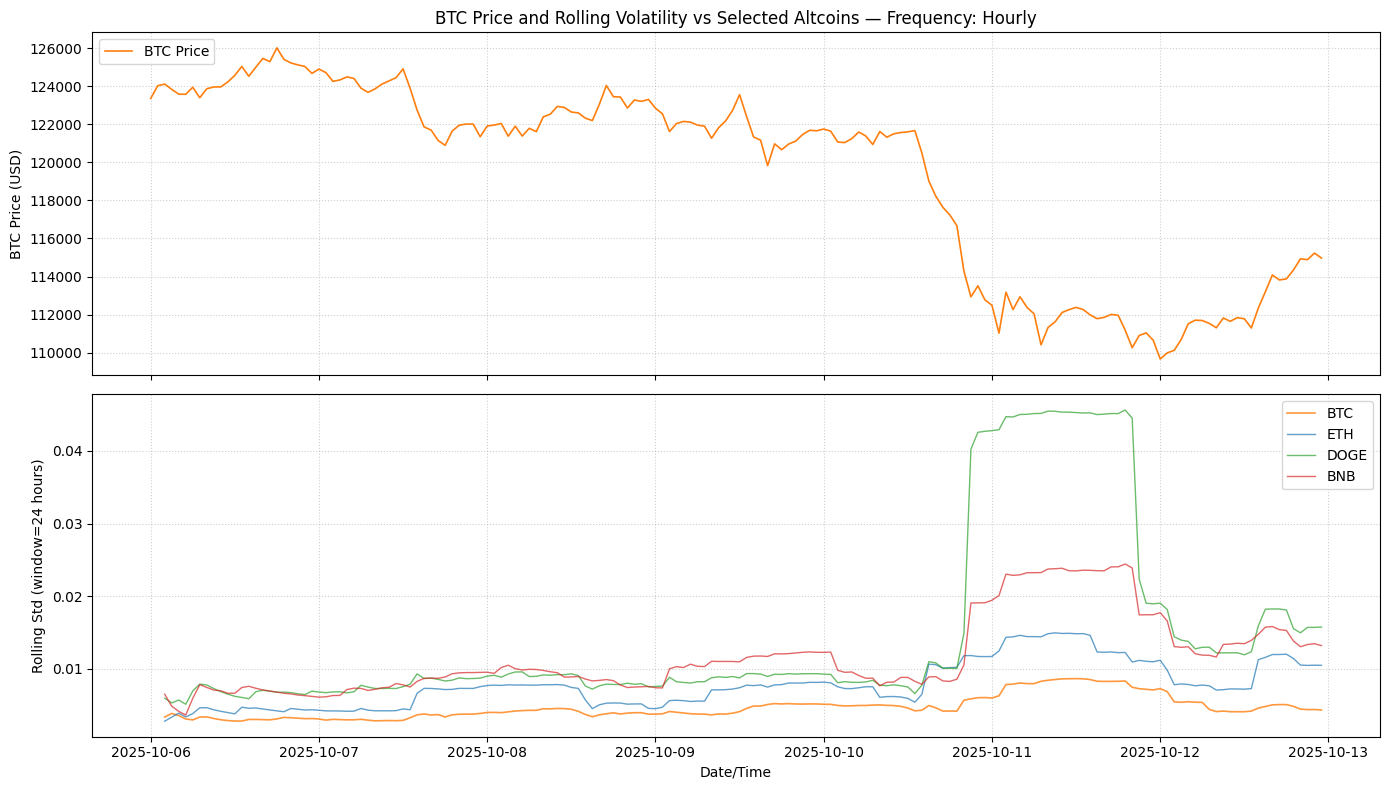

✓ กราฟรวมเสร็จแล้ว


In [9]:
print("--- Step 01 Visuals: Price & Volatility Overview ---")

window = ROLLING_WINDOW
if window is None:
    window = FREQ_CONFIG[FREQUENCY]['rolling_window']

preferred_highlight = ['ETH', 'DOGE', 'XMR']
highlight_coins = [c for c in preferred_highlight if c in altcoins]
if len(highlight_coins) < 3:
    highlight_coins += [c for c in altcoins if c not in highlight_coins][:3 - len(highlight_coins)]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

ax1.plot(clean_view.index, clean_view['BTC'], color='tab:orange', linewidth=1.2, label='BTC Price')
ax1.set_ylabel('BTC Price (USD)')
ax1.set_title(f'BTC Price and Rolling Volatility vs Selected Altcoins — Frequency: {FREQUENCY}')
ax1.legend(loc='upper left')
ax1.grid(True, linestyle=':', alpha=0.6)

colors = ['tab:orange', 'tab:blue', 'tab:green', 'tab:red']
ax2.plot(returns_view.index, returns_view['BTC'].rolling(window, min_periods=2).std(),
         color='tab:orange', linewidth=1.2, label='BTC', alpha=0.8)
for i, coin in enumerate(highlight_coins):
    ax2.plot(returns_view.index, returns_view[coin].rolling(window, min_periods=2).std(),
             color=colors[i + 1], linewidth=1.0, label=coin, alpha=0.7)
ax2.set_ylabel(f'Rolling Std (window={window} {PERIOD_LABEL}s)')
ax2.set_xlabel('Date/Time')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig(f'DataOverview_BTC_Price_and_Volatility{FREQ_TAG}.png', dpi=300)
plt.show()
print("กราฟรวมเสร็จแล้ว")

## Step 01 visuals: per-coin price and volatility

In [10]:
window = ROLLING_WINDOW
for coin in altcoins:
    try:
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

        ax1.plot(clean_view.index, clean_view['BTC'], color='tab:orange', linewidth=1.2, label='BTC Price')
        ax1.set_ylabel('BTC Price (USD)')
        ax1.set_title(f'BTC Price and Rolling Volatility: BTC vs {coin} — Frequency: {FREQUENCY}')
        ax1.legend(loc='upper left')
        ax1.grid(True, linestyle=':', alpha=0.6)

        ax2.plot(returns_view.index, returns_view['BTC'].rolling(window, min_periods=2).std(),
                 color='tab:orange', linewidth=1.2, label='BTC', alpha=0.8)
        ax2.plot(returns_view.index, returns_view[coin].rolling(window, min_periods=2).std(),
                 color='tab:blue', linewidth=1.0, label=coin, alpha=0.7)
        ax2.set_ylabel(f'Rolling Std (window={window} {PERIOD_LABEL}s)')
        ax2.set_xlabel('Date/Time')
        ax2.legend(loc='upper right')
        ax2.grid(True, linestyle=':', alpha=0.6)

        plt.tight_layout()
        plt.savefig(f'DataOverview_Volatility_BTC_vs_{coin}{FREQ_TAG}.png', dpi=300)
        plt.show()
    except Exception as e:
        print(f"[ERROR] {coin}: {e}")
print(f"วาดกราฟราคา/ความผันผวนรายเหรียญครบ {len(altcoins)} เหรียญแล้ว\n")

Output hidden; open in https://colab.research.google.com to view.

## Step 01 visuals: normalised prices and log returns

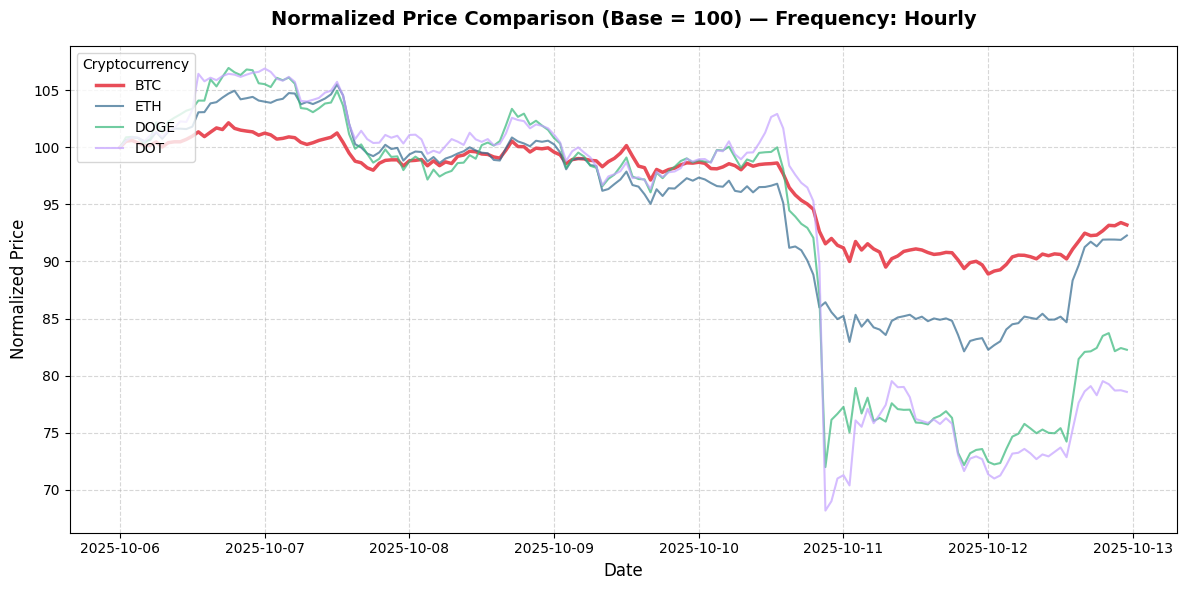

✓ บันทึกรูปภาพ 'Step01_Normalized_Price_Chart_Hourly.png' แล้ว


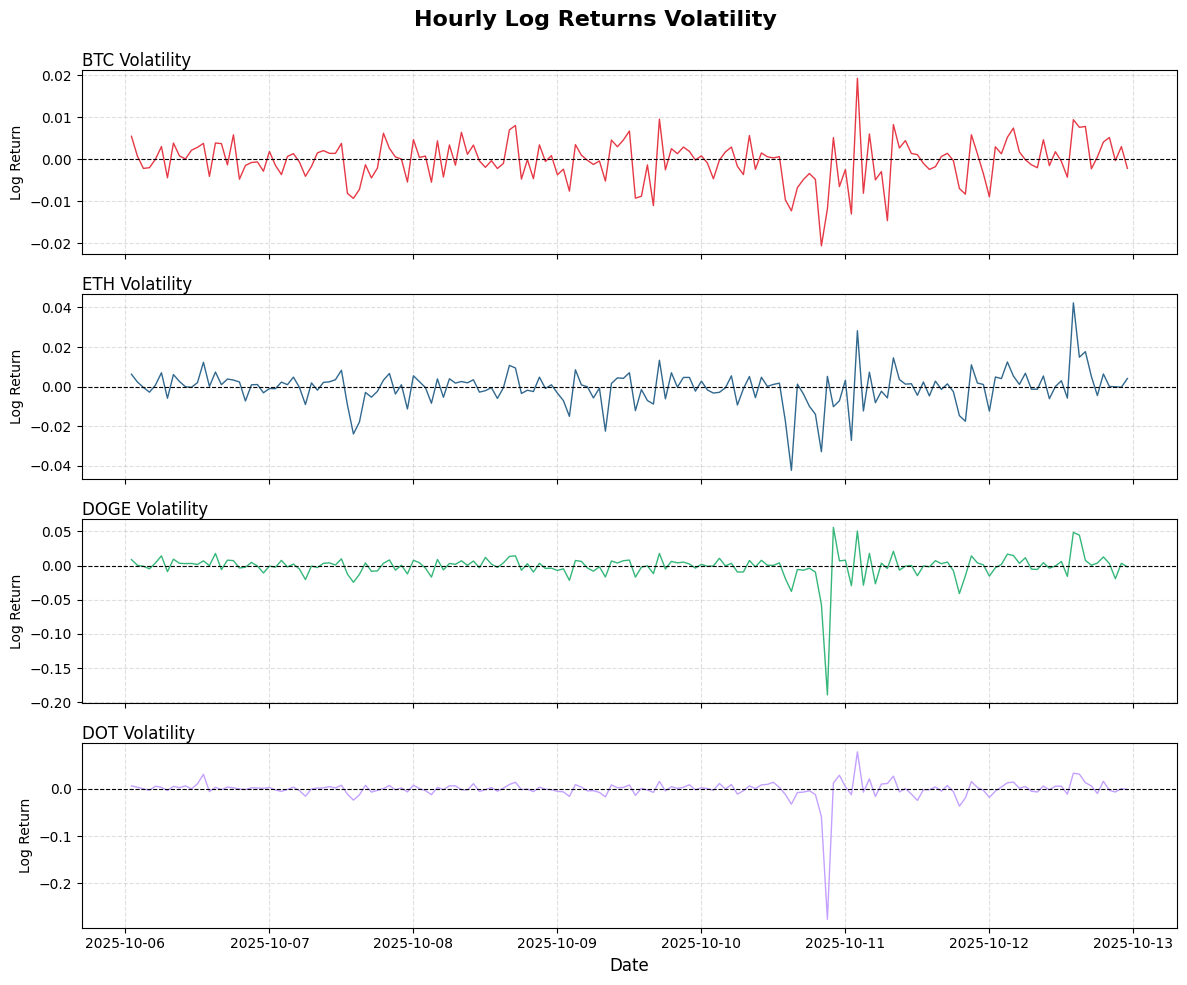

✓ บันทึกรูปภาพ 'Step01_Volatility_Chart_Hourly.png' แล้ว



In [11]:
preferred_selected = ['BTC', 'ETH', 'DOGE', 'DOT']
selected_coins = [c for c in preferred_selected if c == 'BTC' or c in altcoins]
if len(selected_coins) < 4:
    selected_coins += [c for c in altcoins if c not in selected_coins][:4 - len(selected_coins)]

df_selected = clean_view[selected_coins].dropna()
palette = ['#E63946', '#31688e', '#35b779', '#C4A1FF']
color_map = {coin: palette[i % len(palette)] for i, coin in enumerate(selected_coins)}

normalized_df = (df_selected / df_selected.iloc[0]) * 100
plt.figure(figsize=(12, 6))
for coin in selected_coins:
    plt.plot(normalized_df.index, normalized_df[coin], label=coin, color=color_map[coin],
              linewidth=2.5 if coin == 'BTC' else 1.5, alpha=0.9 if coin == 'BTC' else 0.7)
plt.title(f'Normalized Price Comparison (Base = 100) — Frequency: {FREQUENCY}', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Normalized Price', fontsize=12)
plt.legend(loc='upper left', title='Cryptocurrency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.tight_layout()
plt.savefig(f'Step01_Normalized_Price_Chart{FREQ_TAG}.png', dpi=300)
plt.show()
print(f"บันทึกรูปภาพ 'Step01_Normalized_Price_Chart{FREQ_TAG}.png' แล้ว")

log_returns_selected = np.log(df_selected / df_selected.shift(1)).dropna()
fig, axes = plt.subplots(nrows=len(selected_coins), ncols=1, figsize=(12, 10), sharex=True)
fig.suptitle(f'{FREQUENCY} Log Returns Volatility', fontsize=16, fontweight='bold', y=0.98)
for i, coin in enumerate(selected_coins):
    axes[i].plot(log_returns_selected.index, log_returns_selected[coin], color=color_map[coin], linewidth=1)
    axes[i].set_ylabel('Log Return', fontsize=10)
    axes[i].set_title(f'{coin} Volatility', fontsize=12, loc='left', pad=3)
    axes[i].axhline(0, color='black', linewidth=0.8, linestyle='--')
    axes[i].grid(True, linestyle='--', alpha=0.4)
plt.xlabel('Date', fontsize=12)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.savefig(f'Step01_Volatility_Chart{FREQ_TAG}.png', dpi=300)
plt.show()
print(f"บันทึกรูปภาพ 'Step01_Volatility_Chart{FREQ_TAG}.png' แล้ว\n")

## Step 01c: Stationarity test (ADF)

In [12]:
print("--- Step 01c: Stationarity Test (Augmented Dickey-Fuller) ---")


def adf_test(series):
    res = adfuller(series.dropna(), autolag='AIC', maxlag=ADF_MAXLAG)
    return res[0], res[1], res[2], res[3], res[4].get('5%', np.nan)


adf_results = []
for col in clean_data.columns:
    price_stat, price_p, price_lags, price_n, price_cv = adf_test(clean_data[col])
    return_stat, return_p, return_lags, return_n, return_cv = adf_test(returns[col])
    adf_results.append({
        'Coin': col,
        'ADF_Price': price_stat,
        'P_Price': price_p,
        'Lags_Price': price_lags, 'N_Obs_Price': price_n, 'CV5_Price': price_cv,
        'Stationary_Price': price_p < ALPHA,
        'ADF_Return': return_stat,
        'P_Return': return_p,
        'Lags_Return': return_lags, 'N_Obs_Return': return_n, 'CV5_Return': return_cv,
        'Stationary_Return': return_p < ALPHA,
        'Conclusion_Return': 'Stationary' if return_p < ALPHA else 'Non-stationary',
        'Frequency': FREQUENCY,
    })

adf_df = pd.DataFrame(adf_results).set_index('Coin')
adf_df.to_csv(f'Step01c_ADF_StationarityTest{FREQ_TAG}.csv')

num_price_stationary = int(adf_df['Stationary_Price'].sum())
num_return_stationary = int(adf_df['Stationary_Return'].sum())
print(f"Frequency: {FREQUENCY} | ADF Test: H0 = มี Unit Root (Non-stationary), ปฏิเสธ H0 เมื่อ p < {ALPHA}")
print(f"ราคาระดับ (Price Level) — Stationary: {num_price_stationary}/{len(adf_df)} เหรียญ")
print(f"Log Return               — Stationary: {num_return_stationary}/{len(adf_df)} เหรียญ\n")
print(adf_df.round(4).to_string())

if num_return_stationary < len(adf_df):
    non_stat = adf_df[~adf_df['Stationary_Return']].index.tolist()
    print(f"\nเหรียญที่ Log Return ยังไม่ Stationary ที่ระดับนัยสำคัญ 5%: {non_stat}")
    print("   (ควรตีความผล VAR/Granger Causality ของเหรียญกลุ่มนี้อย่างระมัดระวังเป็นพิเศษ)")

print("\nสรุป: ราคาระดับ (Price) ส่วนใหญ่ไม่ Stationary (มี Unit Root) ตามลักษณะทั่วไปของราคาสินทรัพย์การเงิน")
print("การแปลงเป็น Log Return (First Difference บนสเกล Log) ทำให้ข้อมูลส่วนใหญ่ Stationary แล้ว")
print("จึงใช้ Return แทน Price ในการรัน VAR/Granger Causality Test ต่อไปได้อย่างเหมาะสมตามทฤษฎี\n")

try:
    t03_rows = []
    for _coin, _r in adf_df.iterrows():
        for _label, _s, _p, _l, _n, _cv in [('Price', _r['ADF_Price'], _r['P_Price'], _r['Lags_Price'], _r['N_Obs_Price'], _r['CV5_Price']),
                                            ('Log Return', _r['ADF_Return'], _r['P_Return'], _r['Lags_Return'], _r['N_Obs_Return'], _r['CV5_Return'])]:
            t03_rows.append({
                'Cryptocurrency': _coin, 'Data_Type': _label, 'ADF_Statistic': _s, 'p_value': _p,
                'Critical_Value_5pct': _cv, 'Lags_Used': int(_l), 'N_Observations': int(_n), 'Alpha': ALPHA,
                'Result': 'Stationary (reject H0)' if _p < ALPHA else 'Non-stationary (fail to reject H0)',
            })
    register_table('T03', pd.DataFrame(t03_rows),
                   note=f'H0: มี Unit Root | จำนวน Lag เลือกด้วย AIC (autolag){f", จำกัด maxlag = {ADF_MAXLAG}" if ADF_MAXLAG else ""} | ระดับนัยสำคัญ {ALPHA}')
except Exception as e:
    register_unavailable('T03', f'{type(e).__name__}: {e}')

--- Step 01c: Stationarity Test (Augmented Dickey-Fuller) ---
Frequency: Hourly | ADF Test: H0 = มี Unit Root (Non-stationary), ปฏิเสธ H0 เมื่อ p < 0.05
ราคาระดับ (Price Level) — Stationary: 0/22 เหรียญ
Log Return               — Stationary: 22/22 เหรียญ

      ADF_Price  P_Price  Lags_Price  N_Obs_Price  CV5_Price  Stationary_Price  ADF_Return  P_Return  Lags_Return  N_Obs_Return  CV5_Return  Stationary_Return Conclusion_Return Frequency
Coin                                                                                                                                                                                      
BTC     -0.9059   0.7860           4          163    -2.8794             False     -5.5777    0.0000            3           163     -2.8794               True        Stationary    Hourly
ETH     -1.2123   0.6683           5          162    -2.8796             False     -4.1904    0.0007            4           162     -2.8796               True        Stationary    Hou

,Cryptocurrency,Data_Type,ADF_Statistic,p_value,Critical_Value_5pct,Lags_Used,N_Observations,Alpha,Result
0,BTC,Price,-0.905943,0.786009,-2.879441,4,163,0.05,Non-stationary (fail to reject H0)
1,BTC,Log Return,-5.577740,0.000001,-2.879441,3,163,0.05,Stationary (reject H0)
2,ETH,Price,-1.212284,0.668289,-2.879552,5,162,0.05,Non-stationary (fail to reject H0)
3,ETH,Log Return,-4.190352,0.000684,-2.879552,4,162,0.05,Stationary (reject H0)
4,BNB,Price,-1.552168,0.507565,-2.879008,0,167,0.05,Non-stationary (fail to reject H0)
5,BNB,Log Return,-12.207699,0.000000,-2.879114,0,166,0.05,Stationary (reject H0)
6,XRP,Price,-1.136988,0.700098,-2.879441,4,163,0.05,Non-stationary (fail to reject H0)
7,XRP,Log Return,-4.527617,0.000175,-2.879665,5,161,0.05,Stationary (reject H0)
8,SOL,Price,-0.996371,0.754585,-2.879221,2,165,0.05,Non-stationary (fail to reject H0)
9,SOL,Log Return,-7.488149,0.000000,-2.879221,1,165,0.05,Stationary (reject H0)


## Step 01d: Correlation analysis

--- Step 01d: Correlation Analysis ---


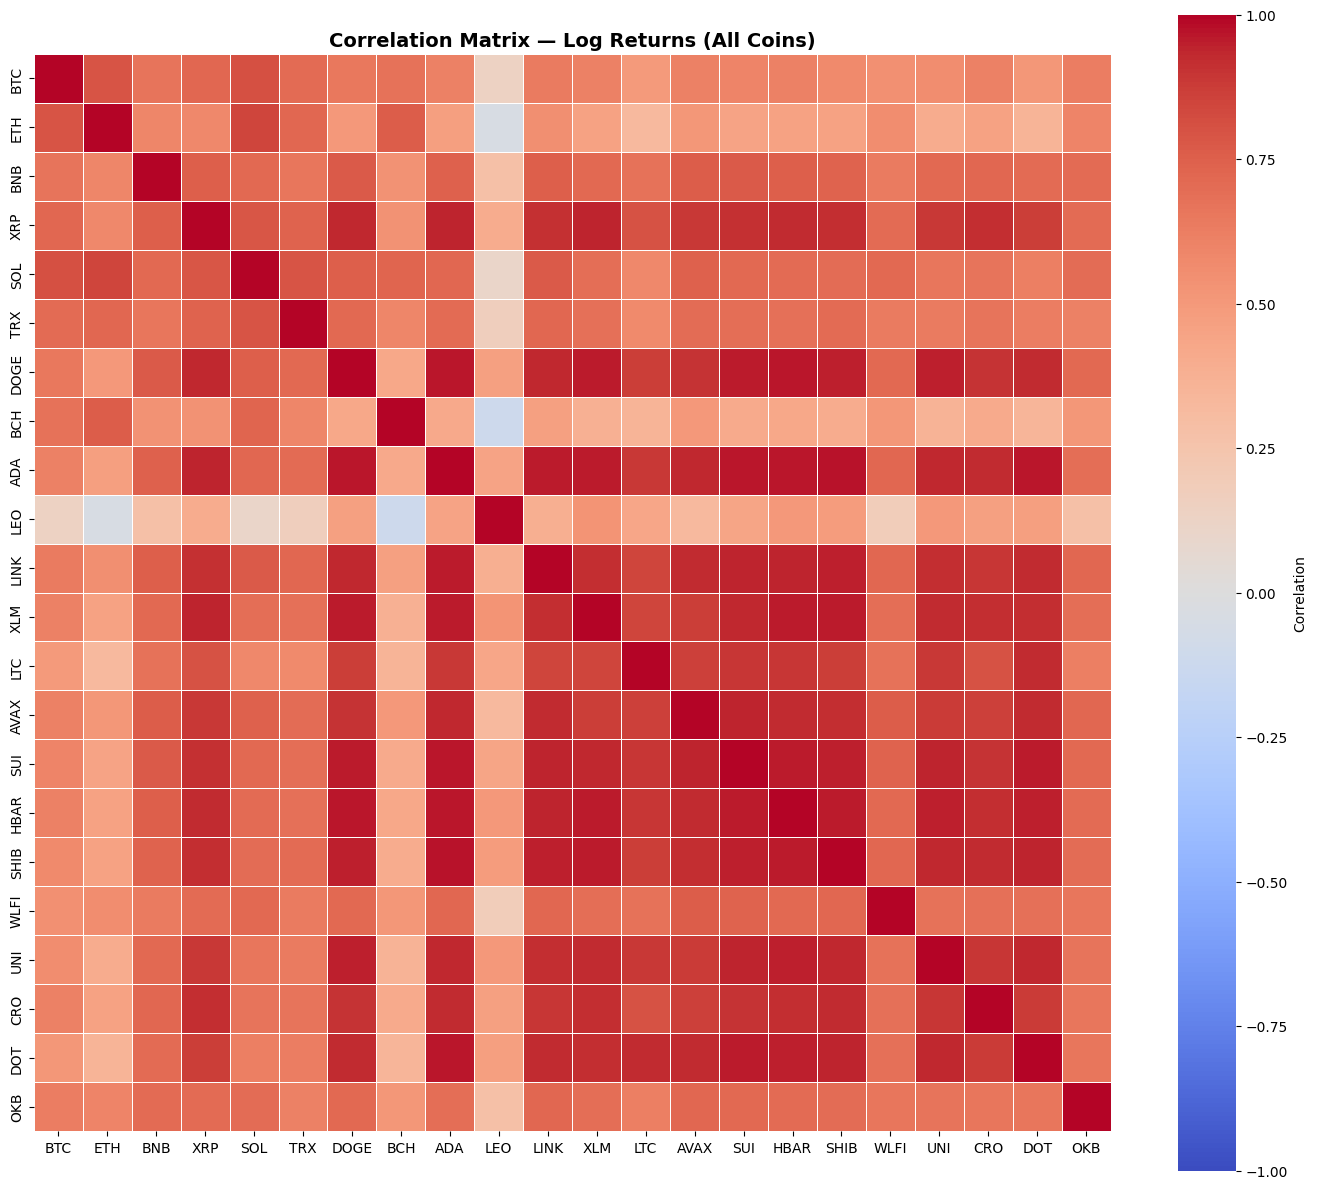

✓ บันทึกรูปภาพ 'Step01d_Correlation_Heatmap.png' แล้ว


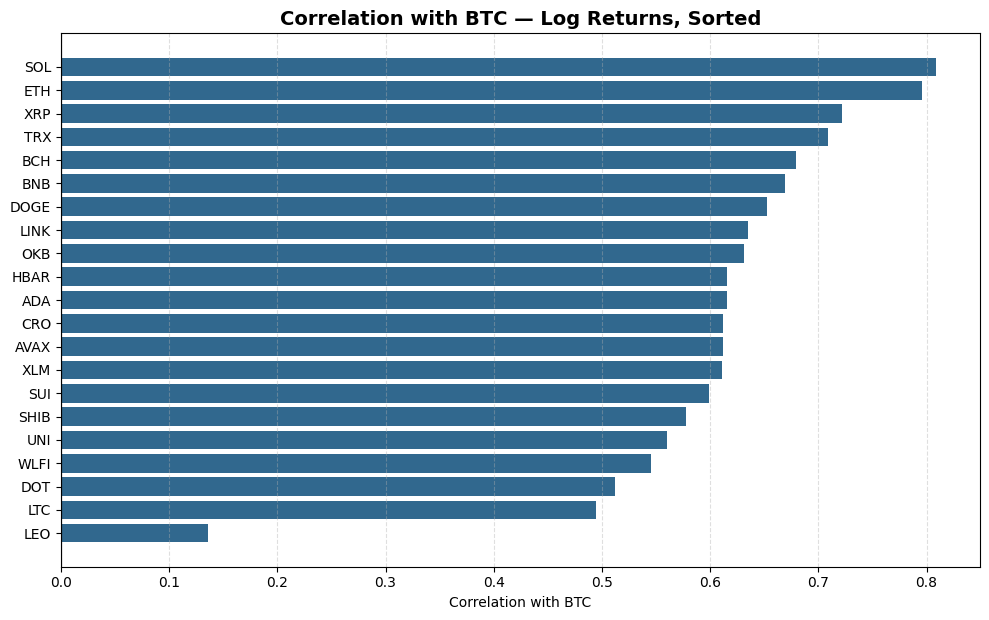

✓ บันทึกรูปภาพ 'Step01d_Correlation_with_BTC.png' แล้ว

เหรียญที่มี Correlation กับ BTC สูงสุด: SOL (0.8089)
เหรียญที่มี Correlation กับ BTC ต่ำสุด: LEO (0.1359)



In [13]:
print("--- Step 01d: Correlation Analysis ---")

corr_matrix = returns.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            annot=corr_matrix.shape[0] <= 15, fmt='.2f', square=True,
            linewidths=0.5, cbar_kws={'label': 'Correlation'})
plt.title('Correlation Matrix — Log Returns (All Coins)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('Step01d_Correlation_Heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print("บันทึกรูปภาพ 'Step01d_Correlation_Heatmap.png' แล้ว")

btc_corr_sorted = features.loc[altcoins, 'Corr_with_BTC'].sort_values(ascending=False)

plt.figure(figsize=(10, max(6, len(btc_corr_sorted) * 0.3)))
bar_colors = ['#31688e' if v >= 0 else '#E63946' for v in btc_corr_sorted.values]
plt.barh(btc_corr_sorted.index, btc_corr_sorted.values, color=bar_colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.gca().invert_yaxis()
plt.title('Correlation with BTC — Log Returns, Sorted', fontsize=14, fontweight='bold')
plt.xlabel('Correlation with BTC')
plt.grid(True, linestyle='--', alpha=0.4, axis='x')
plt.tight_layout()
plt.savefig('Step01d_Correlation_with_BTC.png', dpi=300, bbox_inches='tight')
plt.show()
print("บันทึกรูปภาพ 'Step01d_Correlation_with_BTC.png' แล้ว\n")

print(f"เหรียญที่มี Correlation กับ BTC สูงสุด: {btc_corr_sorted.index[0]} ({btc_corr_sorted.iloc[0]:.4f})")
print(f"เหรียญที่มี Correlation กับ BTC ต่ำสุด: {btc_corr_sorted.index[-1]} ({btc_corr_sorted.iloc[-1]:.4f})\n")

## Step 02: Optimal K and clustering

--- Step 02: Optimal K Selection + Dual-Clustering ---
จำนวนกลุ่มที่ใช้: K = 3 (กำหนดตามวัตถุประสงค์ของโครงงาน ทั้ง K-Means และ Hierarchical)
Silhouette ที่ K = 3: K-Means = 0.4673 | Hierarchical = 0.4673
K ที่ให้ Silhouette สูงสุดในช่วงที่ทดสอบ (เพื่อรายงาน ไม่ได้ใช้เลือก K): K-Means = 3 (0.4673) | Hierarchical = 3 (0.4673)
K ที่ใช้ ตรงกับ K ที่ Silhouette สูงสุดของ K-Means และ ตรงกับ ของ Hierarchical


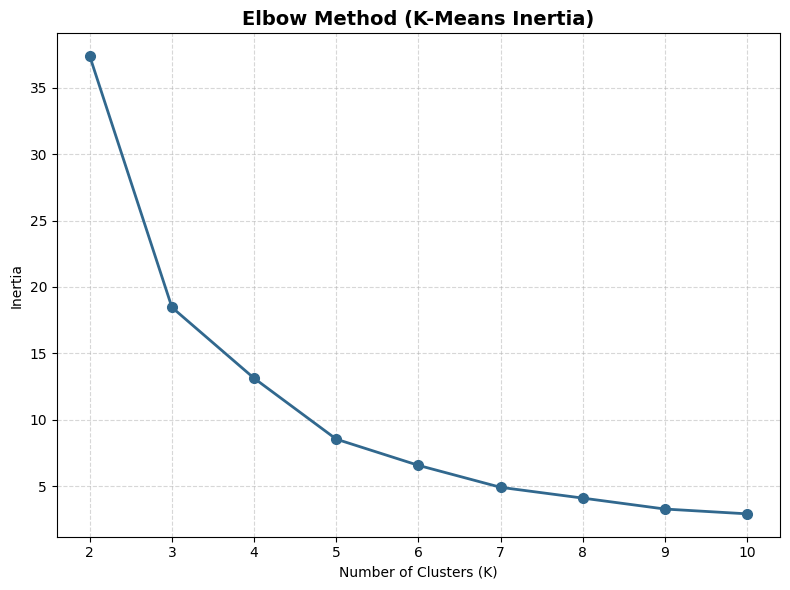

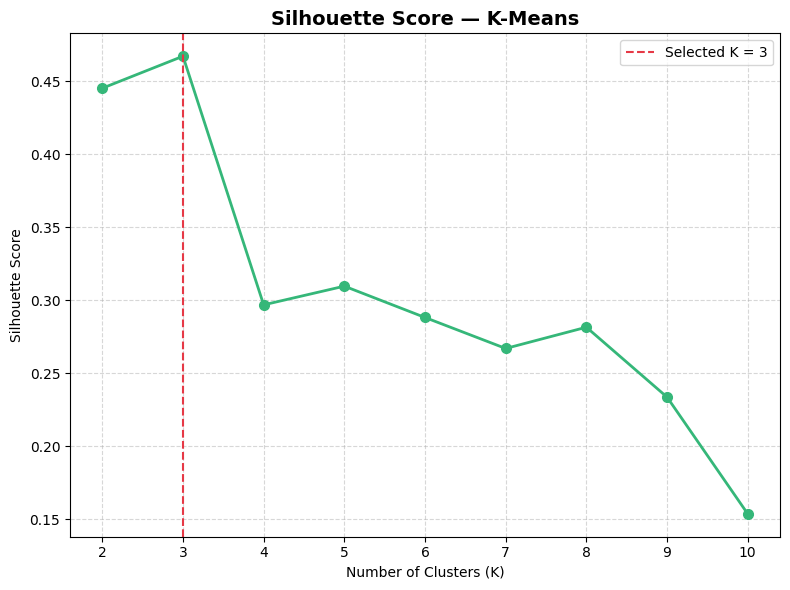

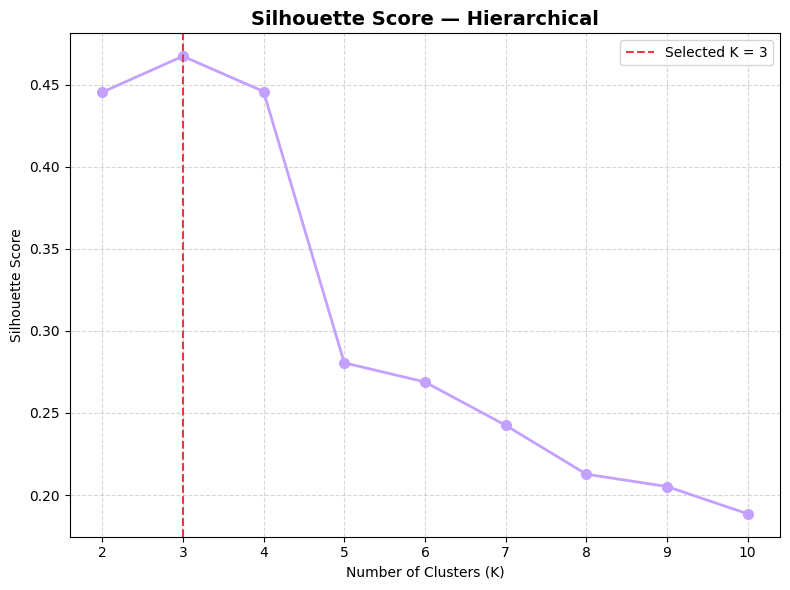

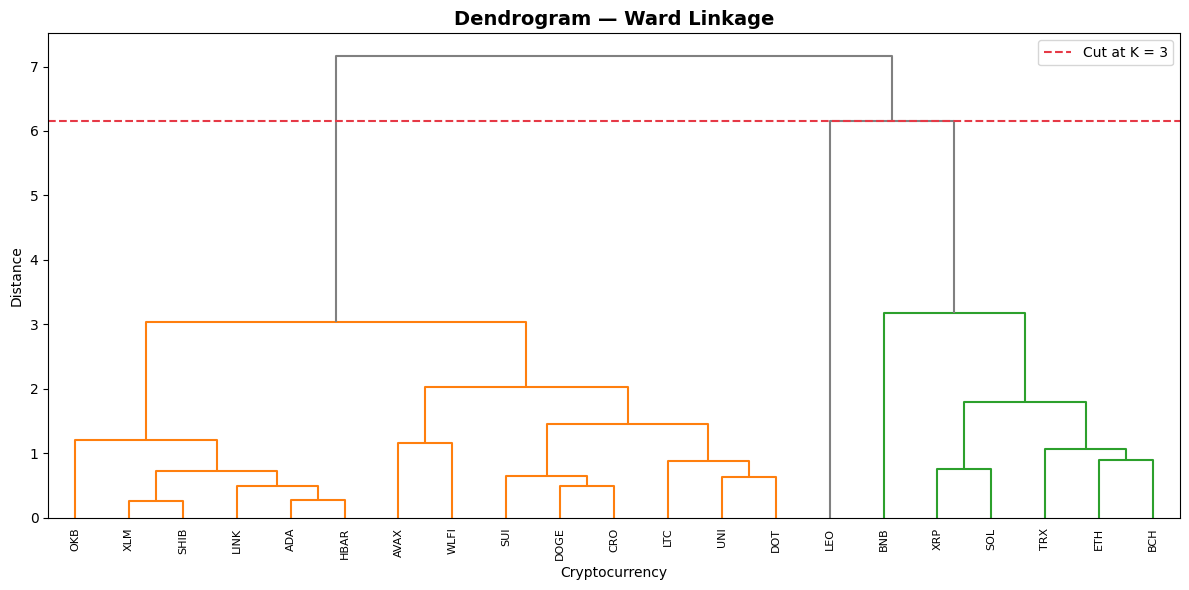

Done! Saved 4 separated image files (Step02_1 to Step02_4)
Done! Saved 'Step02_ClusteringResults_Hourly.csv'

  Step 02 Summary
  K-Means      → K = 3  (Silhouette = 0.4673)
  Hierarchical → K = 3  (Silhouette = 0.4673)


【ตาราง 4: Clustering Features】  21 แถว → Table_T04_Clustering_Features_Hourly.csv
หมายเหตุ: คอลัมน์ Z_* คือค่าที่ผ่าน StandardScaler แล้ว ซึ่งเป็น Input จริงของโมเดล Clustering


,Cryptocurrency,Mean_Return,Volatility,Corr_with_BTC,Z_Return_Mean,Z_Volatility,Z_Corr_with_BTC
0,ETH,-0.000481,0.009043,0.795594,0.779215,-1.134784,1.418335
1,BNB,0.000656,0.013199,0.669270,2.790754,-0.467178,0.457288
2,XRP,-0.000950,0.012938,0.721876,-0.050859,-0.509142,0.857501
3,SOL,-0.000893,0.010729,0.808877,0.051053,-0.864076,1.519387
4,TRX,-0.000323,0.003611,0.708556,1.058714,-2.007266,0.756170
5,DOGE,-0.001169,0.019866,0.652817,-0.437879,0.603668,0.332114
6,BCH,-0.000566,0.008505,0.678997,0.628636,-1.221165,0.531291
7,ADA,-0.001058,0.018634,0.615113,-0.241305,0.405697,0.045275
8,LEO,0.000009,0.003355,0.135940,1.645581,-2.048405,-3.600168
9,LINK,-0.000768,0.018507,0.634722,0.272332,0.385330,0.194456



【ตาราง 5: Silhouette Score Comparison】  9 แถว → Table_T05_Silhouette_Comparison_Hourly.csv
หมายเหตุ: ใช้ K = 3 ทั้งสองวิธีตามวัตถุประสงค์ของโครงงาน | K-Means: ตรงกับค่า K ที่ให้ Silhouette สูงสุด | Hierarchical: ตรงกับค่า K ที่ให้ Silhouette สูงสุด


,K,Silhouette_KMeans,Silhouette_Hierarchical,KMeans_Inertia,Selected_K,Max_Silhouette_KMeans,Max_Silhouette_Hierarchical
0,2,0.445357,0.445357,37.390431,False,False,False
1,3,0.467287,0.467287,18.462117,True,True,True
2,4,0.296931,0.445789,13.120873,False,False,False
3,5,0.309742,0.280548,8.532679,False,False,False
4,6,0.288281,0.268882,6.557277,False,False,False
5,7,0.267051,0.242492,4.902545,False,False,False
6,8,0.281622,0.212717,4.090819,False,False,False
7,9,0.233718,0.205215,3.266177,False,False,False
8,10,0.153749,0.188571,2.904507,False,False,False



【ตาราง 6: Clustering Results】  21 แถว → Table_T06_Clustering_Results_Hourly.csv
หมายเหตุ: หมายเลขกลุ่มเป็นเพียงป้ายกำกับ (K-Means นับจาก 0, Hierarchical นับจาก 1) ไม่ได้บอกลำดับความสำคัญ และสองวิธีไม่จำเป็นต้องใช้หมายเลขตรงกัน


,Cryptocurrency,KMeans_Cluster,Hierarchical_Cluster,Mean_Return,Volatility,Corr_with_BTC
0,ETH,2,2,-0.000481,0.009043,0.795594
1,BNB,2,2,0.000656,0.013199,0.669270
2,XRP,2,2,-0.000950,0.012938,0.721876
3,SOL,2,2,-0.000893,0.010729,0.808877
4,TRX,2,2,-0.000323,0.003611,0.708556
5,DOGE,0,1,-0.001169,0.019866,0.652817
6,BCH,2,2,-0.000566,0.008505,0.678997
7,ADA,0,1,-0.001058,0.018634,0.615113
8,LEO,1,3,0.000009,0.003355,0.135940
9,LINK,0,1,-0.000768,0.018507,0.634722



【ตาราง 6b: สรุปจำนวนเหรียญและลักษณะของแต่ละกลุ่ม】  6 แถว → Table_T06b_Cluster_Profile_Summary_Hourly.csv
หมายเหตุ: Z_* = (ค่าเฉลี่ยกลุ่ม - ค่าเฉลี่ยรวม 27 เหรียญ) / SD รวม | คำบรรยายใช้เกณฑ์ 0.25 SD ซึ่งกำหนดเองเพื่อสรุปให้อ่านง่าย ไม่ใช่การทดสอบทางสถิติ


,Method,Cluster,N_Coins,Coins,Mean_Return_avg,Volatility_avg,Corr_with_BTC_avg,Z_Mean_Return,Z_Volatility,Z_Corr_with_BTC,Description
0,K-Means,0,14,"DOGE, ADA, LINK, XLM, LTC, AVAX, SUI, HBAR, SH...",-0.001200,0.019778,0.590950,-0.481195,0.575225,-0.135218,Volatility สูงกว่าค่าเฉลี่ยรวม (+0.58 SD); Cor...
1,K-Means,1,1,LEO,0.000009,0.003355,0.135940,1.605922,-1.999039,-3.513404,Volatility ต่ำกว่าค่าเฉลี่ยรวม (-2.00 SD); Cor...
2,K-Means,2,6,"ETH, BNB, XRP, SOL, TRX, BCH",-0.000426,0.009671,0.730528,0.855135,-1.009017,0.901076,Volatility ต่ำกว่าค่าเฉลี่ยรวม (-1.01 SD); Cor...
3,Hierarchical,1,14,"DOGE, ADA, LINK, XLM, LTC, AVAX, SUI, HBAR, SH...",-0.001200,0.019778,0.590950,-0.481195,0.575225,-0.135218,Volatility สูงกว่าค่าเฉลี่ยรวม (+0.58 SD); Cor...
4,Hierarchical,2,6,"ETH, BNB, XRP, SOL, TRX, BCH",-0.000426,0.009671,0.730528,0.855135,-1.009017,0.901076,Volatility ต่ำกว่าค่าเฉลี่ยรวม (-1.01 SD); Cor...
5,Hierarchical,3,1,LEO,0.000009,0.003355,0.135940,1.605922,-1.999039,-3.513404,Volatility ต่ำกว่าค่าเฉลี่ยรวม (-2.00 SD); Cor...



【ตาราง 6c: Cross-Tabulation K-Means vs Hierarchical】  3 แถว → Table_T06c_KMeans_vs_Hierarchical_Crosstab_Hourly.csv


,K-Means \ Hierarchical,Hierarchical 1,Hierarchical 2,Hierarchical 3
0,K-Means 0,14,0,0
1,K-Means 1,0,0,1
2,K-Means 2,0,6,0


In [14]:
print("--- Step 02: Optimal K Selection + Dual-Clustering ---")

k_range = range(2, 11)
assert N_CLUSTERS in k_range, f'N_CLUSTERS ต้องอยู่ในช่วง K ที่ทดสอบ {list(k_range)}'

inertia_list = []
sil_kmeans_list = []
sil_hierarchical_list = []
Z = linkage(scaled_df, method='ward')

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_km = km.fit_predict(scaled_df)
    inertia_list.append(km.inertia_)
    sil_kmeans_list.append(silhouette_score(scaled_df, labels_km))

    labels_hc = fcluster(Z, t=k, criterion='maxclust')
    sil_hierarchical_list.append(silhouette_score(scaled_df, labels_hc))

best_k_kmeans = N_CLUSTERS
best_k_hierarchical = N_CLUSTERS
sil_best_k_kmeans = k_range.start + int(np.argmax(sil_kmeans_list))
sil_best_k_hierarchical = k_range.start + int(np.argmax(sil_hierarchical_list))
sil_at_k_kmeans = sil_kmeans_list[N_CLUSTERS - k_range.start]
sil_at_k_hierarchical = sil_hierarchical_list[N_CLUSTERS - k_range.start]

print(f"จำนวนกลุ่มที่ใช้: K = {N_CLUSTERS} (กำหนดตามวัตถุประสงค์ของโครงงาน ทั้ง K-Means และ Hierarchical)")
print(f"Silhouette ที่ K = {N_CLUSTERS}: K-Means = {sil_at_k_kmeans:.4f} | Hierarchical = {sil_at_k_hierarchical:.4f}")
print(f"K ที่ให้ Silhouette สูงสุดในช่วงที่ทดสอบ (เพื่อรายงาน ไม่ได้ใช้เลือก K): K-Means = {sil_best_k_kmeans} ({max(sil_kmeans_list):.4f}) | "
      f"Hierarchical = {sil_best_k_hierarchical} ({max(sil_hierarchical_list):.4f})")
print("K ที่ใช้ " + ("ตรงกับ" if sil_best_k_kmeans == N_CLUSTERS else "ไม่ตรงกับ") + " K ที่ Silhouette สูงสุดของ K-Means และ "
      + ("ตรงกับ" if sil_best_k_hierarchical == N_CLUSTERS else "ไม่ตรงกับ") + " ของ Hierarchical")

plt.figure(figsize=(8, 6))
plt.plot(list(k_range), inertia_list, marker='o', color='#31688e', linewidth=2, markersize=7)
plt.title('Elbow Method (K-Means Inertia)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('Step02_1_Elbow_Method.png', dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(8, 6))
plt.plot(list(k_range), sil_kmeans_list, marker='o', color='#35b779', linewidth=2, markersize=7)
plt.axvline(x=best_k_kmeans, color='#E63946', linestyle='--', linewidth=1.5, label=f'Selected K = {best_k_kmeans}')
plt.title('Silhouette Score — K-Means', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('Step02_2_Silhouette_KMeans.png', dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(8, 6))
plt.plot(list(k_range), sil_hierarchical_list, marker='o', color='#C4A1FF', linewidth=2, markersize=7)
plt.axvline(x=best_k_hierarchical, color='#E63946', linestyle='--', linewidth=1.5, label=f'Selected K = {best_k_hierarchical}')
plt.title('Silhouette Score — Hierarchical', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('Step02_3_Silhouette_Hierarchical.png', dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(12, 6))
dendrogram(
    Z,
    labels=scaled_df.index.tolist(),
    leaf_rotation=90,
    leaf_font_size=8,
    color_threshold=Z[-(best_k_hierarchical - 1), 2],
    above_threshold_color='gray'
)
plt.axhline(y=Z[-(best_k_hierarchical - 1), 2], color='#E63946', linestyle='--', linewidth=1.5,
            label=f'Cut at K = {best_k_hierarchical}')
plt.title('Dendrogram — Ward Linkage', fontsize=14, fontweight='bold')
plt.xlabel('Cryptocurrency')
plt.ylabel('Distance')
plt.legend()
plt.tight_layout()
plt.savefig('Step02_4_Dendrogram.png', dpi=300, bbox_inches='tight')
plt.show()
print("Done! Saved 4 separated image files (Step02_1 to Step02_4)")

kmeans = KMeans(n_clusters=best_k_kmeans, random_state=42, n_init=10)
alt_features['KMeans_Cluster'] = kmeans.fit_predict(scaled_df)
alt_features['Hierarchical_Cluster'] = fcluster(Z, t=best_k_hierarchical, criterion='maxclust')

alt_features.to_csv(f'Step02_ClusteringResults{FREQ_TAG}.csv')
print(f"Done! Saved 'Step02_ClusteringResults{FREQ_TAG}.csv'")

print(f"\n{'='*45}")
print(f"  Step 02 Summary")
print(f"{'='*45}")
print(f"  K-Means      → K = {best_k_kmeans}  (Silhouette = {sil_at_k_kmeans:.4f})")
print(f"  Hierarchical → K = {best_k_hierarchical}  (Silhouette = {sil_at_k_hierarchical:.4f})")
print(f"{'='*45}\n")

try:
    t04 = alt_features[['Return_Mean', 'Volatility', 'Corr_with_BTC']].copy()
    t04.columns = ['Mean_Return', 'Volatility', 'Corr_with_BTC']
    for _c in scaled_df.columns:
        t04[f'Z_{_c}'] = scaled_df[_c]
    t04.insert(0, 'Cryptocurrency', t04.index)
    register_table('T04', t04.reset_index(drop=True),
                   note='คอลัมน์ Z_* คือค่าที่ผ่าน StandardScaler แล้ว ซึ่งเป็น Input จริงของโมเดล Clustering')
except Exception as e:
    register_unavailable('T04', f'{type(e).__name__}: {e}')

try:
    t05 = pd.DataFrame({'K': list(k_range), 'Silhouette_KMeans': sil_kmeans_list,
                        'Silhouette_Hierarchical': sil_hierarchical_list, 'KMeans_Inertia': inertia_list})
    t05['Selected_K'] = t05['K'] == N_CLUSTERS
    t05['Max_Silhouette_KMeans'] = t05['K'] == sil_best_k_kmeans
    t05['Max_Silhouette_Hierarchical'] = t05['K'] == sil_best_k_hierarchical
    _km_txt = 'ตรงกับค่า K ที่ให้ Silhouette สูงสุด' if sil_best_k_kmeans == N_CLUSTERS else f'ไม่ใช่ K ที่ให้ Silhouette สูงสุด (สูงสุดที่ K = {sil_best_k_kmeans})'
    _hc_txt = 'ตรงกับค่า K ที่ให้ Silhouette สูงสุด' if sil_best_k_hierarchical == N_CLUSTERS else f'ไม่ใช่ K ที่ให้ Silhouette สูงสุด (สูงสุดที่ K = {sil_best_k_hierarchical})'
    register_table('T05', t05,
                   note=f'ใช้ K = {N_CLUSTERS} ทั้งสองวิธีตามวัตถุประสงค์ของโครงงาน | K-Means: {_km_txt} | Hierarchical: {_hc_txt}')
except Exception as e:
    register_unavailable('T05', f'{type(e).__name__}: {e}')

try:
    t06 = alt_features[['KMeans_Cluster', 'Hierarchical_Cluster', 'Return_Mean', 'Volatility', 'Corr_with_BTC']].copy()
    t06.columns = ['KMeans_Cluster', 'Hierarchical_Cluster', 'Mean_Return', 'Volatility', 'Corr_with_BTC']
    t06.insert(0, 'Cryptocurrency', t06.index)
    register_table('T06', t06.reset_index(drop=True),
                   note='หมายเลขกลุ่มเป็นเพียงป้ายกำกับ (K-Means นับจาก 0, Hierarchical นับจาก 1) ไม่ได้บอกลำดับความสำคัญ และสองวิธีไม่จำเป็นต้องใช้หมายเลขตรงกัน')
except Exception as e:
    register_unavailable('T06', f'{type(e).__name__}: {e}')

try:
    _feat = ['Return_Mean', 'Volatility', 'Corr_with_BTC']
    _all_mean, _all_sd = alt_features[_feat].mean(), alt_features[_feat].std()

    def _rel(z):
        return 'สูงกว่า' if z >= 0.25 else ('ต่ำกว่า' if z <= -0.25 else 'ใกล้เคียง')

    t06b_rows = []
    for _method in ['KMeans_Cluster', 'Hierarchical_Cluster']:
        for _cid in sorted(alt_features[_method].unique()):
            _sub = alt_features[alt_features[_method] == _cid]
            _m = _sub[_feat].mean()
            _z = (_m - _all_mean) / _all_sd
            t06b_rows.append({
                'Method': 'K-Means' if _method == 'KMeans_Cluster' else 'Hierarchical', 'Cluster': int(_cid), 'N_Coins': len(_sub),
                'Coins': ', '.join(_sub.index), 'Mean_Return_avg': _m['Return_Mean'], 'Volatility_avg': _m['Volatility'],
                'Corr_with_BTC_avg': _m['Corr_with_BTC'], 'Z_Mean_Return': _z['Return_Mean'], 'Z_Volatility': _z['Volatility'],
                'Z_Corr_with_BTC': _z['Corr_with_BTC'],
                'Description': (f"Volatility {_rel(_z['Volatility'])}ค่าเฉลี่ยรวม ({_z['Volatility']:+.2f} SD); "
                                f"Correlation กับ BTC {_rel(_z['Corr_with_BTC'])}ค่าเฉลี่ยรวม ({_z['Corr_with_BTC']:+.2f} SD); "
                                f"Mean Return {_rel(_z['Return_Mean'])}ค่าเฉลี่ยรวม ({_z['Return_Mean']:+.2f} SD)"),
            })
    register_table('T06b', pd.DataFrame(t06b_rows),
                   note='Z_* = (ค่าเฉลี่ยกลุ่ม - ค่าเฉลี่ยรวม 27 เหรียญ) / SD รวม | คำบรรยายใช้เกณฑ์ 0.25 SD ซึ่งกำหนดเองเพื่อสรุปให้อ่านง่าย ไม่ใช่การทดสอบทางสถิติ')
except Exception as e:
    register_unavailable('T06b', f'{type(e).__name__}: {e}')

try:
    _ct = pd.crosstab(alt_features['KMeans_Cluster'], alt_features['Hierarchical_Cluster'])
    _ct.index = [f'K-Means {i}' for i in _ct.index]
    _ct.columns = [f'Hierarchical {c}' for c in _ct.columns]
    register_table('T06c', _ct.reset_index().rename(columns={'index': 'K-Means \\ Hierarchical'}))
except Exception as e:
    register_unavailable('T06c', f'{type(e).__name__}: {e}')

## Step 02 visuals: cluster scatter plots and dendrogram

--- Step 02 Visuals: Cluster Scatter Plots ---


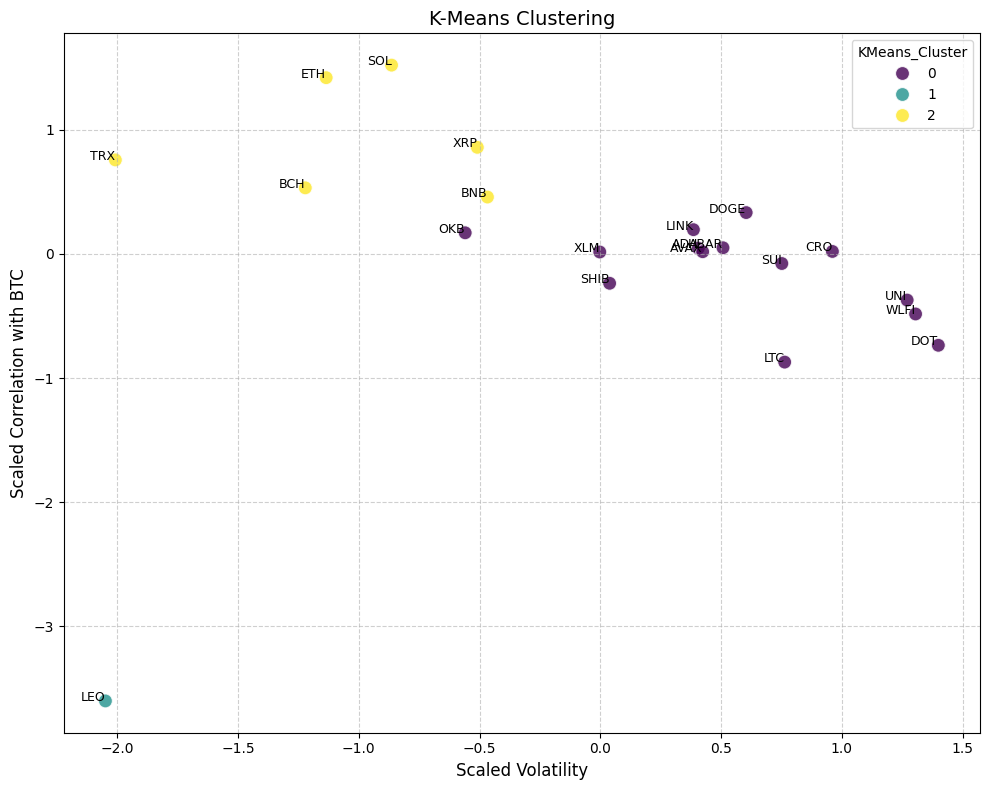

✓ บันทึกรูปภาพ 'Step02_KMeans_Clustering_Visualization.png' แล้ว


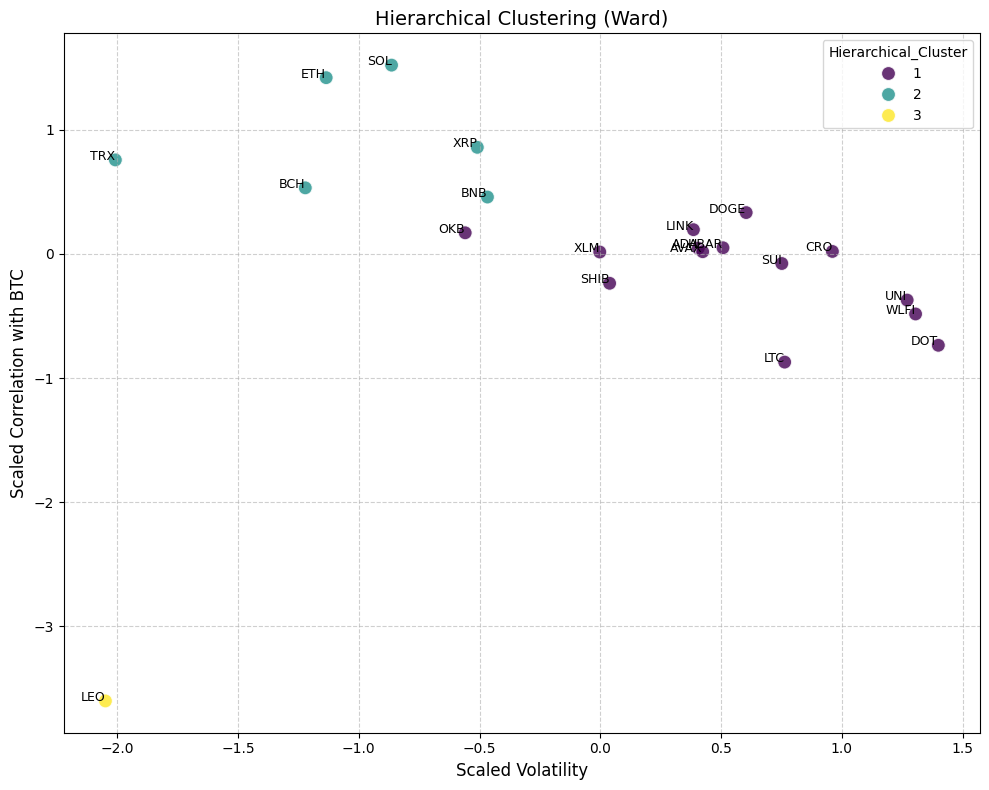

✓ บันทึกรูปภาพ 'Step02_Hierarchical_Clustering_Visualization.png' แล้ว


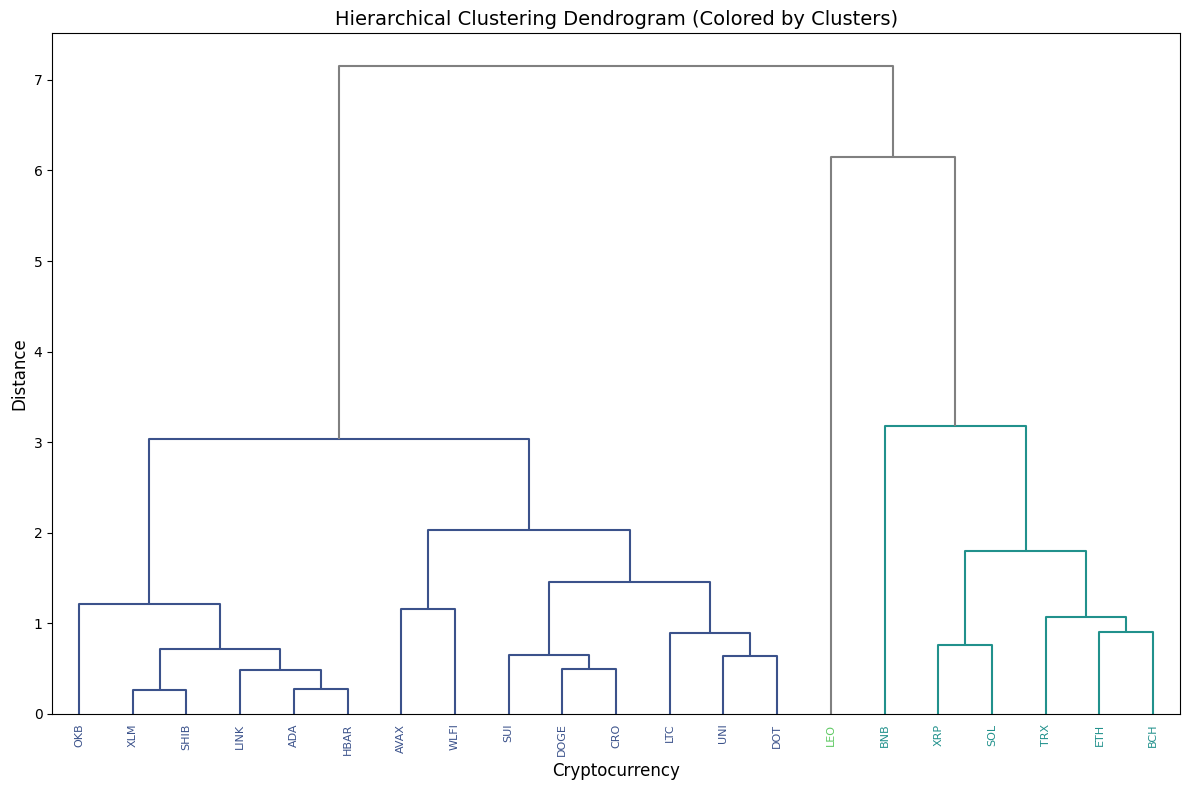

✓ บันทึกรูปภาพ 'Step02_Dendrogram_Visualization.png' แล้ว



In [15]:
print("--- Step 02 Visuals: Cluster Scatter Plots ---")

plot_df = scaled_df.copy()
plot_df['KMeans_Cluster'] = alt_features['KMeans_Cluster']
plot_df['Hierarchical_Cluster'] = alt_features['Hierarchical_Cluster']

plt.figure(figsize=(10, 8))
sns.scatterplot(x='Volatility', y='Corr_with_BTC', hue='KMeans_Cluster', palette='viridis',
                 data=plot_df, s=100, alpha=0.8, edgecolor='w')
for i, coin in enumerate(plot_df.index):
    plt.text(plot_df['Volatility'].iloc[i], plot_df['Corr_with_BTC'].iloc[i], coin, fontsize=9, ha='right')
plt.title('K-Means Clustering', fontsize=14)
plt.xlabel('Scaled Volatility', fontsize=12)
plt.ylabel('Scaled Correlation with BTC', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('Step02_KMeans_Clustering_Visualization.png', dpi=300)
plt.show()
print("บันทึกรูปภาพ 'Step02_KMeans_Clustering_Visualization.png' แล้ว")

plt.figure(figsize=(10, 8))
sns.scatterplot(x='Volatility', y='Corr_with_BTC', hue='Hierarchical_Cluster', palette='viridis',
                 data=plot_df, s=100, alpha=0.8, edgecolor='w')
for i, coin in enumerate(plot_df.index):
    plt.text(plot_df['Volatility'].iloc[i], plot_df['Corr_with_BTC'].iloc[i], coin, fontsize=9, ha='right')
plt.title('Hierarchical Clustering (Ward)', fontsize=14)
plt.xlabel('Scaled Volatility', fontsize=12)
plt.ylabel('Scaled Correlation with BTC', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('Step02_Hierarchical_Clustering_Visualization.png', dpi=300)
plt.show()
print("บันทึกรูปภาพ 'Step02_Hierarchical_Clustering_Visualization.png' แล้ว")

num_clusters = plot_df['Hierarchical_Cluster'].nunique()
viridis_colors = [mcolors.to_hex(c) for c in sns.color_palette('viridis', n_colors=num_clusters)]
set_link_color_palette(viridis_colors)
color_threshold = Z[-num_clusters + 1, 2] if num_clusters > 1 else 0

plt.figure(figsize=(12, 8))
dn = dendrogram(
    Z,
    labels=scaled_df.index.tolist(),
    leaf_rotation=90,
    leaf_font_size=8,
    color_threshold=color_threshold,
    above_threshold_color='gray'
)

cluster_colors = sns.color_palette('viridis', n_colors=num_clusters)
cluster_id_to_color = {cid: cluster_colors[i] for i, cid in enumerate(sorted(plot_df['Hierarchical_Cluster'].unique()))}
leaf_colors = [cluster_id_to_color[plot_df.loc[leaf, 'Hierarchical_Cluster']] for leaf in dn['ivl']]

ax = plt.gca()
for xlbl, color in zip(ax.get_xticklabels(), leaf_colors):
    xlbl.set_color(color)

plt.title('Hierarchical Clustering Dendrogram (Colored by Clusters)', fontsize=14)
plt.xlabel('Cryptocurrency', fontsize=12)
plt.ylabel('Distance', fontsize=12)
plt.tight_layout()
plt.savefig('Step02_Dendrogram_Visualization.png', dpi=300)
plt.show()
print("บันทึกรูปภาพ 'Step02_Dendrogram_Visualization.png' แล้ว\n")

## Step 03: Granger causality (Gretl-style lag selection)

In [16]:
print("--- Step 03: Granger Causality Test (Gretl Style Lag Selection) ---")


def compute_gretl_lag_selection(df_pair, max_lag):
    """Compute log-likelihood, AIC, BIC and HQC of a VAR for every lag from 1 to max_lag.

    The sample size is held constant across lags (Gretl convention) so the criteria are comparable."""
    T_total = len(df_pair)
    T = T_total - max_lag
    m = df_pair.shape[1]

    results = []
    prev_llf = None
    for lag in range(1, max_lag + 1):
        df_subset = df_pair.iloc[max_lag - lag:]
        res = VAR(df_subset).fit(lag, trend='c')

        resid = res.resid.values
        sigma_hat = np.dot(resid.T, resid) / T
        det_sigma = np.linalg.det(sigma_hat)

        if det_sigma <= 0:
            results.append({'lag': lag, 'loglik': np.nan, 'p_lr': None,
                             'aic': np.inf, 'bic': np.inf, 'hqc': np.inf, 'var_model': res,
                             'ill_conditioned': True})
            continue

        llf = -(T * m / 2) * (1 + np.log(2 * np.pi)) - (T / 2) * np.log(det_sigma)
        k_total = m * (m * lag + 1)
        base_term = -2 * llf / T
        aic = base_term + (2 * k_total) / T
        bic = base_term + (k_total * np.log(T)) / T
        hqc = base_term + (2 * k_total * np.log(np.log(T))) / T

        p_lr = None if prev_llf is None else chi2.sf(2 * (llf - prev_llf), df=m ** 2)
        prev_llf = llf

        results.append({'lag': lag, 'loglik': llf, 'p_lr': p_lr, 'aic': aic, 'bic': bic, 'hqc': hqc,
                         'var_model': res, 'ill_conditioned': False})

    return results


max_lag = MAX_LAG
def granger_sample(coin):
    """Sample used for Granger/VAR tests (train + validation only when GRANGER_DEV_ONLY is set)."""
    base = returns[[coin, 'BTC']].dropna()
    if not GRANGER_DEV_ONLY:
        return base
    n_samples = len(base) - 1
    pos_test = int(n_samples * (TRAIN_RATIO + VAL_RATIO))
    return base.iloc[:pos_test + 1]
optimal_lags_list = []
ic_all_rows = []
num_ill_conditioned = 0


def compute_granger_for_coin(coin):
    """Select the VAR lag by AIC (extending the range if it hits the boundary) and run the Granger F-test for one coin."""
    df_test = granger_sample(coin)
    coin_max_lag = max_lag
    while True:
        ic_results = compute_gretl_lag_selection(df_test, coin_max_lag)
        best_row = min(ic_results, key=lambda x: x['aic'])
        best_lag_aic = best_row['lag']
        if (not MAX_LAG_AUTO_EXTEND) or MAX_LAG_IS_FIXED or best_lag_aic < coin_max_lag or coin_max_lag >= LAG_HARD_LIMIT:
            break
        new_max_lag = min(LAG_HARD_LIMIT, max(coin_max_lag + 1, int(np.ceil(coin_max_lag * MAX_LAG_EXTEND_FACTOR))))
        print(f"  [{coin}] AIC เลือก Lag = {best_lag_aic} ซึ่งเป็นขอบ -> ขยายช่วงทดสอบเป็น 1..{new_max_lag}")
        coin_max_lag = new_max_lag
    n_ill = int(sum(r['ill_conditioned'] for r in ic_results))
    _fin = lambda v: float(v) if v is not None and np.isfinite(v) else np.nan
    ic_rows = [{'Cryptocurrency': coin, 'Lag': _r['lag'], 'Log_Likelihood': _fin(_r['loglik']), 'AIC': _fin(_r['aic']),
                'BIC': _fin(_r['bic']), 'HQC': _fin(_r['hqc']), 'LR_test_p_vs_previous_lag': _fin(_r['p_lr']),
                'Ill_Conditioned': _r['ill_conditioned'], 'Selected_by_AIC': _r['lag'] == best_lag_aic} for _r in ic_results]
    is_stable = bool(best_row['var_model'].is_stable())

    gc_res = run_granger_test(df_test, maxlag=[best_lag_aic])
    f_stat, p_val, df_den, df_num = gc_res[best_lag_aic][0]['ssr_ftest'][:4]

    row = {
        'Coin': coin,
        'Optimal_Lag_AIC': best_lag_aic,
        'F_Statistic': f_stat,
        'F_df_num': int(df_num),
        'F_df_den': int(df_den),
        'Granger_p_value': p_val,
        'Significance': 'Significant' if p_val < ALPHA else 'Not Significant',
        'Has_Causality': p_val < ALPHA,
        'Frequency': FREQUENCY,
        'VAR_Is_Stable': is_stable,
        'Lags_Tested': coin_max_lag,
        'At_Max_Lag': bool(best_lag_aic == coin_max_lag),
        'Optimal_Lag_Minutes': best_lag_aic * BAR_MINUTES,
        'Lag_BIC': min(ic_results, key=lambda x: x['bic'])['lag'],
        'Lag_HQC': min(ic_results, key=lambda x: x['hqc'])['lag'],
        'LogLik': best_row['loglik'], 'AIC': best_row['aic'], 'BIC': best_row['bic'], 'HQC': best_row['hqc'],
    }
    return {'row': row, 'ic_rows': ic_rows, 'n_ill': n_ill}


ST03 = CKPT.stage('step03_granger', max_lag=MAX_LAG, fixed=MAX_LAG_IS_FIXED, auto_extend=MAX_LAG_AUTO_EXTEND,
                  extend_factor=MAX_LAG_EXTEND_FACTOR, hard_limit=LAG_HARD_LIMIT)
ST03.describe(total=len(altcoins))
for i, coin in enumerate(altcoins, 1):
    _out = ST03.get_or_compute(coin, lambda c=coin: compute_granger_for_coin(c), label=f'[{i}/{len(altcoins)}] {coin}')
    optimal_lags_list.append(_out['row'])
    ic_all_rows.extend(_out['ic_rows'])
    num_ill_conditioned += _out['n_ill']

lag_results_df = pd.DataFrame(optimal_lags_list).set_index('Coin')
_at_bound = lag_results_df.index[lag_results_df['At_Max_Lag']].tolist()
if _at_bound:
    print(f"{len(_at_bound)} เหรียญที่ AIC ยังเลือก Lag ที่ขอบของช่วงที่ทดสอบ (ถึงเพดานความปลอดภัย {LAG_HARD_LIMIT}) — Lag ของเหรียญเหล่านี้ยังไม่ใช่จุดต่ำสุดจริง: {_at_bound}")
else:
    print("ทุกเหรียญได้ Lag ที่ AIC ต่ำสุดภายในช่วงที่ทดสอบ (ไม่ชนขอบ)")
lag_results_df.to_csv(f'Step03_CausalityOptimalLags{FREQ_TAG}.csv')
print(f"สำเร็จ! บันทึกไฟล์ 'Step03_CausalityOptimalLags{FREQ_TAG}.csv' แล้ว")
print(lag_results_df.head().round(4))

for _coin, _row in lag_results_df.iterrows():
    print(f"BTC → {_coin} | Frequency: {FREQUENCY} | Optimal Lag = {_row['Optimal_Lag_AIC']} {PERIOD_LABEL}(s) | p-value = {_row['Granger_p_value']:.4f} | {_row['Significance']}")

num_stable = int(lag_results_df['VAR_Is_Stable'].sum())
print(f"\nVAR Stability Check (Eigenvalues ของ Companion Matrix ต้องมี Modulus < 1 ทุกตัว):")
print(f"  Stable: {num_stable}/{len(lag_results_df)} เหรียญ")
if num_stable < len(lag_results_df):
    unstable_coins = lag_results_df[~lag_results_df['VAR_Is_Stable']].index.tolist()
    print(f"  เหรียญที่ VAR ไม่ Stable ที่ Lag ซึ่งเลือกไว้: {unstable_coins}")
    print("     (ผล Impulse Response/Causality ของเหรียญกลุ่มนี้ควรตีความอย่างระมัดระวัง)")
if num_ill_conditioned > 0:
    print(f"  พบ Sigma_hat ที่ Ill-Conditioned (det ≤ 0) รวม {num_ill_conditioned} จุด จากทุก Lag/ทุกเหรียญ — ถูกข้ามออกจากการเลือก Lag ด้วย AIC โดยอัตโนมัติแล้ว")
print()

try:
    t07 = lag_results_df[['Lags_Tested', 'Optimal_Lag_AIC', 'At_Max_Lag', 'Optimal_Lag_Minutes', 'Lag_BIC', 'Lag_HQC', 'AIC', 'BIC', 'HQC', 'LogLik']].copy()
    t07.columns = ['Lags_Tested', 'Optimal_Lag_AIC', 'At_Max_Lag', 'Optimal_Lag_Minutes', 'Lag_by_BIC_reference', 'Lag_by_HQC_reference', 'AIC', 'BIC', 'HQC', 'Log_Likelihood']
    t07.insert(0, 'Cryptocurrency', t07.index)
    register_table('T07', t07.reset_index(drop=True),
                   note=f'VAR(p) ที่มีค่าคงที่ ทดสอบ Lag 1..Lags_Tested (เริ่มที่ {MAX_LAG} และขยายอัตโนมัติถ้า AIC ชนขอบ) {PERIOD_LABEL}(s) | เลือก Lag ที่ AIC ต่ำสุด (สูตรแบบ Gretl: AIC = -2lnL/T + 2k/T) | AIC/BIC/HQC/lnL คือค่าที่ Lag ที่เลือก')
except Exception as e:
    register_unavailable('T07', f'{type(e).__name__}: {e}')

try:
    register_table('T07b', pd.DataFrame(ic_all_rows), show=False)
except Exception as e:
    register_unavailable('T07b', f'{type(e).__name__}: {e}')

try:
    t08 = pd.DataFrame({
        'Cryptocurrency': lag_results_df.index,
        'Optimal_Lag': lag_results_df['Optimal_Lag_AIC'].values,
        'F_statistic': lag_results_df['F_Statistic'].values,
        'df_numerator': lag_results_df['F_df_num'].values,
        'df_denominator': lag_results_df['F_df_den'].values,
        'p_value': lag_results_df['Granger_p_value'].values,
        'Alpha': ALPHA,
        'Granger_Result': np.where(lag_results_df['Has_Causality'].values, 'Causality detected (BTC → coin)', 'No causality detected'),
    })
    register_table('T08', t08, note='ทดสอบ H0: Log Return ย้อนหลังของ BTC ไม่ช่วยพยากรณ์ Log Return ของเหรียญ (F-test ที่ Optimal Lag) ผลนี้คืออำนาจพยากรณ์ ไม่ใช่การพิสูจน์เหตุ-ผลเชิงสาเหตุ และยังไม่ได้ปรับ Multiple Testing')
except Exception as e:
    register_unavailable('T08', f'{type(e).__name__}: {e}')

try:
    _sig = lag_results_df.index[lag_results_df['Has_Causality']].tolist()
    _non = lag_results_df.index[~lag_results_df['Has_Causality']].tolist()
    t09 = pd.DataFrame([
        ('Coins tested', len(lag_results_df)),
        ('Coins with Granger causality (BTC → coin)', len(_sig)),
        ('Coins without Granger causality', len(_non)),
        ('Proportion with causality (%)', 100.0 * len(_sig) / len(lag_results_df)),
        ('Significance level (alpha)', ALPHA),
        ('Coins with causality', ', '.join(_sig) if _sig else '-'),
        ('Coins without causality', ', '.join(_non) if _non else '-'),
    ], columns=['Item', 'Value'])
    register_table('T09', t09)
except Exception as e:
    register_unavailable('T09', f'{type(e).__name__}: {e}')

try:
    t09b = pd.DataFrame({'Cryptocurrency': lag_results_df.index, 'Optimal_Lag': lag_results_df['Optimal_Lag_AIC'].values,
                         'VAR_Is_Stable': lag_results_df['VAR_Is_Stable'].values})
    register_table('T09b', t09b, note='Stable = Eigenvalue ของ Companion Matrix มี Modulus < 1 ทุกตัว ณ Lag ที่เลือก')
except Exception as e:
    register_unavailable('T09b', f'{type(e).__name__}: {e}')

--- Step 03: Granger Causality Test (Gretl Style Lag Selection) ---
📁 Checkpoint [step03_granger] มีที่บันทึกไว้แล้ว 0/21 รายการ → /content/drive/MyDrive/SeniorProject_Checkpoints/Hourly/step03_granger__5d00f281aacd
  💾 [1/21] ETH: คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 [2/21] BNB: คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 [3/21] XRP: คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 [4/21] SOL: คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 [5/21] TRX: คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 [6/21] DOGE: คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 [7/21] BCH: คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 [8/21] ADA: คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 [9/21] LEO: คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 [10/21] LINK: คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 [11/21] XLM: คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 [12/21] LTC: คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 [13/21] AVAX: คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 [14/21] SUI: คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 [15/21] HBAR: คำ

,Cryptocurrency,Lags_Tested,Optimal_Lag_AIC,At_Max_Lag,Optimal_Lag_Minutes,Lag_by_BIC_reference,Lag_by_HQC_reference,AIC,BIC,HQC,Log_Likelihood
0,ETH,13,6,False,360,1,1,-15.297985,-14.694028,-15.052715,943.879087
1,BNB,13,1,False,60,1,1,-13.942479,-13.803104,-13.885878,842.548732
2,XRP,13,5,False,300,1,1,-14.064099,-13.553059,-13.856563,865.845937
3,SOL,13,11,False,660,1,1,-14.894291,-13.825753,-14.460353,939.657486
4,TRX,13,6,False,360,1,1,-16.899152,-16.295195,-16.653882,1039.949120
5,DOGE,13,6,False,360,1,6,-13.146162,-12.542206,-12.900893,814.769747
6,BCH,13,9,False,540,2,5,-15.233886,-14.351180,-14.875415,952.033152
7,ADA,13,6,False,360,1,6,-13.148936,-12.544979,-12.903666,814.936154
8,LEO,13,5,False,300,1,2,-16.292925,-15.781885,-16.085389,999.575480
9,LINK,13,10,False,600,1,1,-13.216824,-12.241202,-12.820620,835.009457



【ตาราง 7b: ค่า Information Criteria ทุก Lag (ภาคผนวก)】  273 แถว → Table_T07b_Lag_Selection_All_Lags_Hourly.csv  (ไม่แสดงในหน้านี้เพราะยาว — ดูในไฟล์ CSV/Excel)

【ตาราง 8: Granger Causality Results (BTC → Altcoin)】  21 แถว → Table_T08_Granger_Causality_Results_Hourly.csv
หมายเหตุ: ทดสอบ H0: Log Return ย้อนหลังของ BTC ไม่ช่วยพยากรณ์ Log Return ของเหรียญ (F-test ที่ Optimal Lag) ผลนี้คืออำนาจพยากรณ์ ไม่ใช่การพิสูจน์เหตุ-ผลเชิงสาเหตุ และยังไม่ได้ปรับ Multiple Testing


,Cryptocurrency,Optimal_Lag,F_statistic,df_numerator,df_denominator,p_value,Alpha,Granger_Result
0,ETH,6,2.329145,6,114,0.036966,0.05,Causality detected (BTC → coin)
1,BNB,1,0.395642,1,129,0.530461,0.05,No causality detected
2,XRP,5,2.614946,5,117,0.027969,0.05,Causality detected (BTC → coin)
3,SOL,11,2.041402,11,99,0.032020,0.05,Causality detected (BTC → coin)
4,TRX,6,1.672336,6,114,0.134079,0.05,No causality detected
5,DOGE,6,6.178800,6,114,0.000012,0.05,Causality detected (BTC → coin)
6,BCH,9,2.436931,9,105,0.014725,0.05,Causality detected (BTC → coin)
7,ADA,6,4.739633,6,114,0.000240,0.05,Causality detected (BTC → coin)
8,LEO,5,1.423905,5,117,0.220711,0.05,No causality detected
9,LINK,10,3.037559,10,102,0.002092,0.05,Causality detected (BTC → coin)



【ตาราง 9: Causality Summary】  7 แถว → Table_T09_Causality_Summary_Hourly.csv


,Item,Value
0,Coins tested,21
1,Coins with Granger causality (BTC → coin),17
2,Coins without Granger causality,4
3,Proportion with causality (%),80.952381
4,Significance level (alpha),0.05
5,Coins with causality,"ETH, XRP, SOL, DOGE, BCH, ADA, LINK, XLM, LTC,..."
6,Coins without causality,"BNB, TRX, LEO, WLFI"



【ตาราง 9b: VAR Stability Check】  21 แถว → Table_T09b_VAR_Stability_Hourly.csv
หมายเหตุ: Stable = Eigenvalue ของ Companion Matrix มี Modulus < 1 ทุกตัว ณ Lag ที่เลือก


,Cryptocurrency,Optimal_Lag,VAR_Is_Stable
0,ETH,6,True
1,BNB,1,True
2,XRP,5,True
3,SOL,11,True
4,TRX,6,True
5,DOGE,6,True
6,BCH,9,True
7,ADA,6,True
8,LEO,5,True
9,LINK,10,True


## Step 03 visual: lag-selection table for the example coin

In [17]:
print(f"--- Step 03 Visual: Lag Selection Table ตัวอย่างเหรียญ {EXAMPLE_COIN} ---\n")

df_example = granger_sample(EXAMPLE_COIN)


def compute_example_lag_selection():
    """Lag-selection table and stability result for the example coin."""
    res = compute_gretl_lag_selection(df_example, max_lag)
    min_aic_ = min(r['aic'] for r in res)
    best_lag_ = [r['lag'] for r in res if r['aic'] == min_aic_][-1]
    best_model_ = next(r['var_model'] for r in res if r['lag'] == best_lag_)
    return {'rows': [{k: v for k, v in r.items() if k != 'var_model'} for r in res],
            'roots': np.asarray(best_model_.roots), 'is_stable': bool(best_model_.is_stable())}


ST03V = CKPT.stage('step03_example_lag_table', coin=EXAMPLE_COIN, max_lag=max_lag)
_pack = ST03V.get_or_compute(EXAMPLE_COIN, compute_example_lag_selection, label=f'ตาราง Lag ของ {EXAMPLE_COIN}')
example_ic_results = _pack['rows']

min_aic = min(r['aic'] for r in example_ic_results)
min_bic = min(r['bic'] for r in example_ic_results)
min_hqc = min(r['hqc'] for r in example_ic_results)

print(f"VAR system, maximum lag order {max_lag}")
print("The asterisks below indicate the best (minimized) values of the respective criteria.\n")
print(f"{'lags':>4}  {'loglik':>12}  {'p(LR)':>8}  {'AIC':>13}  {'BIC':>13}  {'HQC':>13}")

example_best_lag = 1
for row in example_ic_results:
    aic_str = f"{row['aic']:.6f}*" if row['aic'] == min_aic else f"{row['aic']:.6f}"
    bic_str = f"{row['bic']:.6f}*" if row['bic'] == min_bic else f"{row['bic']:.6f}"
    hqc_str = f"{row['hqc']:.6f}*" if row['hqc'] == min_hqc else f"{row['hqc']:.6f}"
    p_lr_str = "" if row['p_lr'] is None else f"{row['p_lr']:.5f}"

    if row['aic'] == min_aic:
        example_best_lag = row['lag']

    print(f"{row['lag']:4d}  {row['loglik']:12.5f}  {p_lr_str:>8}  {aic_str:>13}  {bic_str:>13}  {hqc_str:>13}")

print(f"\n=> โปรแกรมเลือกใช้ Lag = {example_best_lag} (อิงจากเครื่องหมาย * ที่คอลัมน์ AIC)\n")

gc_example = run_granger_test(df_example, maxlag=[example_best_lag])
f_stat, p_val, df_denom, df_num = gc_example[example_best_lag][0]['ssr_ftest']

print("Vector Autoregression:")
print(f"Equation: ld_{EXAMPLE_COIN}")
print("-" * 55)
print("F-tests of zero restrictions:")
print(f"All lags of ld_BTC      F({int(df_num)}, {int(df_denom)}) = {f_stat:.5f} [{p_val:.5f}]")
print("-" * 55)

if p_val < 0.05:
    print(f"\nข้อสรุป: มีนัยสำคัญทางสถิติ (p-value < 0.05)")
    print(f"แปลว่า: ข้อมูลในอดีตของ BTC สามารถพยากรณ์/ส่งผลกระทบต่อ {EXAMPLE_COIN} ได้!")
else:
    print(f"\nข้อสรุป: ไม่มีนัยสำคัญทางสถิติ (p-value >= 0.05)")
    print(f"แปลว่า: ข้อมูลในอดีตของ BTC ไม่สามารถพยากรณ์ {EXAMPLE_COIN} ได้")

eigenvalues = np.abs(_pack['roots']) ** -1

print(f"\n[VAR Stability Check ที่ Lag = {example_best_lag}]")
print(f"  |Eigenvalue| ของ Companion Matrix: {np.round(eigenvalues, 4).tolist()}")
print(f"  ค่ามากที่สุด: {eigenvalues.max():.4f}  (เงื่อนไข Stable: ต้องน้อยกว่า 1 ทุกตัว)")
if _pack['is_stable']:
    print(f"  Stable — ระบบ VAR ที่ Lag นี้ลู่เข้า ตีความ Causality/Impulse Response ได้อย่างมีความหมายทางทฤษฎี")
else:
    print(f"  Not Stable — ควรตีความผลลัพธ์ของเหรียญนี้ด้วยความระมัดระวัง")

--- Step 03 Visual: Lag Selection Table ตัวอย่างเหรียญ DOT ---

  💾 ตาราง Lag ของ DOT: คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
VAR system, maximum lag order 13
The asterisks below indicate the best (minimized) values of the respective criteria.

lags        loglik     p(LR)            AIC            BIC            HQC
   1     737.05997               -12.184333    -12.044958*    -12.127732*
   2     740.90784   0.10338     -12.181797     -11.949506     -12.087463
   3     743.42099   0.28461     -12.157016     -11.831809     -12.024948
   4     747.06906   0.12104     -12.151151     -11.733027     -11.981349
   5     758.97261   0.00009     -12.282877     -11.771837     -12.075341
   6     766.80679   0.00350    -12.346780*     -11.742823     -12.101510
   7     768.90636   0.37973     -12.315106     -11.618233     -12.032103
   8     769.29242   0.94215     -12.254874     -11.465084     -11.934137
   9     773.39431   0.08439     -12.256572     -11.373866     -11.898101
  10     782.099

## Step 03c: Johansen cointegration test

In [18]:
print(f"\n--- Step 03c: Johansen Cointegration Test (BTC vs {EXAMPLE_COIN}, บนราคาระดับ) ---\n")

price_pair = clean_data[['BTC', EXAMPLE_COIN]].dropna()
johansen_result = coint_johansen(price_pair, det_order=0, k_ar_diff=1)

trace_stat = johansen_result.lr1
trace_crit_95 = johansen_result.cvt[:, 1]

print(f"{'r <=':>6}  {'Trace Stat':>12}  {'95% Crit':>10}  {'Cointegrated?':>14}")
num_coint_relations = 0
for i in range(len(trace_stat)):
    is_coint = trace_stat[i] > trace_crit_95[i]
    num_coint_relations += int(is_coint)
    print(f"{i:>6}  {trace_stat[i]:>12.4f}  {trace_crit_95[i]:>10.4f}  {str(is_coint):>14}")

print(f"\nจำนวน Cointegrating Relationship ที่นัยสำคัญ (95%): {num_coint_relations}")
if num_coint_relations > 0:
    print(f"→ BTC และ {EXAMPLE_COIN} มี Cointegration ที่ระดับราคา (พบความสัมพันธ์ดุลยภาพระยะยาว)")
    print("  งานวิจัยนี้เลือกวิเคราะห์บน Log Return (First-Differenced Series) ซึ่งจับพลวัตระยะสั้นได้")
    print("  แต่ไม่ได้จับ Long-run Equilibrium ไว้ — เป็นข้อจำกัดที่ควรระบุไว้ และขยายผลด้วย VECM ต่อได้ในอนาคต")
else:
    print(f"→ ไม่พบ Cointegration ระหว่าง BTC และ {EXAMPLE_COIN} ที่ระดับราคา (ที่ 95% Confidence)")
    print("  การใช้ VAR บน Log Return (First-Differenced Series) จึงเหมาะสมทางทฤษฎีแล้ว โดยไม่จำเป็นต้องใช้ VECM")

try:
    _cv = johansen_result.cvt
    _cvm = johansen_result.cvm
    t09c = pd.DataFrame({
        'Hypothesis_r_<=': list(range(len(trace_stat))),
        'Trace_Statistic': trace_stat, 'Trace_Crit_90': _cv[:, 0], 'Trace_Crit_95': _cv[:, 1], 'Trace_Crit_99': _cv[:, 2],
        'Max_Eigen_Statistic': johansen_result.lr2, 'MaxEigen_Crit_95': _cvm[:, 1],
        'Reject_H0_at_95': trace_stat > _cv[:, 1],
    })
    t09c.insert(0, 'Pair', f'BTC vs {EXAMPLE_COIN}')
    register_table('T09c', t09c, note=f'ทดสอบบนราคาระดับ (Price Level) ของคู่ BTC–{EXAMPLE_COIN} เท่านั้น (det_order=0, k_ar_diff=1) ตามโค้ดเดิม ไม่ได้ทดสอบทุกเหรียญ')
except Exception as e:
    register_unavailable('T09c', f'{type(e).__name__}: {e}')


--- Step 03c: Johansen Cointegration Test (BTC vs DOT, บนราคาระดับ) ---

  r <=    Trace Stat    95% Crit   Cointegrated?
     0       25.4120     15.4943            True
     1        0.8882      3.8415           False

จำนวน Cointegrating Relationship ที่นัยสำคัญ (95%): 1
→ BTC และ DOT มี Cointegration ที่ระดับราคา (พบความสัมพันธ์ดุลยภาพระยะยาว)
  งานวิจัยนี้เลือกวิเคราะห์บน Log Return (First-Differenced Series) ซึ่งจับพลวัตระยะสั้นได้
  แต่ไม่ได้จับ Long-run Equilibrium ไว้ — เป็นข้อจำกัดที่ควรระบุไว้ และขยายผลด้วย VECM ต่อได้ในอนาคต

【ตาราง 9c: Johansen Cointegration Test (เหรียญตัวอย่าง)】  2 แถว → Table_T09c_Johansen_Cointegration_Hourly.csv
หมายเหตุ: ทดสอบบนราคาระดับ (Price Level) ของคู่ BTC–DOT เท่านั้น (det_order=0, k_ar_diff=1) ตามโค้ดเดิม ไม่ได้ทดสอบทุกเหรียญ


,Pair,Hypothesis_r_<=,Trace_Statistic,Trace_Crit_90,Trace_Crit_95,Trace_Crit_99,Max_Eigen_Statistic,MaxEigen_Crit_95,Reject_H0_at_95
0,BTC vs DOT,0,25.412014,13.4294,15.4943,19.9349,24.523814,14.2639,True
1,BTC vs DOT,1,0.888201,2.7055,3.8415,6.6349,0.888201,3.8415,False


## Step 04: Merge clustering and causality results

In [19]:
print("--- Step 04: Merge Results & Dual-Cluster Analysis ---")

final_results = alt_features.join(lag_results_df, how='inner')
final_results.to_csv(f'Step04_MergedResults{FREQ_TAG}.csv')
print("นำตาราง Clustering และ Causality มารวมกันเรียบร้อยแล้ว\n")

causal_coins = final_results[final_results['Has_Causality']].index.tolist()
print(f"เหรียญที่ BTC ส่งผลกระทบอย่างมีนัยสำคัญ (จะใช้พยากรณ์ต่อใน Step 06-09): {len(causal_coins)}/{len(final_results)} เหรียญ")
print(f"  {causal_coins}\n")

for method in ['KMeans_Cluster', 'Hierarchical_Cluster']:
    print(f"--- สรุปผลวิเคราะห์แยกตาม {method} ---")

    causation_rate = final_results.groupby(method)['Has_Causality'].mean() * 100
    significant_coins = final_results[final_results['Has_Causality']]
    average_lag = significant_coins.groupby(method)['Optimal_Lag_AIC'].mean()
    cluster_profile = final_results.groupby(method)[['Return_Mean', 'Volatility', 'Corr_with_BTC']].mean()

    for cluster_id in sorted(final_results[method].unique()):
        num_coins = (final_results[method] == cluster_id).sum()
        c_rate = causation_rate.get(cluster_id, 0)
        avg_lag = average_lag.get(cluster_id, "N/A")

        print(f"Cluster {cluster_id}: ({num_coins} เหรียญ)")
        print(f"   - อัตราที่ถูก BTC ส่งผลกระทบ (Causality Rate): {c_rate:.2f}%")
        if isinstance(avg_lag, float):
            print(f"   - ความเร็วในการตอบสนองเฉลี่ย (Lag): {avg_lag:.2f} {PERIOD_LABEL}(s) (Frequency: {FREQUENCY})")
        else:
            print(f"   - ความเร็วในการตอบสนองเฉลี่ย (Lag): {avg_lag}")
        print(f"   - ข้อมูลกลุ่ม (เฉลี่ย): Volatility = {cluster_profile.loc[cluster_id, 'Volatility']:.4f}, "
              f"Corr_with_BTC = {cluster_profile.loc[cluster_id, 'Corr_with_BTC']:.4f}")
    print("-" * 50 + "\n")

--- Step 04: Merge Results & Dual-Cluster Analysis ---
นำตาราง Clustering และ Causality มารวมกันเรียบร้อยแล้ว

เหรียญที่ BTC ส่งผลกระทบอย่างมีนัยสำคัญ (จะใช้พยากรณ์ต่อใน Step 06-09): 17/21 เหรียญ
  ['ETH', 'XRP', 'SOL', 'DOGE', 'BCH', 'ADA', 'LINK', 'XLM', 'LTC', 'AVAX', 'SUI', 'HBAR', 'SHIB', 'UNI', 'CRO', 'DOT', 'OKB']

--- สรุปผลวิเคราะห์แยกตาม KMeans_Cluster ---
Cluster 0: (14 เหรียญ)
   - อัตราที่ถูก BTC ส่งผลกระทบ (Causality Rate): 92.86%
   - ความเร็วในการตอบสนองเฉลี่ย (Lag): 6.54 hour(s) (Frequency: Hourly)
   - ข้อมูลกลุ่ม (เฉลี่ย): Volatility = 0.0198, Corr_with_BTC = 0.5909
Cluster 1: (1 เหรียญ)
   - อัตราที่ถูก BTC ส่งผลกระทบ (Causality Rate): 0.00%
   - ความเร็วในการตอบสนองเฉลี่ย (Lag): N/A
   - ข้อมูลกลุ่ม (เฉลี่ย): Volatility = 0.0034, Corr_with_BTC = 0.1359
Cluster 2: (6 เหรียญ)
   - อัตราที่ถูก BTC ส่งผลกระทบ (Causality Rate): 66.67%
   - ความเร็วในการตอบสนองเฉลี่ย (Lag): 7.75 hour(s) (Frequency: Hourly)
   - ข้อมูลกลุ่ม (เฉลี่ย): Volatility = 0.0097, Corr_with_BTC = 0

## Step 05: K-Means vs hierarchical clustering

In [20]:
print("--- Step 05: K-Means vs Hierarchical Comparison ---")

sil_kmeans_final = silhouette_score(scaled_df, alt_features['KMeans_Cluster'])
sil_hierarchical_final = silhouette_score(scaled_df, alt_features['Hierarchical_Cluster'])

print(f"Silhouette Score (K-Means): {sil_kmeans_final:.4f}")
print(f"Silhouette Score (Hierarchical): {sil_hierarchical_final:.4f}")
better_method = "K-Means" if sil_kmeans_final > sil_hierarchical_final else "Hierarchical"
print(f"ในเชิงสถิติ: {better_method} แบ่งกลุ่มได้ชัดเจนกว่าเล็กน้อย")
print("-" * 40)

crosstab_df = pd.crosstab(
    alt_features['KMeans_Cluster'], alt_features['Hierarchical_Cluster'],
    rownames=['K-Means (Cluster)'], colnames=['Hierarchical (Cluster)']
)
print("ตารางเปรียบเทียบการกระจายตัวของเหรียญ (Cross-Tabulation):")
print(crosstab_df)
print("\n*ตารางนี้ช่วยให้เห็นว่า เหรียญในกลุ่ม 0 ของ K-Means ไปตกอยู่ในกลุ่มไหนของ Hierarchical บ้าง*")
print("-" * 40)

--- Step 05: K-Means vs Hierarchical Comparison ---
📊 Silhouette Score (K-Means): 0.4673
📊 Silhouette Score (Hierarchical): 0.4673
ในเชิงสถิติ: Hierarchical แบ่งกลุ่มได้ชัดเจนกว่าเล็กน้อย
----------------------------------------
ตารางเปรียบเทียบการกระจายตัวของเหรียญ (Cross-Tabulation):
Hierarchical (Cluster)   1  2  3
K-Means (Cluster)               
0                       14  0  0
1                        0  0  1
2                        0  6  0

*ตารางนี้ช่วยให้เห็นว่า เหรียญในกลุ่ม 0 ของ K-Means ไปตกอยู่ในกลุ่มไหนของ Hierarchical บ้าง*
----------------------------------------


## Step 06: Lag features and OLS regression

In [21]:
print(f"--- Step 06: Lag Features & Linear Regression (Gretl-style) | Frequency: {FREQUENCY} ---")


def build_supervised_frame(coin, p):
    """Build lagged features X_t (BTC and coin log returns up to t) and the target y = r_(t+1)."""
    base = returns[[coin, 'BTC']].dropna()
    X = pd.DataFrame(index=base.index)
    for k in range(1, p + 1):
        X[f'BTC_Lag{k}'] = base['BTC'].shift(k - 1)
        X[f'{coin}_Lag{k}'] = base[coin].shift(k - 1)
    y = base[coin].shift(-1).rename('y')
    data = pd.concat([X, y], axis=1).dropna()
    return data.drop(columns='y'), data['y']


def get_split_times(base):
    """Chronological train / validation / test split points shared by OLS, XGBoost and LSTM."""
    n_samples = len(base) - 1
    pos_val = int(n_samples * TRAIN_RATIO)
    pos_test = int(n_samples * (TRAIN_RATIO + VAL_RATIO))
    return base.index[pos_val], base.index[pos_test]


def split_masks(index, t_val_start, t_test_start):
    train = np.asarray(index < t_val_start)
    val = np.asarray((index >= t_val_start) & (index < t_test_start))
    test = np.asarray(index >= t_test_start)
    return {'train': train, 'val': val, 'dev': train | val, 'test': test}


def prepare_coin(coin, p):
    base = returns[[coin, 'BTC']].dropna()
    t_val, t_test = get_split_times(base)
    X, y = build_supervised_frame(coin, p)
    return {'X': X, 'y': y, 'masks': split_masks(X.index, t_val, t_test),
            'lag_cols': list(X.columns), 't_val': t_val, 't_test': t_test}


def select_significant_lag_vars(coin, p, d):
    """Select significant lags using the training period only, to avoid leakage."""
    base = returns[[coin, 'BTC']].dropna()
    last_train_t = d['X'].index[d['masks']['train']][-1]
    pos = base.index.get_loc(last_train_t)
    base_train = base.iloc[:pos + 2]

    df_std = base_train.copy()
    for i in range(1, p + 1):
        df_std[f'BTC_Lag{i}'] = df_std['BTC'].shift(i)
        df_std[f'{coin}_Lag{i}'] = df_std[coin].shift(i)
    df_std = df_std.dropna()

    significant = []
    for lag in range(1, p + 1):
        gc_res = run_granger_test(df_std[[coin, 'BTC']], maxlag=[lag])
        if gc_res[lag][0]['ssr_ftest'][1] < ALPHA:
            significant.append(f'BTC_Lag{lag}')
    for lag in range(1, p + 1):
        m = sm.OLS(df_std[coin], sm.add_constant(df_std[[f'{coin}_Lag{lag}']])).fit()
        if m.pvalues.iloc[1] < ALPHA:
            significant.append(f'{coin}_Lag{lag}')
    return significant


ST06 = CKPT.stage('step06_ols_lag_selection')


def ols_feature_columns(coin, p, d):
    """Feature set for OLS: significant lags, falling back to all BTC lags."""
    sig_lags = ST06.get_or_compute(f'{coin}_p{p}', lambda: select_significant_lag_vars(coin, p, d),
                                   label=f'คัด Lag {coin} (p={p})', verbose=False)
    if not sig_lags:
        sig_lags = [f'BTC_Lag{k}' for k in range(1, p + 1)]
        print(f"   [{coin}] ไม่มี Lag ที่มีนัยสำคัญรายตัวบนช่วง Train — OLS ใช้ BTC_Lag1..{p} ทั้งชุดแทน")
    return sig_lags


example_coin = EXAMPLE_COIN
if example_coin not in causal_coins:
    fallback_example = causal_coins[0] if causal_coins else example_coin
    print(f"เหรียญตัวอย่าง '{example_coin}' ไม่มี Causality อย่างมีนัยสำคัญจาก BTC เปลี่ยนไปสาธิตด้วย '{fallback_example}' แทน\n")
    example_coin = fallback_example

example_p = int(final_results.loc[example_coin, 'Optimal_Lag_AIC'])
example_data = prepare_coin(example_coin, example_p)
significant_vars = ols_feature_columns(example_coin, example_p, example_data)

ex_masks = example_data['masks']
print(f"BTC → {example_coin} | Frequency: {FREQUENCY} | Optimal Lag = {example_p} {PERIOD_LABEL}(s)")
print(f"Chronological Split (จำนวนแถว): Train = {int(ex_masks['train'].sum())}, Validation = {int(ex_masks['val'].sum())}, "
      f"Test = {int(ex_masks['test'].sum())}   (Test เริ่มที่ {example_data['t_test']})")
print(f"ตัวแปร Lag ที่ใช้สำหรับ {example_coin}: {significant_vars}\n")

X = sm.add_constant(example_data['X'].loc[ex_masks['train'], significant_vars], has_constant='add')
y = example_data['y'].loc[ex_masks['train']]
ols_example_model = sm.OLS(y, X).fit()
print(ols_example_model.summary())

--- Step 06: Lag Features & Linear Regression (Gretl-style) | Frequency: Hourly ---
   [DOT] ไม่มี Lag ที่มีนัยสำคัญรายตัวบนช่วง Train — OLS ใช้ BTC_Lag1..6 ทั้งชุดแทน
BTC → DOT | Frequency: Hourly | Optimal Lag = 6 hour(s)
Chronological Split (จำนวนแถว): Train = 94, Validation = 33, Test = 34   (Test เริ่มที่ 2025-10-11 13:00:00)
ตัวแปร Lag ที่ใช้สำหรับ DOT: ['BTC_Lag1', 'BTC_Lag2', 'BTC_Lag3', 'BTC_Lag4', 'BTC_Lag5', 'BTC_Lag6']

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.039
Model:                            OLS   Adj. R-squared:                 -0.027
Method:                 Least Squares   F-statistic:                    0.5903
Date:                Tue, 10 Nov 2026   Prob (F-statistic):              0.737
Time:                        12:24:10   Log-Likelihood:                 328.77
No. Observations:                  94   AIC:                            -643.5
Df Residual

## Step 06 visual: regression diagnostics

In [22]:
print(f"\n--- Step 06 Visual: Regression Diagnostics ({example_coin}) | Frequency: {FREQUENCY} ---")

print("\n[1] Multicollinearity Check (VIF)")
if len(significant_vars) >= 2:
    vif_data = pd.DataFrame({
        'Variable': significant_vars,
        'VIF': [variance_inflation_factor(X[significant_vars].values, i) for i in range(len(significant_vars))]
    })
    print(vif_data.to_string(index=False))
    high_vif = vif_data[vif_data['VIF'] > 10]
    if len(high_vif) > 0:
        print(f"ตัวแปรที่มี VIF > 10 (สัญญาณ Multicollinearity สูง): {high_vif['Variable'].tolist()}")
    else:
        print("ไม่พบ Multicollinearity รุนแรง (ทุกตัวแปร VIF < 10)")
else:
    print(f"มีตัวแปรอิสระเพียงตัวเดียว ({significant_vars[0]}) จึงไม่สามารถเกิด Multicollinearity ระหว่างตัวแปรได้")

print("\n[2] Residual Autocorrelation (Ljung-Box Test, lag=10)")
lb_test = acorr_ljungbox(ols_example_model.resid, lags=[10], return_df=True)
print(lb_test.to_string())
lb_p = lb_test['lb_pvalue'].iloc[0]
if lb_p < 0.05:
    print(f"p-value = {lb_p:.4f} < 0.05: มี Autocorrelation หลงเหลือใน Residual (โมเดลอาจยังจับพลวัตไม่ครบทุกมิติ)")
else:
    print(f"p-value = {lb_p:.4f} >= 0.05: ไม่พบ Autocorrelation ใน Residual อย่างมีนัยสำคัญ")

print("\n[3] Heteroskedasticity Check (ARCH LM Test)")
arch_stat, arch_p, _, _ = het_arch(ols_example_model.resid)
print(f"LM Statistic = {arch_stat:.4f}, p-value = {arch_p:.4f}")
if arch_p < 0.05:
    print(f"p-value < 0.05: พบ ARCH Effect (Volatility Clustering) — ความแปรปรวนของ Error ไม่คงที่ตามเวลา")
    print("   สอดคล้องกับธรรมชาติของข้อมูลคริปโต ควรพิจารณาโมเดลตระกูล GARCH ในงานวิจัยขั้นต่อไป")
    print("   หรือใช้ Heteroskedasticity-Robust Standard Errors (เช่น HC3) แทน OLS Standard Errors ปกติ")
else:
    print(f"p-value >= 0.05: ไม่พบ ARCH Effect อย่างมีนัยสำคัญ")


--- Step 06 Visual: Regression Diagnostics (DOT) | Frequency: Hourly ---

[1] Multicollinearity Check (VIF)
Variable      VIF
BTC_Lag1 1.084732
BTC_Lag2 1.074618
BTC_Lag3 1.057197
BTC_Lag4 1.052669
BTC_Lag5 1.076539
BTC_Lag6 1.083565
✓ ไม่พบ Multicollinearity รุนแรง (ทุกตัวแปร VIF < 10)

[2] Residual Autocorrelation (Ljung-Box Test, lag=10)
     lb_stat  lb_pvalue
10  4.793715   0.904525
✓ p-value = 0.9045 >= 0.05: ไม่พบ Autocorrelation ใน Residual อย่างมีนัยสำคัญ

[3] Heteroskedasticity Check (ARCH LM Test)
LM Statistic = 5.4026, p-value = 0.8627
✓ p-value >= 0.05: ไม่พบ ARCH Effect อย่างมีนัยสำคัญ


## Step 07: OLS evaluation

In [23]:
print(f"--- Step 07: OLS Regression X_t → r_(t+1) (Causal Coins Only) | Frequency: {FREQUENCY} ---")

pred_store = {'OLS': {}, 'XGBoost': {}, 'LSTM': {}}
MODEL_COLORS = {'OLS': '#2d2560', 'XGBoost': '#c0392b', 'LSTM': '#2a9d8f'}
NEXT_TIME = pd.Series(returns.index, index=returns.index).shift(-1)


def make_pred_frame(index_t, y_true, y_pred):
    return pd.DataFrame({'y_true': np.asarray(y_true, dtype=float), 'y_pred': np.asarray(y_pred, dtype=float)}, index=index_t)


def mae_rmse(y_true, y_pred):
    err = np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float)
    return float(np.mean(np.abs(err))), float(np.sqrt(np.mean(err ** 2)))


def price_metrics(coin, df_pred):
    """One-step-ahead price errors from P_hat(t+1) = P_t * exp(r_hat(t+1)): MAE, RMSE and relative RMSE (%)."""
    p_t = clean_data[coin].reindex(df_pred.index)
    p_next = clean_data[coin].shift(-1).reindex(df_pred.index)
    p_hat = p_t * np.exp(df_pred['y_pred'])
    ok = (p_next.notna() & p_hat.notna()).values
    actual, pred = p_next.values[ok], p_hat.values[ok]
    err = actual - pred
    mae_p = float(np.mean(np.abs(err)))
    rmse_p = float(np.sqrt(np.mean(err ** 2)))
    if RRMSE_METHOD == 'pointwise':
        rrmse_p = float(np.sqrt(np.mean((err / actual) ** 2)) * 100)
    else:
        rrmse_p = float(rmse_p / np.mean(actual) * 100)
    return mae_p, rmse_p, rrmse_p


def plot_prediction_panels(coin, kind):
    """Plot actual vs predicted values for one coin, one panel per model (kind: 'LogReturn' or 'Price')."""
    frames = [(m, pred_store[m].get(coin)) for m in ('OLS', 'XGBoost', 'LSTM')]
    if all(f is None for _, f in frames):
        return
    fig, axes = plt.subplots(len(frames), 1, figsize=(14, 3.6 * len(frames) + 1), sharex=True, squeeze=False)
    for ax, (model_name, df_pred) in zip(axes[:, 0], frames):
        if df_pred is None:
            ax.text(0.5, 0.5, f'{model_name}: no prediction for {coin} (skipped — see Step 07/08 log)',
                    ha='center', va='center', transform=ax.transAxes, fontsize=11, color='gray')
            ax.set_title(model_name, fontsize=11, loc='left', pad=3)
            continue
        df_pred = df_pred.iloc[-PLOT_LENGTH:]
        x_time = NEXT_TIME.reindex(df_pred.index)
        if kind == 'LogReturn':
            ax.plot(x_time, df_pred['y_true'], color='black', linewidth=1.2, label='Actual')
            ax.plot(x_time, df_pred['y_pred'], color=MODEL_COLORS[model_name], linestyle='--', linewidth=1.2, label=f'{model_name} Predicted')
            ax.axhline(0, color='gray', linewidth=0.7, linestyle=':')
            ax.set_ylabel('Log Return')
        else:
            price_t = clean_data[coin].reindex(df_pred.index)
            actual_next = clean_data[coin].shift(-1).reindex(df_pred.index)
            pred_next = price_t * np.exp(df_pred['y_pred'])
            ax.plot(x_time, actual_next, color='black', linewidth=1.4, label='Actual Price')
            ax.plot(x_time, pred_next, color=MODEL_COLORS[model_name], linestyle='--', linewidth=1.4,
                    label=f'{model_name} Predicted Price (One-step-ahead)')
            ax.set_ylabel('Price (USD)')
        ax.set_title(model_name, fontsize=11, loc='left', pad=3)
        ax.legend(loc='upper right', fontsize=9)
        ax.grid(True, linestyle=':', alpha=0.6)
    axes[-1, 0].set_xlabel('Time')
    graph_title = 'Actual vs Predicted Log Return' if kind == 'LogReturn' else 'Actual vs Predicted Price'
    fig.suptitle(f'{coin} — {graph_title}\nFrequency: {FREQUENCY}', fontsize=14, fontweight='bold')
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    fig.savefig(f'Prediction_{kind}_{coin}{MODE_TAG}.png', dpi=300)
    plt.show()


ols_summary_list = []
ols_coef_rows = []
significant_vars_by_coin = {}


def compute_ols_for_coin(coin, p):
    """Fit OLS on train + validation and predict the test set for one coin."""
    d = prepare_coin(coin, p)
    feats = ols_feature_columns(coin, p, d)

    m = d['masks']
    X_dev = sm.add_constant(d['X'].loc[m['dev'], feats], has_constant='add')
    y_dev = d['y'].loc[m['dev']]
    X_test = sm.add_constant(d['X'].loc[m['test'], feats], has_constant='add')
    y_test = d['y'].loc[m['test']]
    if len(y_test) == 0 or len(y_dev) < len(feats) + 5:
        return {'feats': feats, 'skip': True}

    model = sm.OLS(y_dev, X_dev).fit()
    coef_rows = [{'Cryptocurrency': coin, 'Optimal_Lag_p': p, 'Variable': _v, 'Coefficient': model.params[_v],
                  'Std_Error': model.bse[_v], 't_statistic': model.tvalues[_v], 'p_value': model.pvalues[_v],
                  'R_squared': model.rsquared, 'Adj_R_squared': model.rsquared_adj, 'N_Obs_Fit': int(model.nobs),
                  'Fit_Sample': 'Train+Validation'} for _v in model.params.index]
    pred_dev = model.predict(X_dev)
    pred_test = model.predict(X_test)
    mae_dev, rmse_dev = mae_rmse(y_dev, pred_dev)
    mae_te, rmse_te = mae_rmse(y_test, pred_test)
    summary = {
        'Frequency': FREQUENCY, 'Coin': coin, 'Optimal_Lag': p, 'Num_Vars': len(feats),
        'OLS_MAE_TrainVal': round(mae_dev, 6), 'OLS_RMSE_TrainVal': round(rmse_dev, 6),
        'OLS_MAE_Test': round(mae_te, 6), 'OLS_RMSE_Test': round(rmse_te, 6), 'N_Test': len(y_test),
    }
    return {'feats': feats, 'skip': False, 'coef_rows': coef_rows, 'summary': summary,
            'pred': make_pred_frame(y_test.index, y_test.values, pred_test.values)}


ST07 = CKPT.stage('step07_ols')
ST07.describe(total=len(causal_coins))
for coin in causal_coins:
    try:
        p = int(final_results.loc[coin, 'Optimal_Lag_AIC'])
        _out = ST07.get_or_compute(f'{coin}_p{p}', lambda c=coin, p_=p: compute_ols_for_coin(c, p_), label=f'OLS {coin} (p={p})')
        significant_vars_by_coin[coin] = _out['feats']
        if _out['skip']:
            print(f"[SKIP] {coin}: ข้อมูลไม่พอ")
            continue
        ols_coef_rows.extend(_out['coef_rows'])
        ols_summary_list.append(_out['summary'])
        pred_store['OLS'][coin] = _out['pred']
    except Exception as e:
        print(f"เกิดข้อผิดพลาดกับเหรียญ {coin}: {e}")

ols_summary_df = pd.DataFrame(ols_summary_list).set_index('Coin')
ols_summary_df.to_csv(f'Step07_OLS_Metrics_Summary{MODE_TAG}.csv')
print(f"สำเร็จ! บันทึกผล OLS Metrics (Log Return) ทุกเหรียญลงใน 'Step07_OLS_Metrics_Summary{MODE_TAG}.csv' แล้ว")
print(ols_summary_df.to_string())

try:
    register_table('T11', pd.DataFrame(ols_coef_rows),
                   note='Coefficient จากโมเดล OLS ที่ fit บน Train+Validation (ชุดเดียวกับที่ใช้พยากรณ์ Test) | R²/Adj. R² เป็นค่า In-sample ของช่วงนั้น ไม่ใช่ผลบน Test Set | Test Error อยู่ในตาราง 13',
                   show=False)
except Exception as e:
    register_unavailable('T11', f'{type(e).__name__}: {e}')

--- Step 07: OLS Regression X_t → r_(t+1) (Causal Coins Only) | Frequency: Hourly ---
📁 Checkpoint [step07_ols] มีที่บันทึกไว้แล้ว 0/17 รายการ → /content/drive/MyDrive/SeniorProject_Checkpoints/Hourly/step07_ols__c8d12592365d
   [ETH] ไม่มี Lag ที่มีนัยสำคัญรายตัวบนช่วง Train — OLS ใช้ BTC_Lag1..6 ทั้งชุดแทน
  💾 OLS ETH (p=6): คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
   [XRP] ไม่มี Lag ที่มีนัยสำคัญรายตัวบนช่วง Train — OLS ใช้ BTC_Lag1..5 ทั้งชุดแทน
  💾 OLS XRP (p=5): คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
   [SOL] ไม่มี Lag ที่มีนัยสำคัญรายตัวบนช่วง Train — OLS ใช้ BTC_Lag1..11 ทั้งชุดแทน
  💾 OLS SOL (p=11): คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
   [DOGE] ไม่มี Lag ที่มีนัยสำคัญรายตัวบนช่วง Train — OLS ใช้ BTC_Lag1..6 ทั้งชุดแทน
  💾 OLS DOGE (p=6): คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 OLS BCH (p=9): คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
   [ADA] ไม่มี Lag ที่มีนัยสำคัญรายตัวบนช่วง Train — OLS ใช้ BTC_Lag1..6 ทั้งชุดแทน
  💾 OLS ADA (p=6): คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
   [LINK

## Step 07b: XGBoost hyperparameter selection

In [24]:
print(f"--- Step 07b: XGBoost Hyperparameter Selection (HP_MODE = {HP_MODE}, method = {XGB_TUNE_METHOD}) | Frequency: {FREQUENCY} ---")


def xgb_feature_matrix(coin, p):
    d = prepare_coin(coin, p)
    return d, d['lag_cols']


def tune_xgb(X_dev, y_dev):
    grid = GridSearchCV(
        estimator=xgb.XGBRegressor(random_state=42, n_jobs=1),
        param_grid=XGB_PARAM_GRID,
        cv=TimeSeriesSplit(n_splits=XGB_CV_SPLITS),
        scoring='neg_mean_absolute_error',
        n_jobs=-1
    )
    grid.fit(X_dev, y_dev)
    return grid


def cv_mae_xgb(params, X_dev, y_dev):
    """Mean validation MAE of an XGBoost parameter set under TimeSeriesSplit."""
    scores = cross_val_score(xgb.XGBRegressor(**params, random_state=42, n_jobs=1), X_dev, y_dev,
                             cv=TimeSeriesSplit(n_splits=XGB_CV_SPLITS), scoring='neg_mean_absolute_error')
    return float(-scores.mean())


def subsample_rows(X, y, max_rows):
    """Evenly subsample rows in time order to limit tuning cost."""
    if max_rows and len(y) > max_rows:
        pick = np.unique(np.linspace(0, len(y) - 1, max_rows).astype(int))
        return X.iloc[pick], y.iloc[pick]
    return X, y


xgb_dev_sets = {}
for _coin in causal_coins:
    _p = int(final_results.loc[_coin, 'Optimal_Lag_AIC'])
    _d, _cols = xgb_feature_matrix(_coin, _p)
    _X, _y = _d['X'].loc[_d['masks']['dev'], _cols], _d['y'].loc[_d['masks']['dev']]
    if len(_y) >= 20 * XGB_CV_SPLITS:
        xgb_dev_sets[_coin] = subsample_rows(_X, _y, XGB_TUNE_MAX_ROWS)


_tune_coins = list(xgb_dev_sets) if XGB_TUNE_METHOD == 'pooled' else [example_coin]
ST07B = CKPT.stage('step07b_xgb_tuning', method=XGB_TUNE_METHOD, cv_splits=XGB_CV_SPLITS, max_rows=XGB_TUNE_MAX_ROWS,
                   coins=_tune_coins, lags=lag_results_df.loc[_tune_coins, 'Optimal_Lag_AIC'])
ST07B.describe()


def _xgb_key(prm):
    return 'xgb_' + '_'.join(f'{k}-{float(prm[k]):g}' for k in sorted(prm))


def pooled_cv_mae(param_list):
    """Validation MAE per parameter set, averaged across coins."""
    rows = []
    for i, prm in enumerate(param_list, 1):
        def _eval(prm=prm):
            maes = Parallel(n_jobs=-1, prefer='threads')(delayed(cv_mae_xgb)(prm, *xgb_dev_sets[c]) for c in xgb_dev_sets)
            return [float(v) for v in maes]
        per = ST07B.get_or_compute(_xgb_key(prm), _eval, label=f'XGB [{i}/{len(param_list)}] {prm}')
        rows.append({**prm, 'mean_val_MAE': float(np.mean(per)), 'std_across_coins': float(np.std(per))})
    return pd.DataFrame(rows)


def _grid_summary():
    gs = tune_xgb(X_dev_tune, y_dev_tune)
    return {'best_params': gs.best_params_.copy(), 'best_score': float(gs.best_score_),
            'params': list(gs.cv_results_['params']), 'scores': [float(s) for s in gs.cv_results_['mean_test_score']]}


if XGB_TUNE_METHOD == 'pooled':
    n_rows_info = f"{len(xgb_dev_sets)} เหรียญ" + (f", สูงสุด {XGB_TUNE_MAX_ROWS} แถว/เหรียญ" if XGB_TUNE_MAX_ROWS else "")
    print(f"ประเมินแบบ Pooled บน {n_rows_info} ({XGB_CV_SPLITS}-Fold TimeSeriesSplit ต่อเหรียญ)")
    manual_row = pooled_cv_mae([MANUAL_XGB_PARAMS]).iloc[0]
    manual_mae = float(manual_row['mean_val_MAE'])
else:
    tuning_p = int(final_results.loc[example_coin, 'Optimal_Lag_AIC'])
    d_tune, cols_tune = xgb_feature_matrix(example_coin, tuning_p)
    X_dev_tune, y_dev_tune = subsample_rows(d_tune['X'].loc[d_tune['masks']['dev'], cols_tune],
                                            d_tune['y'].loc[d_tune['masks']['dev']], XGB_TUNE_MAX_ROWS)
    print(f"ประเมินบนเหรียญตัวอย่าง: {example_coin}  (ตัวแปร {len(cols_tune)} ตัว, Train+Validation = {len(y_dev_tune)} แถว)")
    manual_mae = ST07B.get_or_compute(f'manual_{_xgb_key(MANUAL_XGB_PARAMS)}_{example_coin}',
                                      lambda: cv_mae_xgb(MANUAL_XGB_PARAMS, X_dev_tune, y_dev_tune), label=f'XGB Manual บน {example_coin}')
print(f"Manual : {MANUAL_XGB_PARAMS}  →  Validation MAE = {manual_mae:.6f}")

xgb_tuning_rows = [{'source': 'manual', **MANUAL_XGB_PARAMS, 'val_MAE': manual_mae}]

if HP_MODE == 'auto':
    n_grid = int(np.prod([len(v) for v in XGB_PARAM_GRID.values()]))
    if XGB_TUNE_METHOD == 'pooled':
        grid_list = list(ParameterGrid(XGB_PARAM_GRID))
        pooled_table = pooled_cv_mae(grid_list).sort_values('mean_val_MAE').reset_index(drop=True)
        best_row = pooled_table.iloc[0]
        chosen = {k: (int(best_row[k]) if k in ('n_estimators', 'max_depth') else float(best_row[k])) for k in XGB_PARAM_GRID}
        auto_mae = float(best_row['mean_val_MAE'])
        xgb_tuning_rows += [{'source': 'auto', **{k: r[k] for k in XGB_PARAM_GRID}, 'val_MAE': r['mean_val_MAE'],
                             'std_across_coins': r['std_across_coins']} for _, r in pooled_table.iterrows()]
        print(f"Auto   : {chosen}  →  Validation MAE เฉลี่ยข้ามเหรียญ = {auto_mae:.6f}   (ค้นหา {n_grid} ชุด x {len(xgb_dev_sets)} เหรียญ)")
        print("\n5 ชุดที่ดีที่สุด (เรียงตาม Validation MAE เฉลี่ย):")
        print(pooled_table.head(5).round(6).to_string(index=False))
    else:
        _gs = ST07B.get_or_compute(f'grid_{example_coin}', _grid_summary, label=f'Grid Search XGBoost บน {example_coin}')
        chosen = dict(_gs['best_params'])
        auto_mae = float(-_gs['best_score'])
        for _p_, _s_ in zip(_gs['params'], _gs['scores']):
            xgb_tuning_rows.append({'source': 'auto', **_p_, 'val_MAE': float(-_s_)})
        print(f"Auto   : {chosen}  →  Validation MAE = {auto_mae:.6f}   (ค้นหา {n_grid} ชุด บน {example_coin})")
    print(f"\nเปรียบเทียบ Validation MAE:  Auto (ดีที่สุด) = {auto_mae:.6f}   |   Manual = {manual_mae:.6f}")
else:
    print("(HP_MODE = 'manual' — ข้ามการค้นหาอัตโนมัติ)")
    chosen = dict(MANUAL_XGB_PARAMS)

pd.DataFrame(xgb_tuning_rows).assign(Frequency=FREQUENCY, Method=XGB_TUNE_METHOD).to_csv(f'Step07b_XGB_Tuning_Results{MODE_TAG}.csv', index=False)

XGB_PARAMS = {**chosen, 'random_state': 42, 'n_jobs': -1}
if XGB_TUNE_METHOD == 'per_coin' and HP_MODE == 'auto':
    print(f"\n→ ชุดนี้ใช้เป็นค่าสำรองเท่านั้น: Step 08 จะจูนแยกทุกเหรียญและบันทึกพารามิเตอร์ของแต่ละเหรียญไว้\n")
else:
    print(f"\n→ ใช้พารามิเตอร์ ({HP_MODE}, {XGB_TUNE_METHOD}): {chosen}  กับ XGBoost ทุกเหรียญที่ Step 08\n")

--- Step 07b: XGBoost Hyperparameter Selection (HP_MODE = auto, method = pooled) | Frequency: Hourly ---
📁 Checkpoint [step07b_xgb_tuning] มีที่บันทึกไว้แล้ว 0 รายการ → /content/drive/MyDrive/SeniorProject_Checkpoints/Hourly/step07b_xgb_tuning__7d51633484ec
ประเมินแบบ Pooled บน 17 เหรียญ (3-Fold TimeSeriesSplit ต่อเหรียญ)
  💾 XGB [1/1] {'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05}: คำนวณเสร็จใน 1s → บันทึกลง Drive แล้ว
Manual : {'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05}  →  Validation MAE = 0.010707
  💾 XGB [1/1] {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 50}: คำนวณเสร็จใน 1s → บันทึกลง Drive แล้ว
Auto   : {'n_estimators': 50, 'max_depth': 2, 'learning_rate': 0.01}  →  Validation MAE เฉลี่ยข้ามเหรียญ = 0.009890   (ค้นหา 1 ชุด x 17 เหรียญ)

5 ชุดที่ดีที่สุด (เรียงตาม Validation MAE เฉลี่ย):
 learning_rate  max_depth  n_estimators  mean_val_MAE  std_across_coins
          0.01          2            50       0.00989          0.001985

เปรียบเท

## Step 08: XGBoost evaluation

In [25]:
print(f"--- Step 08: XGBoost X_t → r_(t+1) (Causal Coins Only) | Frequency: {FREQUENCY} ---")

xgb_summary_list = []
per_coin_params = {}


def compute_xgb_for_coin(coin, p):
    """Fit XGBoost on train + validation and predict the test set for one coin."""
    d, cols = xgb_feature_matrix(coin, p)
    m = d['masks']
    X_dev, y_dev = d['X'].loc[m['dev'], cols], d['y'].loc[m['dev']]
    X_test, y_test = d['X'].loc[m['test'], cols], d['y'].loc[m['test']]
    if len(y_test) == 0 or len(y_dev) < 20:
        return {'skip': True}

    coin_params, tuned = XGB_PARAMS, None
    if XGB_TUNE_METHOD == 'per_coin' and HP_MODE == 'auto':
        _X_t, _y_t = subsample_rows(X_dev, y_dev, XGB_TUNE_MAX_ROWS)
        _best = tune_xgb(_X_t, _y_t).best_params_
        tuned = {**_best, 'Coin': coin}
        coin_params = {**_best, 'random_state': 42, 'n_jobs': -1}

    xgb_model = xgb.XGBRegressor(**coin_params)
    xgb_model.fit(X_dev, y_dev)
    pred_dev = xgb_model.predict(X_dev)
    pred_test = xgb_model.predict(X_test)
    mae_dev, rmse_dev = mae_rmse(y_dev, pred_dev)
    mae_te, rmse_te = mae_rmse(y_test, pred_test)
    summary = {
        'Frequency': FREQUENCY, 'Coin': coin, 'Optimal_Lag': p, 'Num_Vars': len(cols),
        'XGB_MAE_TrainVal': round(mae_dev, 6), 'XGB_RMSE_TrainVal': round(rmse_dev, 6),
        'XGB_MAE_Test': round(mae_te, 6), 'XGB_RMSE_Test': round(rmse_te, 6), 'N_Test': len(y_test),
    }
    return {'skip': False, 'summary': summary, 'pred': make_pred_frame(y_test.index, y_test.values, pred_test), 'tuned': tuned}


ST08 = CKPT.stage('step08_xgboost', method=XGB_TUNE_METHOD, hp_mode=HP_MODE, params=XGB_PARAMS,
                  grid=(XGB_PARAM_GRID if (XGB_TUNE_METHOD == 'per_coin' and HP_MODE == 'auto') else None),
                  cv_splits=XGB_CV_SPLITS, max_rows=XGB_TUNE_MAX_ROWS)
ST08.describe(total=len(causal_coins))
for coin in causal_coins:
    try:
        p = int(final_results.loc[coin, 'Optimal_Lag_AIC'])
        _out = ST08.get_or_compute(f'{coin}_p{p}', lambda c=coin, p_=p: compute_xgb_for_coin(c, p_), label=f'XGBoost {coin} (p={p})')
        if _out['skip']:
            print(f"[SKIP] {coin}: ข้อมูลไม่พอ")
            continue
        if _out['tuned'] is not None:
            per_coin_params[coin] = _out['tuned']
        xgb_summary_list.append(_out['summary'])
        pred_store['XGBoost'][coin] = _out['pred']
    except Exception as e:
        print(f"เกิดข้อผิดพลาดกับเหรียญ {coin}: {e}")

if per_coin_params:
    pd.DataFrame(per_coin_params.values()).set_index('Coin').to_csv(f'Step08_XGB_PerCoin_Params{MODE_TAG}.csv')
    print(f"บันทึกพารามิเตอร์ XGBoost รายเหรียญลงใน 'Step08_XGB_PerCoin_Params{MODE_TAG}.csv' แล้ว")

xgb_summary_df = pd.DataFrame(xgb_summary_list).set_index('Coin')
xgb_summary_df.to_csv(f'Step08_XGBoost_Metrics_Summary{MODE_TAG}.csv')
print(f"สำเร็จ! บันทึกผล XGBoost Metrics (Log Return) ทุกเหรียญลงใน 'Step08_XGBoost_Metrics_Summary{MODE_TAG}.csv' แล้ว")
print(xgb_summary_df.to_string())

--- Step 08: XGBoost X_t → r_(t+1) (Causal Coins Only) | Frequency: Hourly ---
📁 Checkpoint [step08_xgboost] มีที่บันทึกไว้แล้ว 0/17 รายการ → /content/drive/MyDrive/SeniorProject_Checkpoints/Hourly/step08_xgboost__6ba84cf303fe
  💾 XGBoost ETH (p=6): คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 XGBoost XRP (p=5): คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 XGBoost SOL (p=11): คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 XGBoost DOGE (p=6): คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 XGBoost BCH (p=9): คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 XGBoost ADA (p=6): คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 XGBoost LINK (p=10): คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 XGBoost XLM (p=6): คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 XGBoost LTC (p=6): คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 XGBoost AVAX (p=10): คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 XGBoost SUI (p=10): คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 XGBoost HBAR (p=6): คำนวณเสร็จใน 0s → บันทึกลง Drive แล้ว
  💾 XGBoost SHIB (p=6): คำนวณเสร็

## Step 08b: LSTM data preparation

In [26]:
print(f"--- Step 08b: LSTM Data Preparation (Pooled Sequences) | Frequency: {FREQUENCY} ---")


def lstm_channels(df_pair, coin):
    """Per-time-step channels for the LSTM: [coin, BTC]; column 0 is the target coin."""
    cols = pd.DataFrame(index=df_pair.index)
    cols[coin] = df_pair[coin]
    cols['BTC'] = df_pair['BTC']
    return cols.dropna()


def prepare_lstm_coin(coin):
    base = returns[[coin, 'BTC']].dropna()
    t_val, t_test = get_split_times(base)
    channels = lstm_channels(base, coin)
    train_rows = channels.loc[channels.index < t_val]
    if len(train_rows) < 20 or int((channels.index >= t_test).sum()) < 5:
        return None
    scaler_c = MinMaxScaler(feature_range=(-1, 1))
    scaler_c.fit(train_rows)
    S = scaler_c.transform(channels).astype(np.float32)
    return {'S': S, 'idx': channels.index, 'scaler': scaler_c, 't_val': t_val, 't_test': t_test}


def lstm_block(info, L, block, max_samples=None):
    """Build sliding-window sequences (X, y, t) for the 'dev' or 'test' block at lookback L."""
    S, idx = info['S'], info['idx']
    n = len(S)
    if n <= L:
        return None
    windows = np.transpose(sliding_window_view(S, L, axis=0)[:n - L], (0, 2, 1))
    y_all = S[L:, 0]
    t_all = idx[L - 1:n - 1]
    sel = np.flatnonzero(t_all < info['t_test']) if block == 'dev' else np.flatnonzero(t_all >= info['t_test'])
    if len(sel) == 0:
        return None
    if max_samples and len(sel) > max_samples:
        sel = sel[np.unique(np.linspace(0, len(sel) - 1, max_samples).astype(int))]
    return np.ascontiguousarray(windows[sel]), y_all[sel], t_all[sel]


def inverse_coin_return(scaled_vals, scaler_c):
    """Invert the scaler for the target coin's log return."""
    padded = np.zeros((len(scaled_vals), scaler_c.n_features_in_))
    padded[:, 0] = scaled_vals
    return scaler_c.inverse_transform(padded)[:, 0]


lstm_info = {}
for coin in causal_coins:
    info = prepare_lstm_coin(coin)
    if info is None:
        print(f"[SKIP] {coin}: ข้อมูลไม่พอสร้าง Sequence")
        continue
    lstm_info[coin] = info

print(f"เหรียญที่ใช้ใน Pooled Dataset: {len(lstm_info)} เหรียญ | ช่องต่อ time step (N_FEAT) = {N_FEAT} [เหรียญ, BTC]")
print(f"Lookback Candidates ({FREQUENCY}): {LOOKBACK_CANDIDATES} {PERIOD_LABEL}s = {[b * BAR_MINUTES for b in LOOKBACK_CANDIDATES]} นาที | Scaler fit บน Train เท่านั้น\n")

--- Step 08b: LSTM Data Preparation (Pooled Sequences) | Frequency: Hourly ---
เหรียญที่ใช้ใน Pooled Dataset: 17 เหรียญ | ช่องต่อ time step (N_FEAT) = 2 [เหรียญ, BTC]
Lookback Candidates (Hourly): [3, 6, 12] hours = [180, 360, 720] นาที | Scaler fit บน Train เท่านั้น



## Step 08c: LSTM hyperparameter selection

In [27]:
print(f"--- Step 08c: LSTM Hyperparameter Selection (HP_MODE = {HP_MODE}, search = {LSTM_SEARCH_METHOD}) | Frequency: {FREQUENCY} ---")

TUNE_PATIENCE = 5
HP_KEYS = ['lookback', 'units', 'dropout', 'l2_reg', 'learning_rate', 'batch_size', 'epochs']


def build_lstm_model(L, units, dropout, l2_reg, lr):
    reg = l2(l2_reg) if l2_reg > 0 else None
    model = Sequential([
        Input(shape=(L, N_FEAT)),
        LSTM(units, kernel_regularizer=reg, recurrent_regularizer=reg),
        Dropout(dropout),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=lr), loss='huber')
    return model


_dev_cache = {}


def get_dev_samples(L):
    """Train + validation sequences for every coin at lookback L."""
    if L not in _dev_cache:
        out = {}
        for coin, info in lstm_info.items():
            blk = lstm_block(info, L, 'dev', LSTM_MAX_SAMPLES)
            if blk is None or len(blk[1]) < LSTM_CV_SPLITS + 5:
                continue
            X_c, y_c, _ = blk
            out[coin] = (X_c, y_c, np.full(len(y_c), 1.0 / info['scaler'].scale_[0], dtype=np.float32))
        _dev_cache[L] = out
    return _dev_cache[L]


def pooled_time_folds(dev, n_splits):
    """Yield expanding-window folds per coin, pooled across coins."""
    tscv = TimeSeriesSplit(n_splits=n_splits)
    per_coin = {coin: list(tscv.split(X_c)) for coin, (X_c, _, _) in dev.items()}
    for f in range(n_splits):
        Xtr = np.concatenate([dev[c][0][per_coin[c][f][0]] for c in dev])
        ytr = np.concatenate([dev[c][1][per_coin[c][f][0]] for c in dev])
        Xva = np.concatenate([dev[c][0][per_coin[c][f][1]] for c in dev])
        yva = np.concatenate([dev[c][1][per_coin[c][f][1]] for c in dev])
        inv = np.concatenate([dev[c][2][per_coin[c][f][1]] for c in dev])
        yield Xtr, ytr, Xva, yva, inv


ST08C = CKPT.stage('step08c_lstm_tuning', coins=list(lstm_info), cv_splits=LSTM_CV_SPLITS, patience=TUNE_PATIENCE,
                   max_samples=LSTM_MAX_SAMPLES, n_feat=N_FEAT)
ST08C.describe()
LSTM_FOLDS_FROM_CKPT = 0


def _lstm_key(params):
    return 'lstm_' + '_'.join(f'{k}-{(float(params[k]) if params[k] is not None else 0.0):g}' for k in HP_KEYS)


def cv_mae_lstm(params):
    """Mean validation MAE of an LSTM parameter set under TimeSeriesSplit, with fold-level checkpoints."""
    global LSTM_FOLDS_FROM_CKPT
    base = _lstm_key(params)
    fold_maes = [None] * LSTM_CV_SPLITS
    for f in range(LSTM_CV_SPLITS):
        if ST08C.has(f'{base}_fold{f}'):
            try:
                fold_maes[f] = float(ST08C.load(f'{base}_fold{f}'))
            except Exception as e:
                print(f"  อ่าน Checkpoint Fold {f + 1} ไม่ได้ ({type(e).__name__}) — คำนวณใหม่")
    LSTM_FOLDS_FROM_CKPT = sum(v is not None for v in fold_maes)
    if LSTM_FOLDS_FROM_CKPT < LSTM_CV_SPLITS:
        lookback_val = params['lookback'] if params['lookback'] is not None else LSTM_LOOKBACK
        dev = get_dev_samples(int(lookback_val))
        for f, (Xtr, ytr, Xva, yva, inv_va) in enumerate(pooled_time_folds(dev, LSTM_CV_SPLITS)):
            if fold_maes[f] is not None:
                continue
            tf.keras.backend.clear_session()
            tf.random.set_seed(42)
            cv_model = build_lstm_model(int(lookback_val), int(params['units']), float(params['dropout']),
                                        float(params['l2_reg']), float(params['learning_rate']))
            cv_model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=int(params['epochs']), batch_size=int(params['batch_size']),
                         callbacks=[EarlyStopping(monitor='val_loss', patience=TUNE_PATIENCE, restore_best_weights=True)], verbose=0)
            pred = cv_model.predict(Xva, batch_size=1024, verbose=0).flatten()
            fold_maes[f] = float(np.mean(np.abs(pred - yva) * inv_va))
            ST08C.save(f'{base}_fold{f}', fold_maes[f])
            del cv_model
            gc.collect()
    return float(np.mean(fold_maes))


tuning_results = []

manual_params = {k: MANUAL_LSTM_PARAMS[k] for k in HP_KEYS}
manual_val_mae = cv_mae_lstm(manual_params)
tuning_results.append({'source': 'manual', **manual_params, 'val_MAE': manual_val_mae})
print(f"Manual : {manual_params}  →  Validation MAE = {manual_val_mae:.6f}")

if HP_MODE == 'auto':
    if LSTM_SEARCH_METHOD == 'grid':
        candidates = list(ParameterGrid(LSTM_SEARCH_SPACE))
    else:
        candidates = list(ParameterSampler(LSTM_SEARCH_SPACE, n_iter=LSTM_N_ITER, random_state=42))
    print(f"\nAuto   : {LSTM_SEARCH_METHOD} search — ทดสอบ {len(candidates)} ชุด x {LSTM_CV_SPLITS}-Fold TimeSeriesSplit "
          f"(= {len(candidates) * LSTM_CV_SPLITS} การเทรน) บน Train+Validation ของ Pooled Dataset\n")
    for i, params in enumerate(candidates, 1):
        _t0 = time.time()
        val_mae = cv_mae_lstm(params)
        tuning_results.append({'source': 'auto', **{k: params[k] for k in HP_KEYS}, 'val_MAE': val_mae})
        _ck = f", โหลดจาก Checkpoint {LSTM_FOLDS_FROM_CKPT}/{LSTM_CV_SPLITS} Fold" if LSTM_FOLDS_FROM_CKPT else ""
        print(f"  [{i}/{len(candidates)}] {params}  →  Validation MAE = {val_mae:.6f}  ({_fmt_secs(time.time() - _t0)}{_ck})")
    auto_rows = [r for r in tuning_results if r['source'] == 'auto']
    best_auto = min(auto_rows, key=lambda r: r['val_MAE'])
    print(f"\nเปรียบเทียบ Validation MAE:  Auto (ดีที่สุด) = {best_auto['val_MAE']:.6f}   |   Manual = {manual_val_mae:.6f}")
    chosen = best_auto
else:
    print("(HP_MODE = 'manual' — ข้ามการค้นหาอัตโนมัติ)")
    chosen = tuning_results[0]

tuning_results_df = pd.DataFrame(tuning_results).sort_values('val_MAE').reset_index(drop=True)
tuning_results_df.insert(0, 'Frequency', FREQUENCY)
tuning_results_df.to_csv(f'Step08c_LSTM_Tuning_Results{MODE_TAG}.csv', index=False)

LSTM_LOOKBACK = int(chosen['lookback']) if chosen['lookback'] is not None else LSTM_LOOKBACK
LSTM_UNITS = int(chosen['units'])
LSTM_DROPOUT = float(chosen['dropout'])
LSTM_L2_REG = float(chosen['l2_reg'])
LSTM_LEARNING_RATE = float(chosen['learning_rate'])
LSTM_BATCH_SIZE = int(chosen['batch_size'])
LSTM_EPOCHS = int(chosen['epochs'])

print(f"\nใช้พารามิเตอร์ ({HP_MODE}): lookback={LSTM_LOOKBACK} {PERIOD_LABEL}s ({LSTM_LOOKBACK * BAR_MINUTES} นาที), units={LSTM_UNITS}, dropout={LSTM_DROPOUT}, "
      f"l2={LSTM_L2_REG}, lr={LSTM_LEARNING_RATE}, batch_size={LSTM_BATCH_SIZE}, max_epochs={LSTM_EPOCHS}")
print("→ นำค่านี้ไปใช้เทรนโมเดลสุดท้ายใน Step 08d\n")

--- Step 08c: LSTM Hyperparameter Selection (HP_MODE = auto, search = grid) | Frequency: Hourly ---
📁 Checkpoint [step08c_lstm_tuning] มีที่บันทึกไว้แล้ว 0 รายการ → /content/drive/MyDrive/SeniorProject_Checkpoints/Hourly/step08c_lstm_tuning__eec260f9f81a
Manual : {'lookback': 6, 'units': 16, 'dropout': 0.2, 'l2_reg': 0.0, 'learning_rate': 0.001, 'batch_size': 32, 'epochs': 60}  →  Validation MAE = 0.010105

Auto   : grid search — ทดสอบ 3 ชุด x 3-Fold TimeSeriesSplit (= 9 การเทรน) บน Train+Validation ของ Pooled Dataset

  [1/3] {'batch_size': 32, 'dropout': 0.3, 'epochs': 60, 'l2_reg': 0.001, 'learning_rate': 0.005, 'lookback': 3, 'units': 8}  →  Validation MAE = 0.010500  (15s)
  [2/3] {'batch_size': 32, 'dropout': 0.3, 'epochs': 60, 'l2_reg': 0.001, 'learning_rate': 0.005, 'lookback': 6, 'units': 8}  →  Validation MAE = 0.010424  (13s)
  [3/3] {'batch_size': 32, 'dropout': 0.3, 'epochs': 60, 'l2_reg': 0.001, 'learning_rate': 0.005, 'lookback': 12, 'units': 8}  →  Validation MAE = 0.01

## Step 08d: LSTM final training and evaluation

In [28]:
print(f"--- Step 08d: LSTM Final Model Training | Frequency: {FREQUENCY} ---")

L_final = LSTM_LOOKBACK
ST08D = CKPT.stage('step08d_lstm_final', coins=list(lstm_info), lookback=LSTM_LOOKBACK, units=LSTM_UNITS, dropout=LSTM_DROPOUT,
                   l2_reg=LSTM_L2_REG, learning_rate=LSTM_LEARNING_RATE, batch_size=LSTM_BATCH_SIZE, epochs=LSTM_EPOCHS,
                   max_samples=LSTM_MAX_SAMPLES, n_feat=N_FEAT)
lstm_model, fit_info = None, None
if ST08D.has('fit_info') and ST08D.has('model', '.keras'):
    try:
        fit_info = ST08D.load('fit_info')
        lstm_model = ST08D.load_keras('model')
        print("โหลดโมเดล LSTM สุดท้ายจาก Checkpoint (ข้ามการเทรน)")
    except Exception as e:
        print(f"โหลด Checkpoint ของ LSTM ไม่สำเร็จ ({type(e).__name__}: {e}) — เทรนใหม่")
        lstm_model, fit_info = None, None

if lstm_model is None:
    dev_final = get_dev_samples(L_final)
    X_fit, y_fit, X_es, y_es = [], [], [], []
    for coin, (X_c, y_c, _) in dev_final.items():
        cut = int(len(y_c) * 0.85)
        X_fit.append(X_c[:cut]); y_fit.append(y_c[:cut])
        X_es.append(X_c[cut:]); y_es.append(y_c[cut:])
    X_fit, y_fit = np.concatenate(X_fit), np.concatenate(y_fit)
    X_es, y_es = np.concatenate(X_es), np.concatenate(y_es)
    print(f"Training Samples: {X_fit.shape[0]}, Early-Stopping Validation Samples: {X_es.shape[0]}, "
          f"Sequence Shape: (timesteps={L_final} {PERIOD_LABEL}s, features={N_FEAT})")

    tf.keras.backend.clear_session()
    tf.random.set_seed(42)
    lstm_model = build_lstm_model(L_final, LSTM_UNITS, LSTM_DROPOUT, LSTM_L2_REG, LSTM_LEARNING_RATE)
    _t0 = time.time()
    history = lstm_model.fit(
        X_fit, y_fit,
        validation_data=(X_es, y_es),
        epochs=LSTM_EPOCHS,
        batch_size=LSTM_BATCH_SIZE,
        callbacks=[EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)],
        verbose=0
    )
    fit_info = {'n_fit': int(X_fit.shape[0]), 'n_es': int(X_es.shape[0]), 'epochs_run': len(history.history['loss']),
                'loss': float(history.history['loss'][-1]), 'val_loss': float(history.history['val_loss'][-1]),
                'dev_coins': list(dev_final)}
    print(f"เทรนใช้เวลา {_fmt_secs(time.time() - _t0)}")
    if ST08D.save_keras('model', lstm_model) and ST08D.save('fit_info', fit_info):
        print("บันทึกโมเดล LSTM สุดท้ายแล้ว")
else:
    print(f"Training Samples: {fit_info['n_fit']}, Early-Stopping Validation Samples: {fit_info['n_es']}, "
          f"Sequence Shape: (timesteps={L_final} {PERIOD_LABEL}s, features={N_FEAT})")

print(f"เทรนเสร็จที่ Epoch {fit_info['epochs_run']}/{LSTM_EPOCHS} (หยุดก่อนด้วย EarlyStopping ถ้า Validation Loss ไม่ดีขึ้น)")
print(f"Final Training Loss (Huber, สเกลที่ Scale แล้ว): {fit_info['loss']:.6f}")
print(f"Final Validation Loss (Huber, สเกลที่ Scale แล้ว): {fit_info['val_loss']:.6f}\n")

dev_coins = set(fit_info['dev_coins'])
lstm_summary_list = []
for coin, info in lstm_info.items():
    if coin not in dev_coins:
        continue
    blk = lstm_block(info, L_final, 'test')
    if blk is None:
        continue
    X_te, y_te_scaled, t_te = blk
    pred_scaled = lstm_model.predict(X_te, batch_size=2048, verbose=0).flatten()
    y_true = inverse_coin_return(y_te_scaled, info['scaler'])
    y_pred = inverse_coin_return(pred_scaled, info['scaler'])
    mae_te, rmse_te = mae_rmse(y_true, y_pred)

    lstm_summary_list.append({
        'Frequency': FREQUENCY, 'Coin': coin, 'Lookback': L_final,
        'LSTM_MAE_Test': round(mae_te, 6), 'LSTM_RMSE_Test': round(rmse_te, 6), 'N_Test': len(y_true),
    })
    pred_store['LSTM'][coin] = make_pred_frame(t_te, y_true, y_pred)

_dev_cache.clear()
gc.collect()
lstm_summary_df = pd.DataFrame(lstm_summary_list).set_index('Coin')
lstm_summary_df.to_csv(f'Step08c_LSTM_Metrics_Summary{MODE_TAG}.csv')
print(f"สำเร็จ! บันทึกผล LSTM Metrics ทุกเหรียญลงใน 'Step08c_LSTM_Metrics_Summary{MODE_TAG}.csv' แล้ว")
print(lstm_summary_df.to_string())

--- Step 08d: LSTM Final Model Training | Frequency: Hourly ---
Training Samples: 1734, Early-Stopping Validation Samples: 323, Sequence Shape: (timesteps=12 hours, features=2)
เทรนใช้เวลา 5s
💾 บันทึกโมเดล LSTM สุดท้ายลง Drive แล้ว
เทรนเสร็จที่ Epoch 9/60 (หยุดก่อนด้วย EarlyStopping ถ้า Validation Loss ไม่ดีขึ้น)
Final Training Loss (Huber, สเกลที่ Scale แล้ว): 0.073306
Final Validation Loss (Huber, สเกลที่ Scale แล้ว): 0.882193

สำเร็จ! บันทึกผล LSTM Metrics ทุกเหรียญลงใน 'Step08c_LSTM_Metrics_Summary_Hourly_auto.csv' แล้ว
     Frequency  Lookback  LSTM_MAE_Test  LSTM_RMSE_Test  N_Test
Coin                                                           
ETH     Hourly        12       0.007081        0.010703      34
XRP     Hourly        12       0.008450        0.010857      34
SOL     Hourly        12       0.009497        0.012703      34
DOGE    Hourly        12       0.010818        0.016181      34
BCH     Hourly        12       0.007445        0.010451      34
ADA     Hourly        

## Step 08e: Forecasting dataset and hyperparameter tables

In [29]:
print(f"--- Step 08e: Forecasting Dataset & Hyperparameter Tables | Frequency: {FREQUENCY} ---")

try:
    t10_rows = []
    for _coin in causal_coins:
        if _coin not in significant_vars_by_coin:
            continue
        _p = int(final_results.loc[_coin, 'Optimal_Lag_AIC'])
        _d = prepare_coin(_coin, _p)
        _m, _idx = _d['masks'], _d['X'].index
        _n_tr, _n_va, _n_te = int(_m['train'].sum()), int(_m['val'].sum()), int(_m['test'].sum())
        _chrono = bool(_n_tr and _n_va and _n_te and _idx[_m['train']].max() < _idx[_m['val']].min()
                       and _idx[_m['val']].max() < _idx[_m['test']].min())
        _row = {'Cryptocurrency': _coin, 'Optimal_Lag_p': _p, 'N_Train': _n_tr, 'N_Validation': _n_va, 'N_Test': _n_te,
                'Train_End': str(_idx[_m['train']].max()) if _n_tr else '', 'Test_Start': str(_idx[_m['test']].min()) if _n_te else '',
                'Chronological_Split_OK': _chrono, 'OLS_N_Features': len(significant_vars_by_coin[_coin]), 'XGBoost_N_Features': len(_d['lag_cols']),
                'LSTM_Features_per_Step': N_FEAT, 'LSTM_Lookback': LSTM_LOOKBACK, 'LSTM_Lookback_Unit': PERIOD_LABEL, 'LSTM_Lookback_Minutes': LSTM_LOOKBACK * BAR_MINUTES}
        _info = lstm_info.get(_coin)
        if _info is not None:
            _t_all = _info['idx'][LSTM_LOOKBACK - 1:len(_info['idx']) - 1]
            _n_dev_w = int((_t_all < _info['t_test']).sum())
            _row.update({'LSTM_Windows_TrainVal': _n_dev_w,
                         'LSTM_Windows_TrainVal_Used': min(_n_dev_w, LSTM_MAX_SAMPLES) if LSTM_MAX_SAMPLES else _n_dev_w,
                         'LSTM_Windows_Test': int((_t_all >= _info['t_test']).sum())})
        t10_rows.append(_row)
    register_table('T10', pd.DataFrame(t10_rows),
                   note='N_Train/N_Validation/N_Test = จำนวนแถว (X_t, r_(t+1)) ที่ใช้ได้ | โมเดลสุดท้ายเทรนบน Train+Validation แล้วทดสอบบน Test | Chronological_Split_OK ตรวจว่า Train < Validation < Test ในแกนเวลา | LSTM_Windows_* คือจำนวน Sequence')
except Exception as e:
    register_unavailable('T10', f'{type(e).__name__}: {e}')

try:
    _xgb_keys = list(XGB_PARAM_GRID.keys())
    _t12 = []
    _xgb_scheme = (f"{XGB_CV_SPLITS}-Fold TimeSeriesSplit บน Train+Validation, เฉลี่ยข้าม {len(xgb_dev_sets)} เหรียญ" if XGB_TUNE_METHOD == 'pooled'
                   else f"{XGB_CV_SPLITS}-Fold TimeSeriesSplit บน Train+Validation ของ {example_coin}")
    for _r in xgb_tuning_rows:
        _par = {k: _r[k] for k in _xgb_keys if k in _r}
        if HP_MODE == 'manual':
            _sel = _r['source'] == 'manual'
        else:
            _sel = _r['source'] == 'auto' and all(np.isclose(float(_par[k]), float(XGB_PARAMS[k])) for k in _xgb_keys)
        _t12.append({'Model': 'XGBoost', 'Source': _r['source'], 'Hyperparameters': str({k: (int(v) if float(v).is_integer() and k != 'learning_rate' else float(v)) for k, v in _par.items()}),
                     'Search_Method': 'Manual' if _r['source'] == 'manual' else f'GridSearch ({XGB_TUNE_METHOD})',
                     'CV_Scheme': _xgb_scheme, 'CV_Score_Validation_MAE': _r['val_MAE'],
                     'CV_Std_Across_Coins': _r.get('std_across_coins', np.nan), 'Selected': bool(_sel)})
    for _r in tuning_results:
        _par = {k: _r[k] for k in HP_KEYS}
        _cur = {'lookback': LSTM_LOOKBACK, 'units': LSTM_UNITS, 'dropout': LSTM_DROPOUT, 'l2_reg': LSTM_L2_REG,
                'learning_rate': LSTM_LEARNING_RATE, 'batch_size': LSTM_BATCH_SIZE, 'epochs': LSTM_EPOCHS}
        _same = all(np.isclose(float(_par[k]), float(_cur[k])) for k in HP_KEYS)
        _sel = (_r['source'] == 'manual') if HP_MODE == 'manual' else (_r['source'] == 'auto' and _same)
        _t12.append({'Model': 'LSTM', 'Source': _r['source'], 'Hyperparameters': str({k: (float(v) if k in ('dropout', 'l2_reg', 'learning_rate') else int(v)) for k, v in _par.items()}),
                     'Search_Method': 'Manual' if _r['source'] == 'manual' else f'{LSTM_SEARCH_METHOD.capitalize()} search',
                     'CV_Scheme': f'{LSTM_CV_SPLITS}-Fold TimeSeriesSplit รายเหรียญแล้วรวม ({len(lstm_info)} เหรียญ) บน Train+Validation',
                     'CV_Score_Validation_MAE': _r['val_MAE'], 'CV_Std_Across_Coins': np.nan, 'Selected': bool(_sel)})
    _t12_df = pd.DataFrame(_t12)
    import ast
    _t12_df['Lookback_Minutes'] = _t12_df.apply(lambda r: ast.literal_eval(r['Hyperparameters'])['lookback'] * BAR_MINUTES if r['Model'] == 'LSTM' else np.nan, axis=1)
    _t12_df['Rank_within_Model_by_MAE'] = _t12_df.groupby('Model')['CV_Score_Validation_MAE'].rank(method='min')
    register_table('T12', _t12_df,
                   note='CV_Score_Validation_MAE = MAE (หน่วย Log Return) ของ Validation Fold เฉลี่ย ยิ่งต่ำยิ่งดี | ไม่ใช้ Test Set เลือกพารามิเตอร์ | OLS ไม่มีพารามิเตอร์ที่ต้องจูน | Selected = ชุดที่ใช้ในโมเดลสุดท้าย (ตาม HP_MODE)')
except Exception as e:
    register_unavailable('T12', f'{type(e).__name__}: {e}')

try:
    _sp = []
    for _k, _v in XGB_PARAM_GRID.items():
        _sp.append({'Model': 'XGBoost', 'Hyperparameter': _k, 'Values_Tested': str(list(_v)), 'Manual_Value': MANUAL_XGB_PARAMS.get(_k), 'Selected_Value': XGB_PARAMS.get(_k)})
    _cur = {'lookback': LSTM_LOOKBACK, 'units': LSTM_UNITS, 'dropout': LSTM_DROPOUT, 'l2_reg': LSTM_L2_REG,
            'learning_rate': LSTM_LEARNING_RATE, 'batch_size': LSTM_BATCH_SIZE, 'epochs': LSTM_EPOCHS}
    for _k, _v in LSTM_SEARCH_SPACE.items():
        _sp.append({'Model': 'LSTM', 'Hyperparameter': _k, 'Values_Tested': str(list(_v)) + (f' แท่ง = {[b * BAR_MINUTES for b in _v]} นาที' if _k == 'lookback' else ''), 'Manual_Value': MANUAL_LSTM_PARAMS.get(_k), 'Selected_Value': _cur[_k]})
    register_table('T12b', pd.DataFrame(_sp), note=f'HP_MODE = {HP_MODE} | XGBoost: {XGB_TUNE_METHOD} | LSTM: {LSTM_SEARCH_METHOD}')
except Exception as e:
    register_unavailable('T12b', f'{type(e).__name__}: {e}')

--- Step 08e: Forecasting Dataset & Hyperparameter Tables | Frequency: Hourly ---

【ตาราง 10: Forecasting Dataset Summary】  17 แถว → Table_T10_Forecasting_Dataset_Summary_Hourly_auto.csv
หมายเหตุ: N_Train/N_Validation/N_Test = จำนวนแถว (X_t, r_(t+1)) ที่ใช้ได้ | โมเดลสุดท้ายเทรนบน Train+Validation แล้วทดสอบบน Test | Chronological_Split_OK ตรวจว่า Train < Validation < Test ในแกนเวลา | LSTM_Windows_* คือจำนวน Sequence


,Cryptocurrency,Optimal_Lag_p,N_Train,N_Validation,N_Test,Train_End,Test_Start,Chronological_Split_OK,OLS_N_Features,XGBoost_N_Features,LSTM_Features_per_Step,LSTM_Lookback,LSTM_Lookback_Unit,LSTM_Lookback_Minutes,LSTM_Windows_TrainVal,LSTM_Windows_TrainVal_Used,LSTM_Windows_Test
0,ETH,6,94,33,34,2025-10-10 03:00:00,2025-10-11 13:00:00,True,6,12,2,12,hour,720,121,121,34
1,XRP,5,95,33,34,2025-10-10 03:00:00,2025-10-11 13:00:00,True,5,10,2,12,hour,720,121,121,34
2,SOL,11,89,33,34,2025-10-10 03:00:00,2025-10-11 13:00:00,True,11,22,2,12,hour,720,121,121,34
3,DOGE,6,94,33,34,2025-10-10 03:00:00,2025-10-11 13:00:00,True,6,12,2,12,hour,720,121,121,34
4,BCH,9,91,33,34,2025-10-10 03:00:00,2025-10-11 13:00:00,True,1,18,2,12,hour,720,121,121,34
5,ADA,6,94,33,34,2025-10-10 03:00:00,2025-10-11 13:00:00,True,6,12,2,12,hour,720,121,121,34
6,LINK,10,90,33,34,2025-10-10 03:00:00,2025-10-11 13:00:00,True,10,20,2,12,hour,720,121,121,34
7,XLM,6,94,33,34,2025-10-10 03:00:00,2025-10-11 13:00:00,True,6,12,2,12,hour,720,121,121,34
8,LTC,6,94,33,34,2025-10-10 03:00:00,2025-10-11 13:00:00,True,2,12,2,12,hour,720,121,121,34
9,AVAX,10,90,33,34,2025-10-10 03:00:00,2025-10-11 13:00:00,True,10,20,2,12,hour,720,121,121,34



【ตาราง 12: Hyperparameter Tuning Results】  6 แถว → Table_T12_Hyperparameter_Tuning_Results_Hourly_auto.csv
หมายเหตุ: CV_Score_Validation_MAE = MAE (หน่วย Log Return) ของ Validation Fold เฉลี่ย ยิ่งต่ำยิ่งดี | ไม่ใช้ Test Set เลือกพารามิเตอร์ | OLS ไม่มีพารามิเตอร์ที่ต้องจูน | Selected = ชุดที่ใช้ในโมเดลสุดท้าย (ตาม HP_MODE)


,Model,Source,Hyperparameters,Search_Method,CV_Scheme,CV_Score_Validation_MAE,CV_Std_Across_Coins,Selected,Lookback_Minutes,Rank_within_Model_by_MAE
0,XGBoost,manual,"{'n_estimators': 100, 'max_depth': 3, 'learnin...",Manual,"3-Fold TimeSeriesSplit บน Train+Validation, เฉ...",0.010707,NaN,False,NaN,2.0
1,XGBoost,auto,"{'n_estimators': 50, 'max_depth': 2, 'learning...",GridSearch (pooled),"3-Fold TimeSeriesSplit บน Train+Validation, เฉ...",0.009890,0.001985,True,NaN,1.0
2,LSTM,manual,"{'lookback': 6, 'units': 16, 'dropout': 0.2, '...",Manual,3-Fold TimeSeriesSplit รายเหรียญแล้วรวม (17 เห...,0.010105,NaN,False,360.0,1.0
3,LSTM,auto,"{'lookback': 3, 'units': 8, 'dropout': 0.3, 'l...",Grid search,3-Fold TimeSeriesSplit รายเหรียญแล้วรวม (17 เห...,0.010500,NaN,False,180.0,4.0
4,LSTM,auto,"{'lookback': 6, 'units': 8, 'dropout': 0.3, 'l...",Grid search,3-Fold TimeSeriesSplit รายเหรียญแล้วรวม (17 เห...,0.010424,NaN,False,360.0,3.0
5,LSTM,auto,"{'lookback': 12, 'units': 8, 'dropout': 0.3, '...",Grid search,3-Fold TimeSeriesSplit รายเหรียญแล้วรวม (17 เห...,0.010331,NaN,True,720.0,2.0



【ตาราง 12b: Hyperparameter Search Space】  10 แถว → Table_T12b_Hyperparameter_Search_Space_Hourly_auto.csv
หมายเหตุ: HP_MODE = auto | XGBoost: pooled | LSTM: grid


,Model,Hyperparameter,Values_Tested,Manual_Value,Selected_Value
0,XGBoost,n_estimators,[50],100.000,50.000
1,XGBoost,max_depth,[2],3.000,2.000
2,XGBoost,learning_rate,[0.01],0.050,0.010
3,LSTM,lookback,"[3, 6, 12] แท่ง = [180, 360, 720] นาที",6.000,12.000
4,LSTM,units,[8],16.000,8.000
5,LSTM,dropout,[0.3],0.200,0.300
6,LSTM,l2_reg,[0.001],0.000,0.001
7,LSTM,learning_rate,[0.005],0.001,0.005
8,LSTM,batch_size,[32],32.000,32.000
9,LSTM,epochs,[60],60.000,60.000


## Prediction graphs: actual vs predicted log return

In [30]:
print(f"\n--- กำลังสร้าง Prediction Graph 1: Actual vs Predicted Log Return | Frequency: {FREQUENCY} ---")
plot_coins = [c for c in causal_coins if any(c in pred_store[m] for m in pred_store)]
for coin in plot_coins:
    plot_prediction_panels(coin, 'LogReturn')
print(f"วาดกราฟ Log Return ครบ {len(plot_coins)} เหรียญแล้ว\n")

Output hidden; open in https://colab.research.google.com to view.

## Prediction graphs: actual vs predicted price

In [31]:
print(f"\n--- กำลังสร้าง Prediction Graph 2: Actual vs Predicted Price | Frequency: {FREQUENCY} ---")
plot_coins = [c for c in causal_coins if any(c in pred_store[m] for m in pred_store)]
for coin in plot_coins:
    plot_prediction_panels(coin, 'Price')
print(f"วาดกราฟราคาครบ {len(plot_coins)} เหรียญแล้ว\n")

Output hidden; open in https://colab.research.google.com to view.

## Step 09: Model comparison and baseline check

--- Step 09: Model Comparison | Frequency: Hourly ---
(OLS/XGBoost พยากรณ์แยกทีละเหรียญ ส่วน LSTM เป็น Pooled Model ที่เทรนรวมทุกเหรียญ — ทั้งสามใช้ช่วง Test เดียวกัน)
สเกล Log Return : MAE, RMSE ของ r_(t+1)
สเกลราคาจริง    : MAE, RMSE (หน่วยราคา) และ Relative RMSE (%) [mean] จาก P̂_(t+1) = P_t × exp(r̂_(t+1))
  → MAE/RMSE ของราคามีหน่วยตามราคาเหรียญ เทียบข้ามเหรียญตรงๆ ไม่ได้ ให้เทียบข้ามเหรียญด้วย Relative RMSE (%)
ค่าน้อยกว่า = Error ต่ำกว่า

✓ ตรวจสอบแล้ว: ตัวเลข MAE/RMSE ในตารางตรงกับชุดพยากรณ์เดียวกับที่ใช้วาดกราฟ

Frequency = Hourly   (เหรียญที่มีผลอย่างน้อย 1 โมเดล: 17 | มีผลครบ 3 โมเดล: 17)
Coin   Model  MAE_Return  RMSE_Return  MAE_Price  RMSE_Price  RRMSE_Price_%
 ADA     OLS    0.009745     0.012858   0.006360    0.008378       1.279127
 ADA XGBoost    0.009401     0.012689   0.006125    0.008257       1.260732
 ADA    LSTM    0.009346     0.012488   0.006067    0.008095       1.235932
AVAX     OLS    0.012258     0.016269   0.266698    0.352544       1.612630
AVAX XGBoost 

,Cryptocurrency,MAE_OLS,RMSE_OLS,MAE_XGBoost,RMSE_XGBoost,MAE_LSTM,RMSE_LSTM,Lowest_MAE_Model,Lowest_RMSE_Model,N_Models_Compared
0,ADA,0.009745,0.012858,0.009401,0.012689,0.009346,0.012488,LSTM,LSTM,3
1,AVAX,0.012258,0.016269,0.011429,0.015134,0.011966,0.015378,XGBoost,XGBoost,3
2,BCH,0.007882,0.011388,0.007459,0.010749,0.007445,0.010451,LSTM,LSTM,3
3,CRO,0.011910,0.014754,0.012558,0.015799,0.012438,0.015571,OLS,OLS,3
4,DOGE,0.010767,0.016216,0.011069,0.016323,0.010818,0.016181,OLS,LSTM,3
5,DOT,0.010640,0.014304,0.009632,0.013304,0.009643,0.012971,XGBoost,LSTM,3
6,ETH,0.006940,0.010514,0.007061,0.010749,0.007081,0.010703,OLS,OLS,3
7,HBAR,0.011053,0.014018,0.010651,0.014232,0.011040,0.014258,XGBoost,OLS,3
8,LINK,0.011424,0.015364,0.010732,0.015097,0.011555,0.015157,XGBoost,XGBoost,3
9,LTC,0.009847,0.012597,0.009194,0.012122,0.008986,0.012080,LSTM,LSTM,3



【ตาราง 13b: Forecasting Results by Cryptocurrency (ราคาจริง, Test Set)】  17 แถว → Table_T13b_Forecasting_Results_Price_Hourly_auto.csv
หมายเหตุ: Error ในสเกลราคา (P̂_(t+1) = P_t·exp(r̂_(t+1))) | Relative RMSE (%) = RMSE ราคา ÷ ราคาจริง [mean] ใช้เทียบข้ามเหรียญได้ ส่วน MAE/RMSE ของราคามีหน่วยตามราคาเหรียญ


,Cryptocurrency,MAE_Price_OLS,RMSE_Price_OLS,RRMSE_Price_pct_OLS,MAE_Price_XGBoost,RMSE_Price_XGBoost,RRMSE_Price_pct_XGBoost,MAE_Price_LSTM,RMSE_Price_LSTM,RRMSE_Price_pct_LSTM,Lowest_RRMSE_Model,N_Models_Compared
0,ADA,0.006360,0.008378,1.279127,0.006125,0.008257,1.260732,0.006067,0.008095,1.235932,LSTM,3
1,AVAX,0.266698,0.352544,1.612630,0.248513,0.327942,1.500091,0.259766,0.332465,1.520785,XGBoost,3
2,BCH,4.029474,5.760553,1.107248,3.827450,5.466025,1.050636,3.807644,5.296496,1.018050,LSTM,3
3,CRO,0.001929,0.002399,1.490532,0.002020,0.002555,1.587563,0.002000,0.002517,1.564065,OLS,3
4,DOGE,0.002080,0.003142,1.626500,0.002132,0.003153,1.632000,0.002075,0.003117,1.613752,LSTM,3
5,DOT,0.032896,0.044233,1.433210,0.029602,0.040929,1.326170,0.029632,0.039833,1.290650,LSTM,3
6,ETH,26.841287,40.757515,1.049942,27.308268,41.705536,1.074364,27.296470,41.413021,1.066829,OLS,3
7,HBAR,0.001922,0.002437,1.400174,0.001841,0.002469,1.418760,0.001911,0.002467,1.417616,OLS,3
8,LINK,0.204296,0.276403,1.550747,0.191029,0.270026,1.514968,0.205545,0.270358,1.516830,XGBoost,3
9,LTC,0.939418,1.200874,1.251347,0.877993,1.155834,1.204414,0.860209,1.152813,1.201267,LSTM,3



【ตาราง 14: Overall Model Comparison】  3 แถว → Table_T14_Overall_Model_Comparison_Hourly_auto.csv
หมายเหตุ: Mean_*_All_Available เฉลี่ยจากเหรียญที่แต่ละโมเดลมีผล (N_Coins_Evaluated) | *_Common และจำนวนเหรียญที่ต่ำสุดนับเฉพาะ 17 เหรียญที่มีผลครบทั้ง 3 โมเดล (กรณีค่าเท่ากันนับให้โมเดลแรกตามลำดับ OLS, XGBoost, LSTM) | ไม่ใช้ศูนย์แทนผลที่ขาด


,Model,N_Coins_Evaluated,Mean_MAE_All_Available,Mean_RMSE_All_Available,N_Common_Coins,Mean_MAE_Common,Mean_RMSE_Common,Mean_RRMSE_Price_pct_Common,N_Coins_Lowest_MAE,N_Coins_Lowest_RMSE
0,OLS,17,0.010150,0.013700,17,0.010150,0.013700,1.366606,6,5
1,XGBoost,17,0.009828,0.013529,17,0.009828,0.013529,1.346928,6,4
2,LSTM,17,0.009968,0.013412,17,0.009968,0.013412,1.332484,5,8



【ตาราง 15a: Run Summary ของการรันครั้งนี้】  1 แถว → Table_T15a_Run_Summary_Hourly_auto.csv
หมายเหตุ: สรุปผลของการรันครั้งนี้ในแถวเดียว ใช้รวมกับผลของ Frequency อื่นใน Step 12


,Frequency,HP_MODE,Median_Interval_Minutes,Start,End,N_Price_Rows,N_LogReturn_Rows,N_Coins_Incl_BTC,N_Altcoins_Tested,N_Granger_Significant,...,LSTM_Lookback_Minutes,Lag_Search_Start_Bars,N_Coins_Lag_At_Boundary,Median_Optimal_Lag_Minutes,OLS_Mean_MAE_Common,OLS_Mean_RMSE_Common,XGBoost_Mean_MAE_Common,XGBoost_Mean_RMSE_Common,LSTM_Mean_MAE_Common,LSTM_Mean_RMSE_Common
0,Hourly,auto,60.0,2025-10-06 00:00:00,2025-10-12 23:00:00,168,167,22,21,17,...,720,13,0,360.0,0.01015,0.0137,0.009828,0.013529,0.009968,0.013412


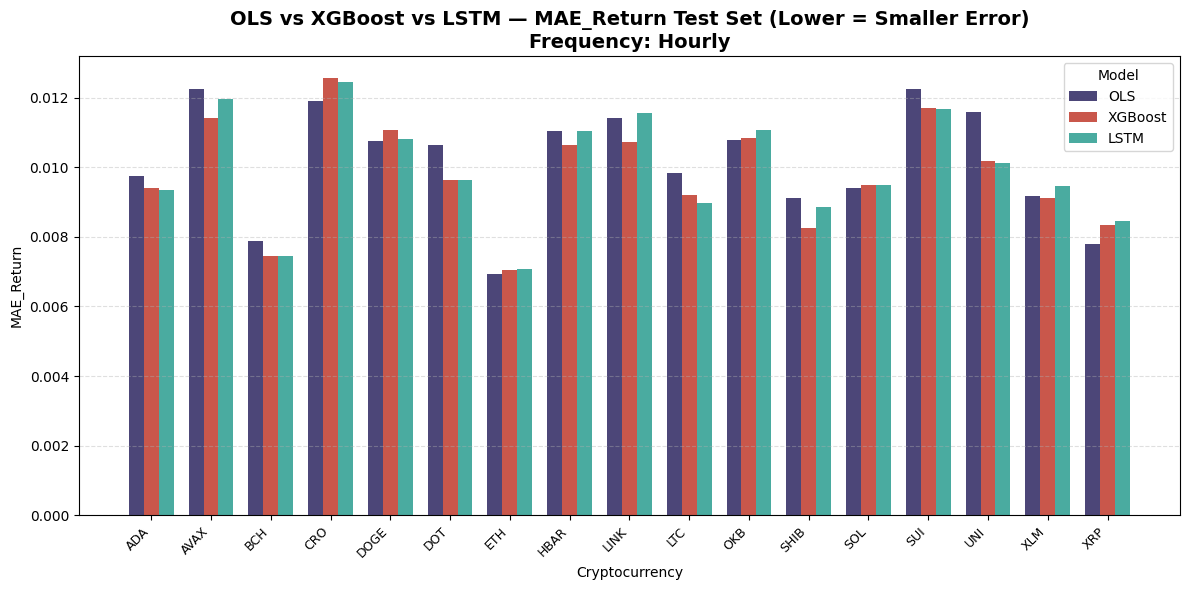

Done! Saved 'Step09_Model_Comparison_MAE_Return_Hourly_auto.png'


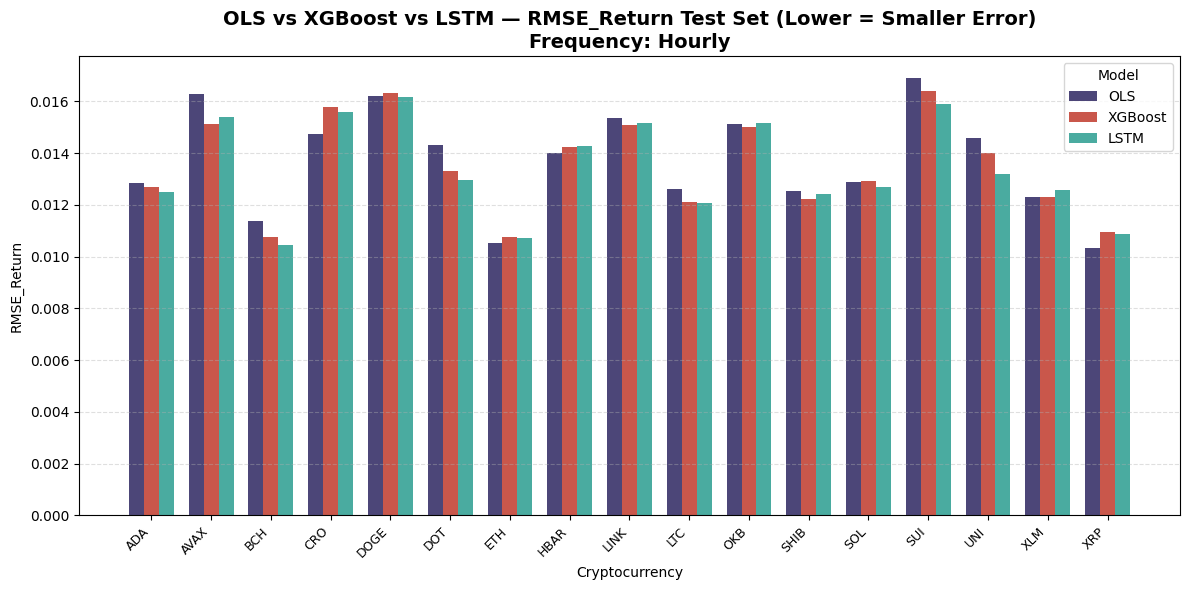

Done! Saved 'Step09_Model_Comparison_RMSE_Return_Hourly_auto.png'


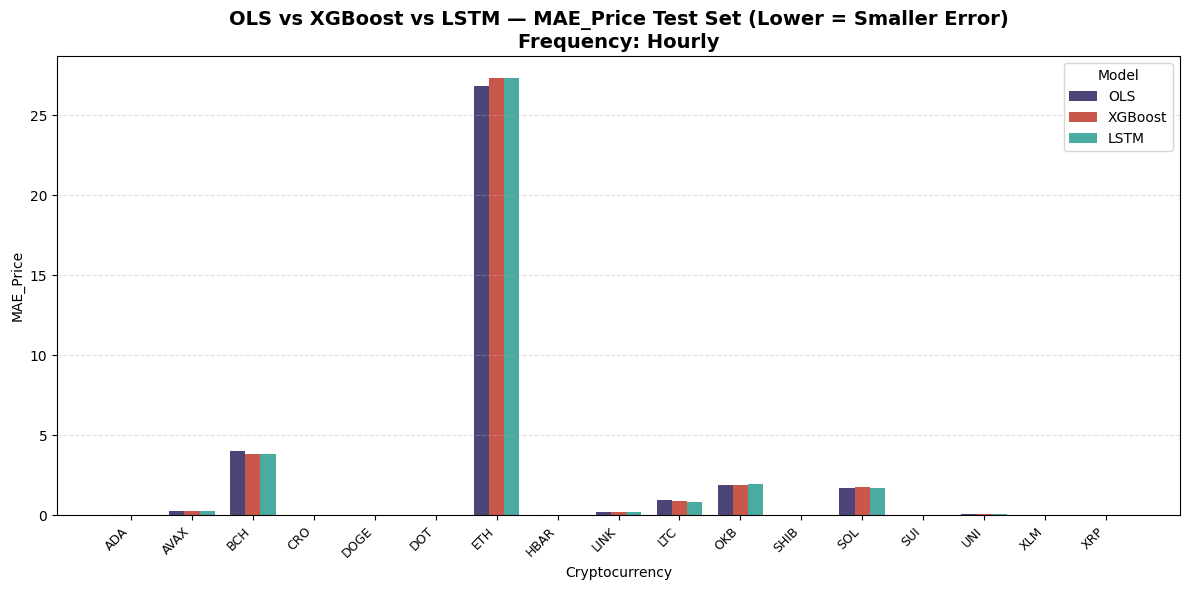

Done! Saved 'Step09_Model_Comparison_MAE_Price_Hourly_auto.png'


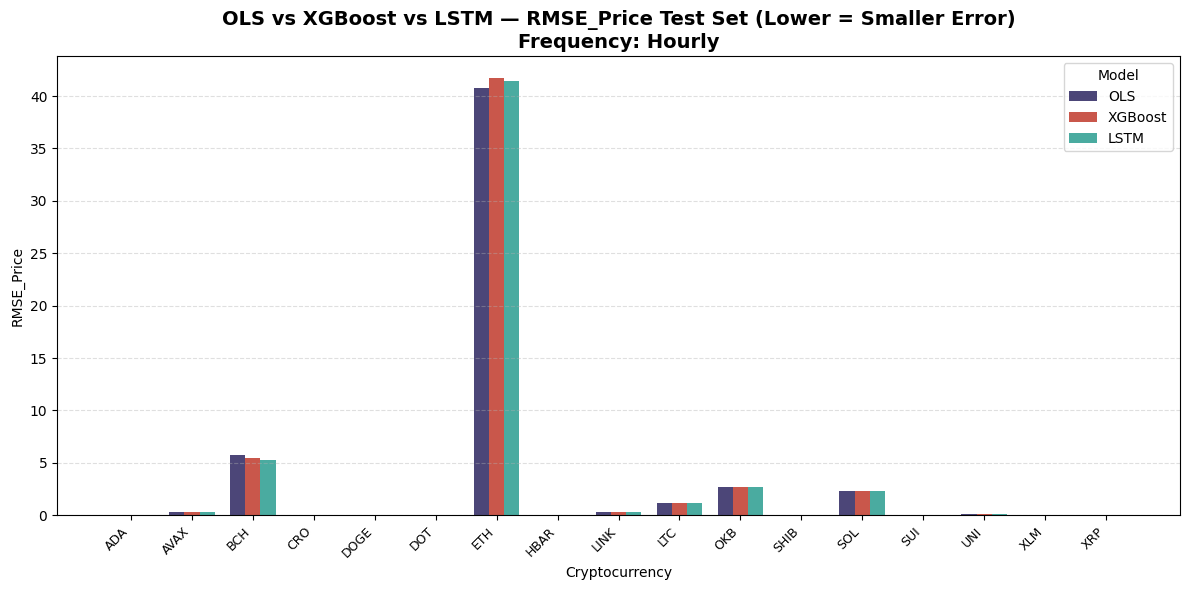

Done! Saved 'Step09_Model_Comparison_RMSE_Price_Hourly_auto.png'


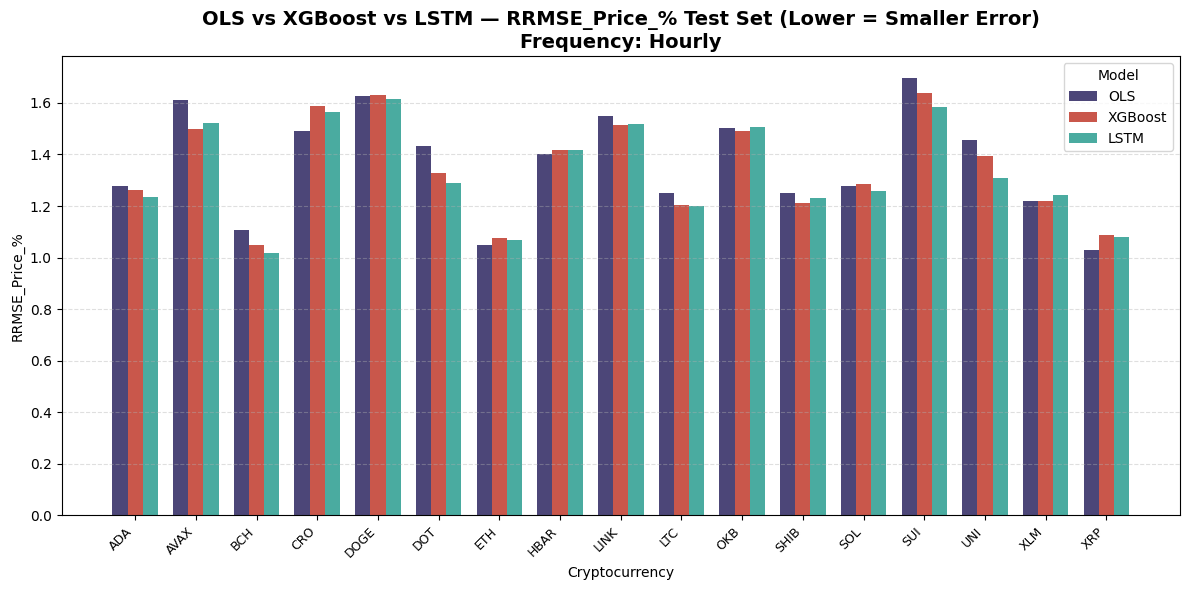

Done! Saved 'Step09_Model_Comparison_RRMSE_Price_pct_Hourly_auto.png'
--- Step 09b: Baseline Comparison | Frequency: Hourly ---

สรุปรายโมเดล (Skill > 0 = ดีกว่า Baseline | R2_OOS < 0 = แย่กว่าการทายค่าเฉลี่ย):
         N_Coins  Coins_Beat_Zero_MAE  Coins_Beat_Zero_RMSE  Mean_Skill_MAE  Mean_Skill_RMSE  Mean_R2_OOS
Model                                                                                                    
OLS           17                    2                     2         -0.0699          -0.0390      -0.0308
XGBoost       17                    0                     0         -0.0361          -0.0262      -0.0038
LSTM          17                    1                     4         -0.0505          -0.0174       0.0127

【ตาราง 13c: เปรียบเทียบกับ Baseline (ทาย 0 / ทายค่าเฉลี่ย)】  51 แถว → Table_T13c_Baseline_Comparison_Hourly_auto.csv  (ไม่แสดงในหน้านี้เพราะยาว — ดูในไฟล์ CSV/Excel)



In [32]:
print(f"--- Step 09: Model Comparison | Frequency: {FREQUENCY} ---")
print("(OLS/XGBoost พยากรณ์แยกทีละเหรียญ ส่วน LSTM เป็น Pooled Model ที่เทรนรวมทุกเหรียญ — ทั้งสามใช้ช่วง Test เดียวกัน)")
print("สเกล Log Return : MAE, RMSE ของ r_(t+1)")
print(f"สเกลราคาจริง    : MAE, RMSE (หน่วยราคา) และ Relative RMSE (%) [{RRMSE_METHOD}] จาก P̂_(t+1) = P_t × exp(r̂_(t+1))")
print("  → MAE/RMSE ของราคามีหน่วยตามราคาเหรียญ เทียบข้ามเหรียญตรงๆ ไม่ได้ ให้เทียบข้ามเหรียญด้วย Relative RMSE (%)")
print("ค่าน้อยกว่า = Error ต่ำกว่า\n")

models_list = ['OLS', 'XGBoost', 'LSTM']
model_sources = {'OLS': ols_summary_df, 'XGBoost': xgb_summary_df, 'LSTM': lstm_summary_df}
model_prefix = {'OLS': 'OLS', 'XGBoost': 'XGB', 'LSTM': 'LSTM'}

compare_df = (ols_summary_df[['OLS_MAE_Test', 'OLS_RMSE_Test']]
              .join(xgb_summary_df[['XGB_MAE_Test', 'XGB_RMSE_Test']], how='inner')
              .join(lstm_summary_df[['LSTM_MAE_Test', 'LSTM_RMSE_Test']], how='inner'))

coins_all = sorted(set().union(*[set(df.index) for df in model_sources.values()]))
compare_rows, missing_pairs, mismatches = [], [], []
nan_row = {'MAE_Return': np.nan, 'RMSE_Return': np.nan, 'MAE_Price': np.nan, 'RMSE_Price': np.nan, 'RRMSE_Price_%': np.nan}
for coin in coins_all:
    for mname in models_list:
        sdf, pf = model_sources[mname], model_prefix[mname]
        if coin in sdf.index and coin in pred_store[mname]:
            pf_df = pred_store[mname][coin]
            mae_r, rmse_r = mae_rmse(pf_df['y_true'], pf_df['y_pred'])
            mae_p, rmse_p, rrmse_p = price_metrics(coin, pf_df)
            if abs(mae_r - float(sdf.loc[coin, f'{pf}_MAE_Test'])) > 1e-6 or abs(rmse_r - float(sdf.loc[coin, f'{pf}_RMSE_Test'])) > 1e-6:
                mismatches.append((coin, mname))
            compare_rows.append({'Frequency': FREQUENCY, 'Coin': coin, 'Model': mname, 'MAE_Return': mae_r, 'RMSE_Return': rmse_r,
                                 'MAE_Price': mae_p, 'RMSE_Price': rmse_p, 'RRMSE_Price_%': rrmse_p})
        else:
            missing_pairs.append((coin, mname))
            compare_rows.append({'Frequency': FREQUENCY, 'Coin': coin, 'Model': mname, **nan_row})
compare_long = pd.DataFrame(compare_rows)
compare_long.to_csv(f'Step09_Model_Comparison{MODE_TAG}.csv', index=False)

if missing_pairs:
    print(f"มี {len(missing_pairs)} คู่ (เหรียญ, โมเดล) ที่ไม่มีผลประเมิน (แสดงเป็น NaN ไม่แทนด้วยศูนย์): {missing_pairs[:12]}{' ...' if len(missing_pairs) > 12 else ''}")
if mismatches:
    print(f"ตัวเลขใน Step 07/08/08d ไม่ตรงกับชุดพยากรณ์ที่ใช้วาดกราฟ: {mismatches}")
else:
    print("ตรวจสอบแล้ว: ตัวเลข MAE/RMSE ในตารางตรงกับชุดพยากรณ์เดียวกับที่ใช้วาดกราฟ")

metric_cols = ['MAE_Return', 'RMSE_Return', 'MAE_Price', 'RMSE_Price', 'RRMSE_Price_%']
print(f"\nFrequency = {FREQUENCY}   (เหรียญที่มีผลอย่างน้อย 1 โมเดล: {len(coins_all)} | มีผลครบ 3 โมเดล: {len(compare_df)})")
print(compare_long[['Coin', 'Model'] + metric_cols].round(6).to_string(index=False))
print(f"\nค่าเฉลี่ยรวมทุกเหรียญ (Test Set) — Frequency: {FREQUENCY}   (MAE/RMSE ของราคาเฉลี่ยข้ามเหรียญเพื่อดูภาพรวมเท่านั้น)")
print(compare_long.groupby('Model')[metric_cols].mean().reindex(models_list).round(6).to_string())
print(f"\nสำเร็จ! บันทึกตารางเปรียบเทียบลงใน 'Step09_Model_Comparison{MODE_TAG}.csv' แล้ว")

def _lowest(row, cols):
    vals = row[cols].astype(float)
    return models_list[int(np.nanargmin(vals.values))] if vals.notna().any() else 'N/A'


try:
    t13 = pd.DataFrame({'Cryptocurrency': coins_all})
    for m in models_list:
        sub = compare_long[compare_long['Model'] == m].set_index('Coin')
        t13[f'MAE_{m}'] = t13['Cryptocurrency'].map(sub['MAE_Return'])
        t13[f'RMSE_{m}'] = t13['Cryptocurrency'].map(sub['RMSE_Return'])
    _mae_c, _rmse_c = [f'MAE_{m}' for m in models_list], [f'RMSE_{m}' for m in models_list]
    t13['Lowest_MAE_Model'] = t13.apply(lambda r: _lowest(r, _mae_c), axis=1)
    t13['Lowest_RMSE_Model'] = t13.apply(lambda r: _lowest(r, _rmse_c), axis=1)
    t13['N_Models_Compared'] = t13[_mae_c].notna().sum(axis=1)
    register_table('T13', t13, note='ผลจาก Test Set เท่านั้น หน่วย Log Return | โมเดลที่ต่ำสุดเลือกจากโมเดลที่มีผลของเหรียญนั้น (ดู N_Models_Compared) | ช่องว่าง/NaN = โมเดลนั้นไม่มีผลของเหรียญนั้น')
except Exception as e:
    register_unavailable('T13', f'{type(e).__name__}: {e}')

try:
    t13b = pd.DataFrame({'Cryptocurrency': coins_all})
    for m in models_list:
        sub = compare_long[compare_long['Model'] == m].set_index('Coin')
        t13b[f'MAE_Price_{m}'] = t13b['Cryptocurrency'].map(sub['MAE_Price'])
        t13b[f'RMSE_Price_{m}'] = t13b['Cryptocurrency'].map(sub['RMSE_Price'])
        t13b[f'RRMSE_Price_pct_{m}'] = t13b['Cryptocurrency'].map(sub['RRMSE_Price_%'])
    _rr_c = [f'RRMSE_Price_pct_{m}' for m in models_list]
    t13b['Lowest_RRMSE_Model'] = t13b.apply(lambda r: _lowest(r, _rr_c), axis=1)
    t13b['N_Models_Compared'] = t13b[_rr_c].notna().sum(axis=1)
    register_table('T13b', t13b, note=f'Error ในสเกลราคา (P̂_(t+1) = P_t·exp(r̂_(t+1))) | Relative RMSE (%) = RMSE ราคา ÷ ราคาจริง [{RRMSE_METHOD}] ใช้เทียบข้ามเหรียญได้ ส่วน MAE/RMSE ของราคามีหน่วยตามราคาเหรียญ')
except Exception as e:
    register_unavailable('T13b', f'{type(e).__name__}: {e}')

try:
    _piv = lambda col: compare_long.pivot(index='Coin', columns='Model', values=col)[models_list]
    _mae, _rmse, _rr = _piv('MAE_Return'), _piv('RMSE_Return'), _piv('RRMSE_Price_%')
    _common = _mae.dropna().index.intersection(_rmse.dropna().index)
    _win_mae = _mae.loc[_common].idxmin(axis=1).value_counts() if len(_common) else pd.Series(dtype=int)
    _win_rmse = _rmse.loc[_common].idxmin(axis=1).value_counts() if len(_common) else pd.Series(dtype=int)
    t14_rows = []
    for m in models_list:
        t14_rows.append({
            'Model': m, 'N_Coins_Evaluated': int(_mae[m].notna().sum()),
            'Mean_MAE_All_Available': _mae[m].mean(), 'Mean_RMSE_All_Available': _rmse[m].mean(),
            'N_Common_Coins': int(len(_common)),
            'Mean_MAE_Common': _mae.loc[_common, m].mean() if len(_common) else np.nan,
            'Mean_RMSE_Common': _rmse.loc[_common, m].mean() if len(_common) else np.nan,
            'Mean_RRMSE_Price_pct_Common': _rr.loc[_common, m].mean() if len(_common) else np.nan,
            'N_Coins_Lowest_MAE': int(_win_mae.get(m, 0)), 'N_Coins_Lowest_RMSE': int(_win_rmse.get(m, 0)),
        })
    register_table('T14', pd.DataFrame(t14_rows),
                   note=f'Mean_*_All_Available เฉลี่ยจากเหรียญที่แต่ละโมเดลมีผล (N_Coins_Evaluated) | *_Common และจำนวนเหรียญที่ต่ำสุดนับเฉพาะ {len(_common)} เหรียญที่มีผลครบทั้ง 3 โมเดล (กรณีค่าเท่ากันนับให้โมเดลแรกตามลำดับ OLS, XGBoost, LSTM) | ไม่ใช้ศูนย์แทนผลที่ขาด')
except Exception as e:
    register_unavailable('T14', f'{type(e).__name__}: {e}')
    _common = pd.Index([])

try:
    _run = {'Frequency': FREQUENCY, 'HP_MODE': HP_MODE, 'Median_Interval_Minutes': MEDIAN_INTERVAL_MINUTES,
            'Start': str(clean_data.index.min()), 'End': str(clean_data.index.max()),
            'N_Price_Rows': int(len(clean_data)), 'N_LogReturn_Rows': int(len(returns)),
            'N_Coins_Incl_BTC': int(clean_data.shape[1]), 'N_Altcoins_Tested': int(len(lag_results_df)),
            'N_Granger_Significant': int(lag_results_df['Has_Causality'].sum()),
            'Pct_Granger_Significant': 100.0 * float(lag_results_df['Has_Causality'].mean()),
            'N_Clusters': int(N_CLUSTERS),
            'KMeans_Cluster_Sizes': '; '.join(f'{k}:{v}' for k, v in alt_features['KMeans_Cluster'].value_counts().sort_index().items()),
            'Hierarchical_Cluster_Sizes': '; '.join(f'{k}:{v}' for k, v in alt_features['Hierarchical_Cluster'].value_counts().sort_index().items()),
            'N_Coins_All_Models': int(len(_common)),
            'LSTM_Lookback_Minutes': int(LSTM_LOOKBACK * BAR_MINUTES), 'Lag_Search_Start_Bars': int(MAX_LAG),
            'N_Coins_Lag_At_Boundary': int(lag_results_df['At_Max_Lag'].sum()),
            'Median_Optimal_Lag_Minutes': float(lag_results_df['Optimal_Lag_Minutes'].median())}
    for m in models_list:
        _run[f'{m}_Mean_MAE_Common'] = _mae.loc[_common, m].mean() if len(_common) else np.nan
        _run[f'{m}_Mean_RMSE_Common'] = _rmse.loc[_common, m].mean() if len(_common) else np.nan
    register_table('T15a', pd.DataFrame([_run]), note='สรุปผลของการรันครั้งนี้ในแถวเดียว ใช้รวมกับผลของ Frequency อื่นใน Step 12')
except Exception as e:
    register_unavailable('T15a', f'{type(e).__name__}: {e}')

coins = coins_all
x = np.arange(len(coins))
width = 0.25
for metric in metric_cols:
    plt.figure(figsize=(max(12, len(coins) * 0.7), 6))
    for i, model_name in enumerate(models_list):
        vals = compare_long[compare_long['Model'] == model_name].set_index('Coin').reindex(coins)[metric]
        plt.bar(x + (i - 1) * width, vals, width, label=model_name, color=MODEL_COLORS[model_name], alpha=0.85)
    plt.title(f'OLS vs XGBoost vs LSTM — {metric} Test Set (Lower = Smaller Error)\nFrequency: {FREQUENCY}', fontsize=14, fontweight='bold')
    plt.xticks(x, coins, rotation=45, ha='right', fontsize=9)
    plt.ylabel(metric)
    plt.xlabel('Cryptocurrency')
    plt.legend(title='Model')
    plt.grid(True, linestyle='--', alpha=0.4, axis='y')
    plt.tight_layout()
    safe_metric = metric.replace('%', 'pct')
    plt.savefig(f'Step09_Model_Comparison_{safe_metric}{MODE_TAG}.png', dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Done! Saved 'Step09_Model_Comparison_{safe_metric}{MODE_TAG}.png'")


print(f"--- Step 09b: Baseline Comparison | Frequency: {FREQUENCY} ---")

baseline_rows = []
for mname in ['OLS', 'XGBoost', 'LSTM']:
    for coin, fr in pred_store[mname].items():
        y_true = fr['y_true'].values.astype(float)
        if len(y_true) == 0:
            continue
        mean_dev = float(returns[coin].loc[:fr.index.min()].mean())
        mae_m, rmse_m = mae_rmse(y_true, fr['y_pred'].values)
        mae_0, rmse_0 = mae_rmse(y_true, np.zeros_like(y_true))
        mae_mu, rmse_mu = mae_rmse(y_true, np.full_like(y_true, mean_dev))
        baseline_rows.append({
            'Frequency': FREQUENCY, 'Coin': coin, 'Model': mname, 'N_Test': len(y_true),
            'MAE_Model': mae_m, 'MAE_Zero': mae_0, 'MAE_Mean': mae_mu,
            'RMSE_Model': rmse_m, 'RMSE_Zero': rmse_0, 'RMSE_Mean': rmse_mu,
            'Skill_MAE_vs_Zero': 1 - mae_m / mae_0,
            'Skill_RMSE_vs_Zero': 1 - rmse_m / rmse_0,
            'R2_OOS_vs_Mean': 1 - (rmse_m / rmse_mu) ** 2,
            'Beats_Zero_MAE': mae_m < mae_0,
            'Beats_Zero_RMSE': rmse_m < rmse_0,
        })

baseline_df = pd.DataFrame(baseline_rows)
if baseline_df.empty:
    register_unavailable('T13c', 'ไม่มีผลพยากรณ์จาก pred_store')
else:
    summary = baseline_df.groupby('Model').agg(
        N_Coins=('Coin', 'count'),
        Coins_Beat_Zero_MAE=('Beats_Zero_MAE', 'sum'),
        Coins_Beat_Zero_RMSE=('Beats_Zero_RMSE', 'sum'),
        Mean_Skill_MAE=('Skill_MAE_vs_Zero', 'mean'),
        Mean_Skill_RMSE=('Skill_RMSE_vs_Zero', 'mean'),
        Mean_R2_OOS=('R2_OOS_vs_Mean', 'mean'),
    ).reindex(['OLS', 'XGBoost', 'LSTM'])
    print("\nสรุปรายโมเดล (Skill > 0 = ดีกว่า Baseline | R2_OOS < 0 = แย่กว่าการทายค่าเฉลี่ย):")
    print(summary.round(4).to_string())
    register_table('T13c', baseline_df.round(6),
                   note='Skill = 1 - Error_โมเดล / Error_Zero | R2_OOS = 1 - (RMSE_โมเดล/RMSE_Mean)^2 | ประเมินบน Test Set เท่านั้น',
                   show=False)
print()

## Step 10: Causality network graph

--- Step 10: Generating Causality Network Graph (Clustered) ---
กำลังสร้างกราฟสำหรับ: K-Means Clustering...
กำลังสร้างกราฟสำหรับ: Hierarchical Clustering...


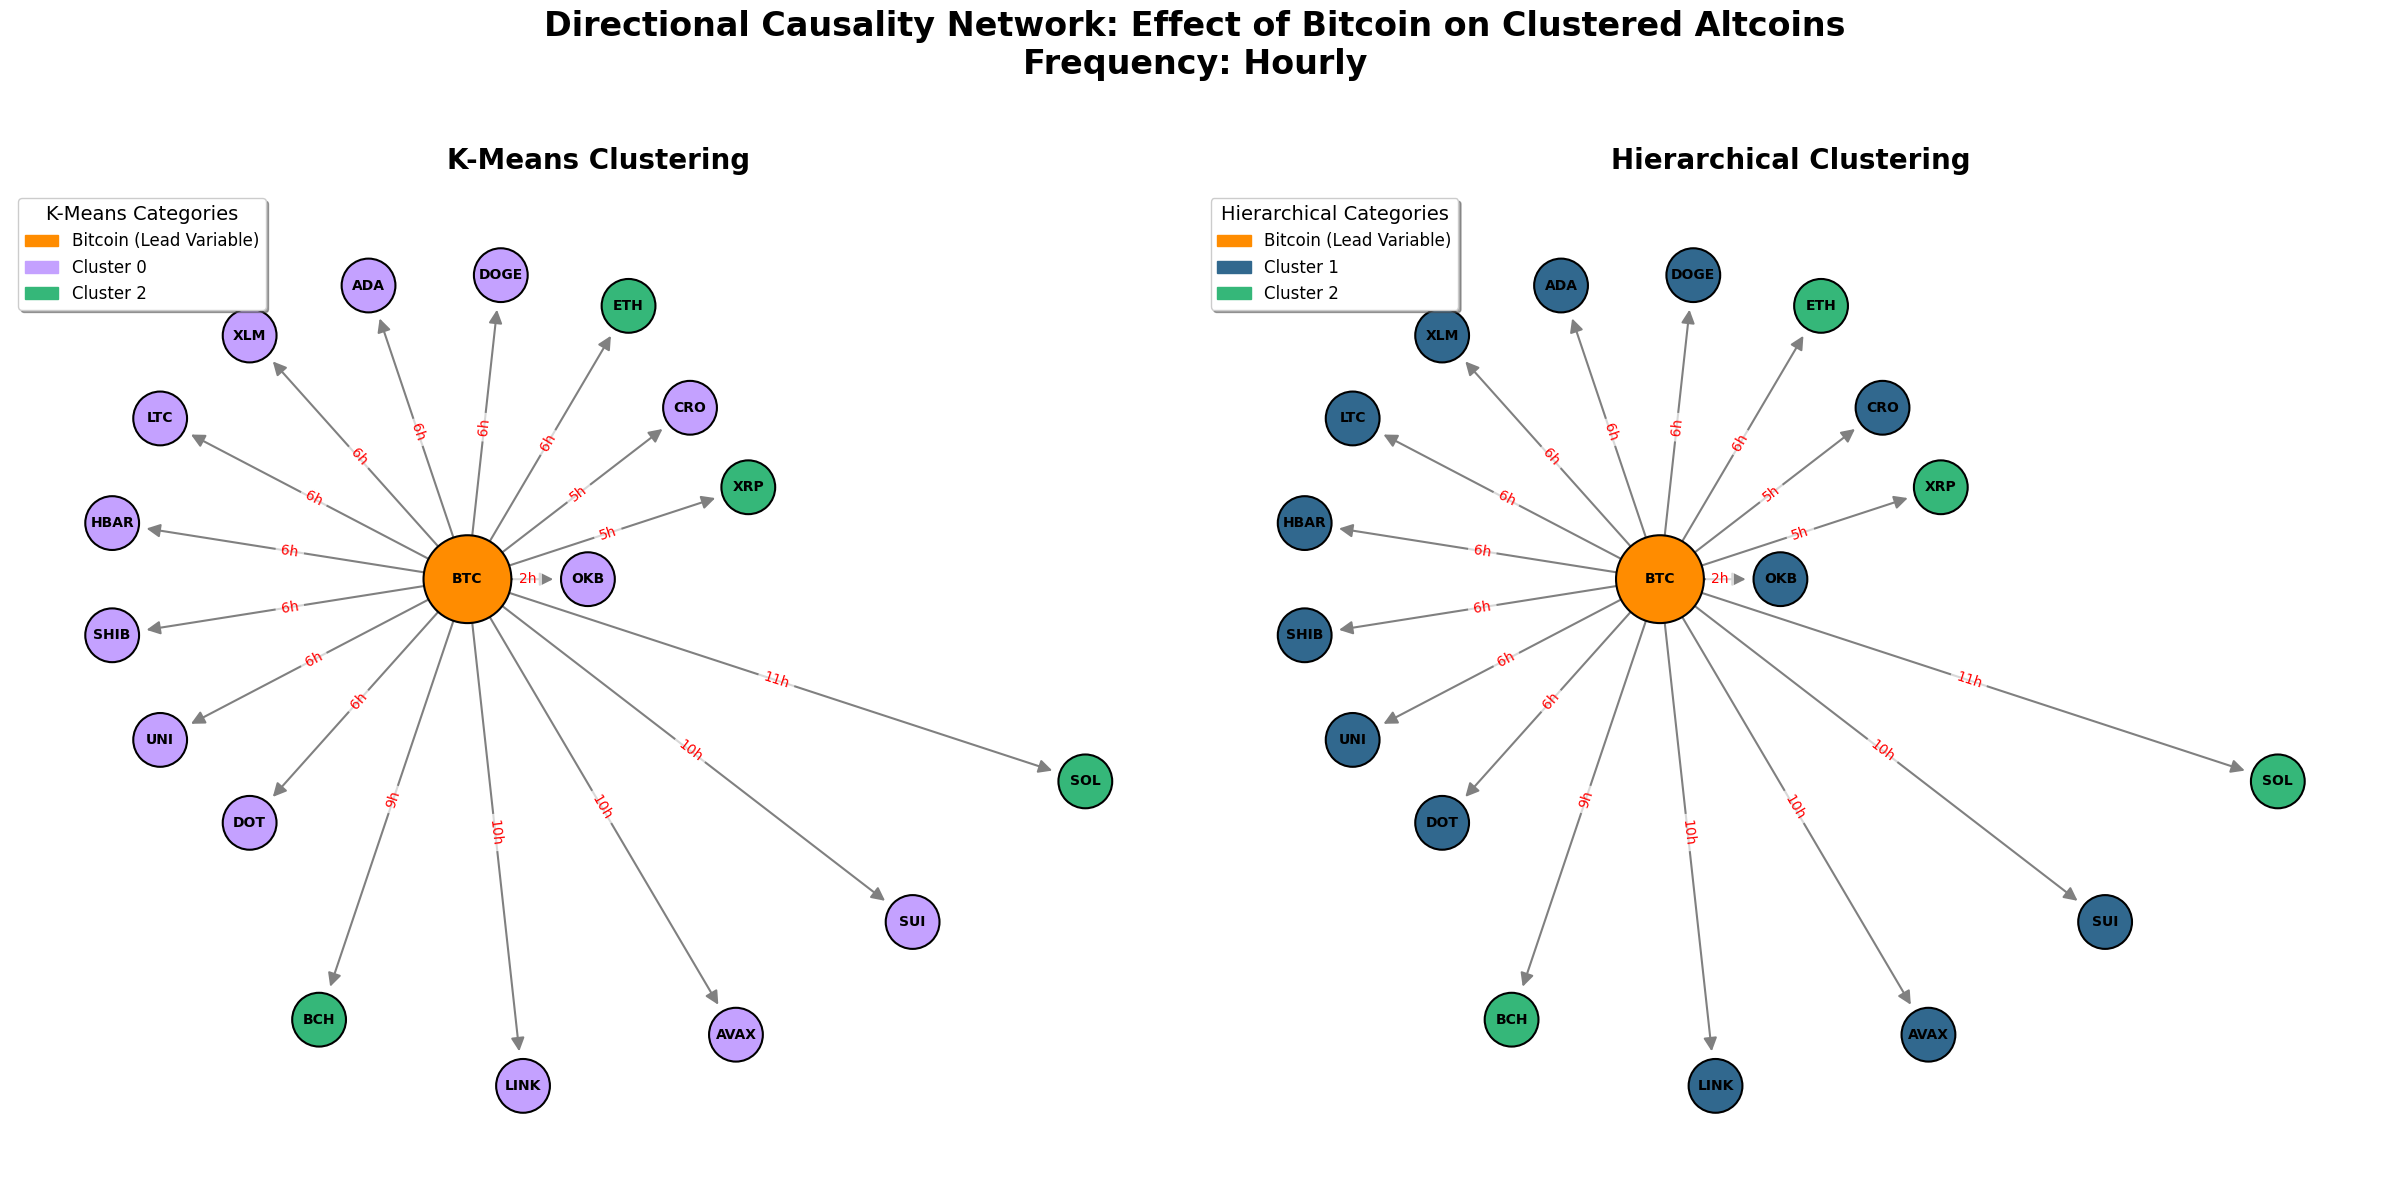

บันทึกรูปภาพสำเร็จ: Step10_Combined_Causality_Network_Hourly.png


In [33]:
print("--- Step 10: Generating Causality Network Graph (Clustered) ---")

edges_data = final_results[final_results['Has_Causality']]

color_palette = {
    'BTC': 'darkorange',
    0: '#C4A1FF',
    1: '#31688e',
    2: '#35b779',
    3: '#fde725'
}
clustering_methods = {'KMeans_Cluster': 'K-Means', 'Hierarchical_Cluster': 'Hierarchical'}

fig, axes = plt.subplots(1, 2, figsize=(24, 12))
fig.suptitle(f"Directional Causality Network: Effect of Bitcoin on Clustered Altcoins\nFrequency: {FREQUENCY}",
             fontsize=24, fontweight='bold', y=0.98)

for ax, (method_col, method_name) in zip(axes, clustering_methods.items()):
    print(f"กำลังสร้างกราฟสำหรับ: {method_name} Clustering...")

    G = nx.DiGraph()
    G.add_node('BTC', size=4000, cluster='BTC')
    for coin, row in edges_data.iterrows():
        lag = int(row['Optimal_Lag_AIC'])
        G.add_node(coin, size=1500, cluster=row[method_col])
        G.add_edge('BTC', coin, weight=lag, label=f"{lag}{PERIOD_ABBR}")

    node_colors = [color_palette.get(G.nodes[n]['cluster'], 'lightgray') for n in G.nodes()]
    node_sizes = [G.nodes[n]['size'] for n in G.nodes()]

    pos = {'BTC': (0, 0)}
    altcoins_by_lag = sorted(
        [(coin, G.edges['BTC', coin]['weight']) for coin in G.nodes() if coin != 'BTC'],
        key=lambda x: x[1]
    )
    num_altcoins = len(altcoins_by_lag)
    for i, (coin, lag) in enumerate(altcoins_by_lag):
        distance = lag * 2.0 if lag > 0 else 1.0
        angle = i * (2 * math.pi / num_altcoins)
        pos[coin] = (distance * math.cos(angle), distance * math.sin(angle))

    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes,
                            edgecolors='black', linewidths=1.5, ax=ax)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=20, width=1.5,
                            min_source_margin=25, min_target_margin=25, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold', ax=ax)
    edge_labels = nx.get_edge_attributes(G, 'label')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=10, font_color='red',
                                  bbox=dict(facecolor='white', edgecolor='none', alpha=0.7), ax=ax)

    legend_handles = [mpatches.Patch(color=color_palette['BTC'], label='Bitcoin (Lead Variable)')]
    for cluster_id in sorted(edges_data[method_col].unique()):
        legend_handles.append(mpatches.Patch(color=color_palette.get(cluster_id, 'lightgray'),
                                              label=f'Cluster {cluster_id}'))
    ax.legend(handles=legend_handles, loc='upper left', fontsize=12, title=f'{method_name} Categories',
              title_fontsize=14, frameon=True, shadow=True)

    ax.set_title(f"{method_name} Clustering", fontsize=20, fontweight='bold', pad=15)
    ax.axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(f'Step10_Combined_Causality_Network{FREQ_TAG}.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f"บันทึกรูปภาพสำเร็จ: Step10_Combined_Causality_Network{FREQ_TAG}.png")

## Step 11: Summary

In [34]:
print("=" * 65)
print("   EXECUTIVE SUMMARY".center(65))
print("=" * 65)

print(f"\n[ข้อมูล]")
print(f"  Frequency    : {FREQUENCY} (Median Interval = {MEDIAN_INTERVAL_MINUTES:.2f} minutes)")
print(f"  ช่วงเวลา (Full Dataset) : {clean_data.index.min()} ถึง {clean_data.index.max()}")
if SELECTED_PERIOD is not None:
    print(f"  Selected Period (ใช้แสดงผล/Visualization) : {SELECTED_PERIOD[0]} ถึง {SELECTED_PERIOD[1]}")
print(f"  จำนวนแท่งข้อมูล : {clean_data.shape[0]} แท่ง")
print(f"  จำนวนเหรียญ   : {len(altcoins)} altcoins (ไม่รวม BTC)")
print(f"  เป้าหมายพยากรณ์ : X_t → r_(t+1)   |   Split: Train {TRAIN_RATIO:.0%} / Validation {VAL_RATIO:.0%} / Test {1 - TRAIN_RATIO - VAL_RATIO:.0%} (Chronological)")

better_cluster_method = "K-Means" if sil_kmeans_final > sil_hierarchical_final else "Hierarchical"
print(f"\n[Clustering]")
print(f"  K-Means      : K = {best_k_kmeans} (กำหนด)  (Silhouette = {sil_kmeans_final:.4f})")
print(f"  Hierarchical : K = {best_k_hierarchical} (กำหนด)  (Silhouette = {sil_hierarchical_final:.4f})")
print(f"  → วิธีที่แบ่งกลุ่มได้ชัดเจนกว่า: {better_cluster_method}")

num_causal = final_results['Has_Causality'].sum()
causal_pct = num_causal / len(final_results) * 100
avg_lag_causal = final_results.loc[final_results['Has_Causality'], 'Optimal_Lag_AIC'].mean()
print(f"\n[Directional Causality: BTC → Altcoins | Frequency: {FREQUENCY}]")
print(f"  เหรียญที่ได้รับผลกระทบจาก BTC อย่างมีนัยสำคัญ (p < {ALPHA}): {num_causal}/{len(final_results)} เหรียญ ({causal_pct:.1f}%)")
print(f"  Lag เฉลี่ยของเหรียญที่มี Causality: {avg_lag_causal:.2f} {PERIOD_LABEL}(s)")

err_cols = ['MAE_Return', 'RMSE_Return', 'MAE_Price', 'RMSE_Price', 'RRMSE_Price_%']
mean_error_table = compare_long.groupby('Model')[err_cols].mean().reindex(['OLS', 'XGBoost', 'LSTM'])
print(f"\n[Predictive Modeling: OLS vs XGBoost vs LSTM | Frequency: {FREQUENCY} | HP_MODE: {HP_MODE}]")
print(f"  ตัวแปรต้น: Lag ของ Log Return (BTC และเหรียญเอง) | เป้าหมาย: r_(t+1)")
print(f"  ค่าเฉลี่ย Error ของ {len(compare_df)} เหรียญ (Test Set):")
print("  " + mean_error_table.round(6).to_string().replace("\n", "\n  "))
print("  (MAE/RMSE ของราคาเฉลี่ยข้ามเหรียญเพื่อดูภาพรวมเท่านั้น — เทียบข้ามเหรียญให้ใช้ Relative RMSE %)")

rep_source = compare_df.join(final_results[['KMeans_Cluster', 'Hierarchical_Cluster']], how='inner')
print(f"\n[เหรียญแนะนำสำหรับ Highlight ในการนำเสนอ — ตัวแทนแต่ละ Cluster (K-Means)]")
for cluster_id in sorted(final_results['KMeans_Cluster'].unique()):
    cluster_coins = rep_source[rep_source['KMeans_Cluster'] == cluster_id]
    if len(cluster_coins) == 0:
        total_in_cluster = (final_results['KMeans_Cluster'] == cluster_id).sum()
        print(f"  Cluster {cluster_id}: — ไม่มีเหรียญที่ BTC มี Causality อย่างมีนัยสำคัญในกลุ่มนี้เลย ({total_in_cluster} เหรียญในกลุ่ม, ไม่ผ่านเกณฑ์คัดกรองทั้งหมด)")
        continue
    top_coin = cluster_coins['XGB_MAE_Test'].idxmin()
    print(f"  Cluster {cluster_id}: {top_coin}  (XGBoost MAE Test = {cluster_coins.loc[top_coin, 'XGB_MAE_Test']:.6f}, "
          f"{len(cluster_coins)}/{(final_results['KMeans_Cluster'] == cluster_id).sum()} เหรียญในกลุ่มที่มี Causality)")

print("\n" + "=" * 65)
print("  ไฟล์สรุปผลทั้งหมด (CSV):")
print(f"   - Step02_ClusteringResults{FREQ_TAG}.csv   (ผล Clustering รายเหรียญ)")
print(f"   - Step03_CausalityOptimalLags{FREQ_TAG}.csv (ผล Granger Causality + Optimal Lag)")
print(f"   - Step04_MergedResults{FREQ_TAG}.csv        (Clustering + Causality รวมกัน)")
print(f"   - Step07_OLS_Metrics_Summary{MODE_TAG}.csv  (ผล OLS ทุกเหรียญ)")
print(f"   - Step08_XGBoost_Metrics_Summary{MODE_TAG}.csv (ผล XGBoost ทุกเหรียญ)")
print(f"   - Step08c_LSTM_Metrics_Summary{MODE_TAG}.csv (ผล LSTM ทุกเหรียญ, Pooled Model)")
print(f"   - Step08c_LSTM_Tuning_Results{MODE_TAG}.csv  (ผลการเลือก Hyperparameter ของ LSTM: Auto vs Manual)")
print(f"   - Step09_Model_Comparison{MODE_TAG}.csv     (เปรียบเทียบ OLS vs XGBoost vs LSTM: Error ของ Log Return และราคาจริง)")
print("=" * 65)

                          EXECUTIVE SUMMARY                      

[ข้อมูล]
  Frequency    : Hourly (Median Interval = 60.00 minutes)
  ช่วงเวลา (Full Dataset) : 2025-10-06 00:00:00 ถึง 2025-10-12 23:00:00
  จำนวนแท่งข้อมูล : 168 แท่ง
  จำนวนเหรียญ   : 21 altcoins (ไม่รวม BTC)
  เป้าหมายพยากรณ์ : X_t → r_(t+1)   |   Split: Train 60% / Validation 20% / Test 20% (Chronological)

[Clustering]
  K-Means      : K = 3 (กำหนด)  (Silhouette = 0.4673)
  Hierarchical : K = 3 (กำหนด)  (Silhouette = 0.4673)
  → วิธีที่แบ่งกลุ่มได้ชัดเจนกว่า: Hierarchical

[Directional Causality: BTC → Altcoins | Frequency: Hourly]
  เหรียญที่ได้รับผลกระทบจาก BTC อย่างมีนัยสำคัญ (p < 0.05): 17/21 เหรียญ (81.0%)
  Lag เฉลี่ยของเหรียญที่มี Causality: 6.82 hour(s)

[Predictive Modeling: OLS vs XGBoost vs LSTM | Frequency: Hourly | HP_MODE: auto]
  ตัวแปรต้น: Lag ของ Log Return (BTC และเหรียญเอง) | เป้าหมาย: r_(t+1)
  ค่าเฉลี่ย Error ของ 17 เหรียญ (Test Set):
           MAE_Return  RMSE_Return  MAE_Price  RMSE_Price  R

## Step 12: Hourly vs minute comparison

In [35]:
print(f"--- Step 12: Hourly vs Minute Comparison ---")
try:
    run_files = sorted(glob.glob('Table_T15a_Run_Summary_*.csv'))
    runs = []
    for _f in dict.fromkeys(os.path.abspath(f) for f in run_files):
        _r = pd.read_csv(_f)
        _r['Source_File'] = os.path.basename(_f)
        _r['File_Modified'] = pd.Timestamp(os.path.getmtime(_f), unit='s').strftime('%Y-%m-%d %H:%M')
        runs.append(_r)
    if not runs:
        register_unavailable('T15', 'ไม่พบไฟล์ Run Summary — ต้องรันขั้นตอน Step 09 ให้สำเร็จก่อน')
    else:
        runs_df = pd.concat(runs, ignore_index=True).sort_values('File_Modified').drop_duplicates(['Frequency', 'HP_MODE'], keep='last')
        freqs_found = sorted(runs_df['Frequency'].unique())
        print(f"พบผลของความถี่: {freqs_found} | ชุดการรัน: {runs_df[['Frequency', 'HP_MODE', 'File_Modified']].values.tolist()}")
        if len(freqs_found) < 2:
            register_unavailable('T15', f"พบผลของความถี่เดียว ({freqs_found[0]}) — ต้องรัน Notebook กับไฟล์ข้อมูลอีกความถี่ (Hourly/Minute) แล้วรันเซลล์นี้ซ้ำ "
                                        "โค้ดไม่สร้างผลของความถี่ที่ยังไม่ได้รัน")
        else:
            runs_df['Run'] = runs_df['Frequency'] + ' (' + runs_df['HP_MODE'] + ')'
            t15 = runs_df.drop(columns=['Frequency', 'HP_MODE']).set_index('Run').T
            t15.index.name = 'Metric'
            register_table('T15', t15.reset_index(),
                           note='คอลัมน์ = การรันแต่ละครั้ง (Frequency + HP_MODE) | ตรวจ File_Modified/Source_File ว่าเป็นผลจากการรันที่ต้องการ | Error เทียบเฉพาะเหรียญที่มีผลครบ 3 โมเดลของแต่ละการรัน (N_Coins_All_Models) ซึ่งอาจเป็นชุดเหรียญต่างกันระหว่างความถี่')
except Exception as e:
    register_unavailable('T15', f'{type(e).__name__}: {e}')

--- Step 12: Hourly vs Minute Comparison ---
พบผลของความถี่: ['Hourly'] | ชุดการรัน: [['Hourly', 'auto', '2026-11-10 12:26']]

⚠️ [ตาราง 15: Hourly vs Minute Comparison] สร้างไม่ได้: พบผลของความถี่เดียว (Hourly) — ต้องรัน Notebook กับไฟล์ข้อมูลอีกความถี่ (Hourly/Minute) แล้วรันเซลล์นี้ซ้ำ โค้ดไม่สร้างผลของความถี่ที่ยังไม่ได้รัน  (ไม่มีการสร้างข้อมูลทดแทน)


## Step 13: Export report tables

In [36]:
print(f"--- Step 13: Export Report Tables | Frequency: {FREQUENCY} | HP_MODE: {HP_MODE} ---")

excel_path = os.path.abspath(f'Report_Tables{MODE_TAG}.xlsx')
status_rows = [{'Table': k, 'Title': v['title'], 'Status': v['status'], 'Rows': v['rows'],
                'CSV_File': os.path.basename(v['file']) if v['file'] else '', 'Reason_if_not_created': v['reason']}
               for k, v in TABLE_STATUS.items()]
status_df = pd.DataFrame(status_rows)
excel_status = ''
try:
    with pd.ExcelWriter(excel_path, engine='openpyxl') as xw:
        status_df.to_excel(xw, sheet_name='Index', index=False)
        sheet_names = {'Index': status_df}
        for key in [k for k in PLANNED_TABLES if k in REPORT_TABLES]:
            tdf = REPORT_TABLES[key]
            sname = f"{key}_{PLANNED_TABLES[key][0]}"[:31]
            tdf.to_excel(xw, sheet_name=sname, index=False)
            sheet_names[sname] = tdf
        from openpyxl.styles import Font, PatternFill
        for sname, tdf in sheet_names.items():
            ws = xw.book[sname]
            ws.freeze_panes = 'A2'
            for cell in ws[1]:
                cell.font = Font(bold=True)
                cell.fill = PatternFill('solid', fgColor='DDE6F0')
            for j, col in enumerate(tdf.columns, start=1):
                width = min(60, max(len(str(col)), int(tdf[col].astype(str).str.len().quantile(0.9)) if len(tdf) else 8) + 2)
                ws.column_dimensions[ws.cell(row=1, column=j).column_letter].width = width
                if pd.api.types.is_float_dtype(tdf[col]):
                    fmt = '0.000000' if (tdf[col].abs().max() < 1) else '#,##0.0000'
                    for r in range(2, len(tdf) + 2):
                        ws.cell(row=r, column=j).number_format = fmt
    excel_status = f'บันทึกแล้ว: {excel_path}'
except ImportError:
    excel_status = 'ไม่สำเร็จ: ไม่พบไลบรารี openpyxl (ติดตั้งด้วย pip install openpyxl) — ไฟล์ CSV ของแต่ละตารางยังถูกบันทึกแล้ว'
except Exception as e:
    excel_status = f'ไม่สำเร็จ: {type(e).__name__}: {e} — ไฟล์ CSV ของแต่ละตารางยังถูกบันทึกแล้ว'

n_ok = int((status_df['Status'] == 'Created').sum())
print("=" * 78)
print("  สรุปตารางสำหรับรายงาน".center(78))
print("=" * 78)
print(status_df[['Table', 'Title', 'Status', 'Rows', 'CSV_File']].to_string(index=False))
failed = status_df[status_df['Status'] != 'Created']
if len(failed):
    print("\nตารางที่ยังสร้างไม่ได้และเหตุผล:")
    for _, r in failed.iterrows():
        print(f"  - {r['Table']} {r['Title']}: {r['Reason_if_not_created']}")
print(f"\nสร้างสำเร็จ {n_ok}/{len(status_df)} ตาราง | Excel: {excel_status}")
print(f"โฟลเดอร์ที่บันทึกผล: {os.getcwd()}")
if USE_CHECKPOINT and CKPT_CHDIR_TO_OUTPUT:
    print(f"(Checkpoint: {CKPT.root})")
else:
    print("(ผลลัพธ์ถูกบันทึกในโฟลเดอร์ทำงานปัจจุบัน)")
print("=" * 78)

--- Step 13: Export Report Tables | Frequency: Hourly | HP_MODE: auto ---
                             สรุปตารางสำหรับรายงาน                            
Table                                                                  Title      Status  Rows                                                CSV_File
  T01                                               ตาราง 1: Dataset Summary     Created    18                    Table_T01_Dataset_Summary_Hourly.csv
  T02                           ตาราง 2: Descriptive Statistics (Log Return)     Created    22             Table_T02_Descriptive_Statistics_Hourly.csv
  T03                                       ตาราง 3: Stationarity Test (ADF)     Created    44                  Table_T03_Stationarity_Test_Hourly.csv
  T04                                           ตาราง 4: Clustering Features     Created    21                Table_T04_Clustering_Features_Hourly.csv
  T05                                   ตาราง 5: Silhouette Score Comparison     Created    

## Checkpoint status

In [37]:
if USE_CHECKPOINT:
    display(CKPT.status())

,Stage,Folder,Items,Size_MB,Last_Modified,In_Use_This_Session
0,step03_example_lag_table,step03_example_lag_table__0ce3346c4374,1,0.00,2026-11-10 12:24,✓
1,step03_granger,step03_granger__5d00f281aacd,21,0.03,2026-11-10 12:24,✓
2,step06_ols_lag_selection,step06_ols_lag_selection__dab6ce3f6530,17,0.00,2026-11-10 12:24,✓
3,step07_ols,step07_ols__c8d12592365d,17,0.05,2026-11-10 12:24,✓
4,step07b_xgb_tuning,step07b_xgb_tuning__7d51633484ec,2,0.00,2026-11-10 12:24,✓
5,step08_xgboost,step08_xgboost__6ba84cf303fe,17,0.03,2026-11-10 12:24,✓
6,step08c_lstm_tuning,step08c_lstm_tuning__eec260f9f81a,12,0.00,2026-11-10 12:25,✓
7,step08d_lstm_final,step08d_lstm_final__d9e3d406bdff,2,0.03,2026-11-10 12:25,✓
